# Reaction diagrams from rxflow results

Set `DB_PATH` to a reaction database. The notebook also reads `precursors.sqlite` beside it and the shared `solution_references/references.sqlite` (both paths can be overridden below). Rerun all cells to pick up newly completed calculations. All databases are opened read-only. `ENERGY_MODE = "auto"` also checks `singlepoints.sqlite` in the run and shared-reference directories.

The extended diagram follows **protonated ligand–metal complex + fully protonated free substrate + acetate → deprotonated ligand–metal complex + free substrate + acetic acid → bound reactant + acetic acid → TS + acetic acid → proton-transfer product + acetic acid**. “LM” means the ligand–metal complex; AcOH means acetic acid. Each state has total charge +1 and the same atoms. The substrate is already inside the bound reactant, TS and product, so it is added separately only to the first two states. The ligand-deprotonation step is a thermodynamic difference; no acetate-mediated deprotonation TS was calculated.

For each ligand, the zero is the **lowest completed protonated LM + substrate + acetate total across its recorded binding permutations and native protonation sites**. Every site and pathway for that ligand uses this same absolute reference. If no protonated starting total is available, the notebook explicitly falls back to the lowest bound reactant + acetic acid. If acetic acid is not available at all, it shows the original reactant–TS–product diagram relative to the lowest reactant; it never mixes unbalanced and acid-balanced totals. Missing precursor levels remain blank and no line is drawn across a missing level.

Each species/state uses its lowest **successful NumFreq Gibbs energy**, including conformers outside the electronic-energy retained set. Pending and failed candidates do not erase completed results; results may improve while jobs finish. Tables list the chosen job/conformer, absolute energy, job statuses and any missing inputs outside the plot. Energies on the diagram are in kcal/mol. They use the existing ORCA thermochemistry convention without an additional solution standard-state or concentration correction.

Coverage tables include every recorded substrate site. Expected permutations are the union recorded for that ligand in the reaction database; arrangements removed before preparation and ligands absent from the database are outside this count. Coverage counts complete reactant–TS–product pathways independently of precursor readiness. Every complete reaction pair/resonance remains separate, even if several routes share a precursor energy. Native ligand protonation sites are also kept separate if more than one is recorded; the TS H-acceptor does not select a precursor protonation site.

Energy plots have no text or numerical annotations inside the axes, and legends sit outside. Below each plot, RDKit draws each reaction pathway's ligand: **blue** highlights metal-binding atoms, **red** the actual TS H-acceptor, and **purple** their overlap. The notebook also renders the lowest-reactant pathway's optimized structures.

The proton-transfer barriers are **forward = G(TS) − G(bound reactant)** and **reverse = G(TS) − G(bound product)**. A pathway qualifies only if **both are ≤ 25 kcal/mol**, using the unrounded energies. Distinct, contrasting plot colors identify each substrate site and barrier class; qualifying pathways are listed in a separate report. Every plot legend and ligand-grid caption includes both barrier values. Tables have no colored shading, and ligand-grid captions use black text. The grid section headings identify pathways passing both limits; the plot legends give the barriers without a threshold tag. The blue/red/purple atom highlights retain their chemical meaning. These barriers refer to the bound proton-transfer step, independently of the preceding ligand deprotonation and substrate association.

**DFT single-point correction:** `rxflow singlepoint` calculates PBE0/def2-TZVP-D4 with SMD(water) on the selected gxTB geometries. For each component, the plotted correction is **G(corrected) = G(gxTB NumFreq) − E(gxTB NumFreq) + E(PBE0-D4/SMD)**. The electronic and Gibbs gxTB energies must belong to the same saved geometry and NumFreq result. Single points do not optimize or recalculate frequencies. Only the lowest-G(gxTB) geometry per state is selected; other conformers are not ranked at DFT.

In **auto** mode the whole run stays on gxTB energies until every currently selected reaction state, precursor, substrate, acetic acid and acetate has a matching successful single point. It then switches all plotted components together, including the common reference and forward/reverse barriers. A changed source geometry or gxTB result invalidates an old correction. `ENERGY_MODE = "gxtb"` forces the original energies; `"dft"` explicitly shows partial corrected results with missing states left unavailable. The notebook reports the active model and completion count above the plots.

The acid/base workflow also freshly embeds and optimizes the **protonated bound reactant (+2)**. Its balanced total is **G(protonated bound reactant) + G(acetate)**, with no extra substrate or acetic-acid term. When these calculations are prepared, the diagram shows two alternative formation routes: deprotonation before substrate binding, or substrate binding before deprotonation. Both join the existing bound reactant + AcOH state; the alternative intermediates are not connected to each other. Missing new levels remain blank. No acetate-mediated transition state is implied.


In [9]:
from pathlib import Path
from html import escape
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Draw, rdDepictor
import xyzrender
from IPython.display import display, Markdown, HTML
from hpc_precursors import load_diagram_inputs

DB_PATH = Path("ED_dF_hpc_results/workflow.sqlite")  # change to your database
PRECURSOR_DB_PATH = DB_PATH.with_name("precursors.sqlite")
REFERENCE_DB_PATH = Path("solution_references/references.sqlite")  # shared acid/base results
ENERGY_MODE = "auto"  # auto: switch only when all selected single points are ready; or gxtb / dft
HARTREE_TO_KCAL = 627.509474
BARRIER_LIMIT_KCAL = 25.0  # Both forward and reverse proton-transfer barriers must pass.
TS_FAILURE_WINDOW_KCAL = 3.0  # Prioritize failed TS groups near each ligand's reactant minimum.

inputs = load_diagram_inputs(DB_PATH, PRECURSOR_DB_PATH, REFERENCE_DB_PATH, energy_mode=ENERGY_MODE)
jobs = inputs["jobs"]
precursor_jobs = inputs["precursor_jobs"]
reference_jobs = inputs["reference_jobs"]
bound_reactant_jobs = inputs["bound_reactant_jobs"]
precursor_references = inputs["diagram_references"]
reference_minima = inputs["reference_minima"]
acid_gibbs_eh = reference_minima.get("acetic_acid", {}).get("gibbs_free_energy_eh")
print(f"Loaded {len(jobs)} reaction rows from {DB_PATH}")
print(f"Loaded {len(precursor_jobs)} precursor rows from {PRECURSOR_DB_PATH}")
print(f"Loaded {len(reference_jobs)} shared reference rows from {REFERENCE_DB_PATH}")
print(f"Loaded {len(bound_reactant_jobs)} protonated bound-reactant rows from {DB_PATH.with_name("acid_base.sqlite")}")
singlepoint_progress = inputs["singlepoint_summary"]
display(Markdown(f"**Plotted energy model:** {inputs['energy_model']}. "
                 f"**DFT single points:** {singlepoint_progress['ready']} / {singlepoint_progress['selected_states']} selected states ready."))
if ENERGY_MODE == "auto" and singlepoint_progress["active_mode"] == "gxtb":
    display(Markdown("Using gxTB energies for this run until all selected single points, including shared acid/base references, are complete. No partial DFT/gxTB mixture is plotted."))
if ENERGY_MODE == "dft" and singlepoint_progress["ready"] < singlepoint_progress["selected_states"]:
    display(Markdown("**Partial DFT view:** states without their matching single point are unavailable. No gxTB energies are substituted for them."))
counts = Counter((row["endpoint"], row["status"]) for row in jobs)
display([{ "endpoint": endpoint, "status": status, "rows": count }
         for (endpoint, status), count in sorted(counts.items())])
if not PRECURSOR_DB_PATH.is_file():
    display(Markdown("**Precursor database is not available.** Completed reaction pathways remain visible."))
if acid_gibbs_eh is None:
    display(Markdown("**Acetic-acid Gibbs energy is not available.** Showing three-state reaction diagrams in the active energy model until it finishes."))
elif "acetate" not in reference_minima:
    display(Markdown("**Acetate Gibbs energy is not available.** Protonated starting levels remain blank; each ligand uses its lowest bound reactant + acetic acid as the temporary reference."))


Loaded 3302 reaction rows from ED_dF_hpc_results/workflow.sqlite
Loaded 510 precursor rows from ED_dF_hpc_results/precursors.sqlite
Loaded 20 shared reference rows from solution_references/references.sqlite
Loaded 500 protonated bound-reactant rows from ED_dF_hpc_results/acid_base.sqlite


**Plotted energy model:** PBE0/def2-TZVP-D4/SMD(water) + gxTB thermal correction. **DFT single points:** 316 / 316 selected states ready.

[{'endpoint': 'TS', 'status': 'failed', 'rows': 102},
 {'endpoint': 'TS', 'status': 'skipped', 'rows': 63},
 {'endpoint': 'TS', 'status': 'succeeded', 'rows': 257},
 {'endpoint': 'product', 'status': 'failed', 'rows': 84},
 {'endpoint': 'product', 'status': 'succeeded', 'rows': 1356},
 {'endpoint': 'reactant', 'status': 'failed', 'rows': 41},
 {'endpoint': 'reactant', 'status': 'succeeded', 'rows': 1399}]

`substrate_site` is the one-based substrate atom index used by rxflow. Within each ligand / reaction-pair / seating / binding-permutation group, select the lowest Gibbs free energy among successful NumFreq results for each of reactant, TS and product. Endpoint selection includes all successful conformers, regardless of `retained`. A profile appears as soon as all three states have a successful result with a Gibbs energy; pending/running candidates do not hide it. Profiles with active jobs may change as more results finish. Failed rows are excluded even if they contain energies. All complete resonance/reaction-pair pathways are drawn separately, even when they share a site and binding permutation. For example, ligand 11 has O- and N-protonation pathways at each site under binding permutation 1. Legends identify the pair and resonance so both remain visible.

In [10]:
# Select the lowest successful NumFreq Gibbs energy for each state in each group.
keys = ("ligand_id", "pair_index", "seating", "binding_permutation")
groups = defaultdict(list)
for row in jobs:
    key = tuple(row[column] for column in keys)
    groups[key].append(row)

profiles = []
for key, all_rows in groups.items():
    rows = [row for row in all_rows if row["status"] == "succeeded"
            and row["gibbs_free_energy_eh"] is not None]
    reactants = [r for r in rows if r["endpoint"] == "reactant"]
    products = [r for r in rows if r["endpoint"] == "product"]
    transition_states = [r for r in rows if r["endpoint"] == "TS"]
    if not (reactants and products and transition_states):
        continue
    reactant = min(reactants, key=lambda row: row["gibbs_free_energy_eh"])
    product = min(products, key=lambda row: row["gibbs_free_energy_eh"])
    ts = min(transition_states, key=lambda row: row["gibbs_free_energy_eh"])
    profiles.append(dict(zip(keys, key), reactant=reactant["gibbs_free_energy_eh"],
                         TS=ts["gibbs_free_energy_eh"], product=product["gibbs_free_energy_eh"],
                         reactant_row=reactant, product_row=product, ts_row=ts,
                         active_jobs=sum(row["status"] in ("pending", "running") for row in all_rows),
                         binding_mode=reactant["binding_mode"],
                         coordination_isomer=reactant["coordination_isomer"],
                         substrate_site=reactant["substrate_site"],
                         resonance=reactant["resonance"]))
print(f"Reaction profiles with energies in the active model: {len(profiles)}")
print(f"Profiles with candidates still pending/running: {sum(row['active_jobs'] > 0 for row in profiles)}")
print(f"Incomplete groups excluded: {len(groups) - len(profiles)}")

Reaction profiles with energies in the active model: 69
Profiles with candidates still pending/running: 0
Incomplete groups excluded: 3


In [11]:
# Count binding permutations, not TS candidates or repeated reaction pairs.
def identifier_list(values):
    return ", ".join("unknown" if value is None else str(value) for value in values) or "none"


def permutation_coverage(jobs, profiles):
    ligand_rows = defaultdict(list)
    reaction_groups = defaultdict(list)
    for row in jobs:
        ligand_rows[row["ligand_id"]].append(row)
        reaction_groups[tuple(row[column] for column in keys)].append(row)

    selected = defaultdict(list)
    for profile in profiles:
        selected[profile["ligand_id"]].append(profile)

    coverage = {}
    order = lambda value: (value is None, value if value is not None else 0)
    for ligand_id, rows in ligand_rows.items():
        sites = sorted({row["substrate_site"] for row in rows}, key=order)
        permutations = sorted({row["binding_permutation"] for row in rows}, key=order)
        site_coverage = []
        for site in sites:
            site_profiles = [profile for profile in selected[ligand_id]
                             if profile["substrate_site"] == site]
            shown = [p for p in permutations if any(profile["binding_permutation"] == p
                                                   for profile in site_profiles)]
            missing = [p for p in permutations if p not in shown]
            details = []
            for permutation in permutations:
                matching = [(key, group_rows) for key, group_rows in reaction_groups.items()
                            if key[0] == ligand_id and key[3] == permutation
                            and group_rows[0]["substrate_site"] == site]
                if not matching:
                    details.append((permutation, "No jobs recorded for this site/permutation."))
                for key, group_rows in matching:
                    unavailable = []
                    for role in ("reactant", "TS", "product"):
                        candidates = [row for row in group_rows if row["endpoint"] == role]
                        if any(row["status"] == "succeeded" and row["gibbs_free_energy_eh"] is not None
                               for row in candidates):
                            continue
                        selected_candidates = [row for row in candidates if row.get("singlepoint_selected")]
                        if selected_candidates:
                            counts = Counter("DFT " + row["singlepoint_status"] for row in selected_candidates)
                        else:
                            counts = Counter("sampling failed" if row["status"] == "failed"
                                             and row["stage"] == "sampling" else row["status"]
                                             for row in candidates)
                        status = ", ".join(f"{count} {name}" for name, count in sorted(counts.items()))
                        unavailable.append(f"{role}: {status or 'no jobs recorded'}")
                    if unavailable:
                        details.append((permutation, f"Pair {key[1]}, seating {key[2]} — missing plotted Gibbs energy: "
                                        + "; ".join(unavailable)))
            expected_paths = sum(key[0] == ligand_id and group_rows[0]["substrate_site"] == site
                                 for key, group_rows in reaction_groups.items())
            site_coverage.append(dict(site=site, expected=len(permutations), shown=shown,
                                      pathways_drawn=len(site_profiles), pathways_expected=expected_paths,
                                      missing=missing, details=details))
        coverage[ligand_id] = dict(sites=site_coverage, profiles=selected[ligand_id])
    return coverage


coverage_by_ligand = permutation_coverage(jobs, profiles)


def ligand_with_acceptor(ts_row):
    """Extract the ligand and preserve the actual TS acceptor through atom mapping."""
    if ts_row["acceptor"] is None:
        raise ValueError("TS row has no H-acceptor atom index")
    # Workflow XYZ indices are zero-based in ascending atom-map order.
    acceptor_map = ts_row["acceptor"] + 1
    parameters = Chem.SmilesParserParams()
    parameters.removeHs = False
    molecule = Chem.MolFromSmiles(ts_row["smiles"], parameters)
    if molecule is None:
        raise ValueError("Cannot parse the mapped reactant SMILES for this TS")
    coordinating_maps = {bond.GetBeginAtom().GetAtomMapNum() for bond in molecule.GetBonds()
                         if bond.GetBondType() == Chem.BondType.DATIVE}
    editable = Chem.RWMol(molecule)
    # Detach the metal coordination bonds, separating ligand from metal/substrate.
    for bond in molecule.GetBonds():
        if bond.GetBondType() == Chem.BondType.DATIVE:
            editable.RemoveBond(bond.GetBeginAtomIdx(), bond.GetEndAtomIdx())
    fragments = Chem.GetMolFrags(editable.GetMol(), asMols=True, sanitizeFrags=True)
    ligand = next((fragment for fragment in fragments
                   if any(atom.GetAtomMapNum() == acceptor_map for atom in fragment.GetAtoms())), None)
    if ligand is None:
        raise ValueError(f"H-acceptor atom map {acceptor_map} is absent from the reactant graph")
    ligand = Chem.RemoveHs(ligand)
    highlight_atoms = [atom.GetIdx() for atom in ligand.GetAtoms()
                       if atom.GetAtomMapNum() == acceptor_map]
    if len(highlight_atoms) != 1:
        raise ValueError("Expected exactly one mapped ligand H-acceptor")
    symbol = ligand.GetAtomWithIdx(highlight_atoms[0]).GetSymbol()
    coordinating_atoms = [atom.GetIdx() for atom in ligand.GetAtoms()
                          if atom.GetAtomMapNum() in coordinating_maps]
    for atom in ligand.GetAtoms():
        atom.SetAtomMapNum(0)
        if atom.HasProp("atomNote"):
            atom.ClearProp("atomNote")
    rdDepictor.Compute2DCoords(ligand)
    return ligand, highlight_atoms, symbol, acceptor_map, coordinating_atoms


def successful_minimum(rows):
    valid = [row for row in rows if row["status"] == "succeeded"
             and row["gibbs_free_energy_eh"] is not None]
    return min(valid, key=lambda row: (row["gibbs_free_energy_eh"], row["id"])) if valid else None


def format_energy(value, absolute=False):
    return "missing" if value is None else (f"{value:.8f}" if absolute else f"{value:+.2f}")


def show_species_table(species_groups):
    table = ("<table><thead><tr><th>Species</th><th>Permutation</th><th>Native protonation site</th>"
             "<th>Charge</th><th>gxTB job</th><th>Conformer</th><th>DFT job</th><th>G plotted (Eh)</th><th>gxTB jobs</th></tr></thead><tbody>")
    for name, rows in species_groups:
        best = successful_minimum(rows)
        first = rows[0] if rows else {}
        counts = Counter(row["status"] for row in rows)
        status = ", ".join(f"{count} {state}" for state, count in sorted(counts.items())) or "no jobs recorded"
        values = (name, first.get("binding_permutation", "—"),
                  first.get("protonation_site", first.get("seating") if first.get("endpoint") == "protonated" else "—"),
                  first.get("charge", "—"), best["id"] if best else "missing",
                  best["conformer"] if best else "missing",
                  best.get("singlepoint_job_id", "—") if best else "missing",
                  format_energy(best["gibbs_free_energy_eh"] if best else None, absolute=True), status)
        table += "<tr>" + "".join(f"<td>{escape(str(value))}</td>" for value in values) + "</tr>"
    display(HTML(table + "</tbody></table>"))


def proton_transfer_barriers(profile, limit=25.0):
    """The bound proton-transfer step: TS - reactant forward, TS - product reverse."""
    forward = (profile["TS"] - profile["reactant"]) * HARTREE_TO_KCAL
    reverse = (profile["TS"] - profile["product"]) * HARTREE_TO_KCAL
    # Allow only floating-point conversion noise at the inclusive threshold.
    qualifies = forward <= limit + 1e-9 and reverse <= limit + 1e-9
    return dict(forward_barrier_kcal_mol=forward, reverse_barrier_kcal_mol=reverse,
                both_barriers_within_limit=qualifies)


def barrier_pathway_color(site_index, qualifies):
    """Use distinct high-contrast hues for each site and barrier class."""
    palettes = [("#0072B2", "#D55E00"), ("#009E73", "#AA4499"),
                ("#332288", "#CC6677"), ("#117733", "#994F00")]
    return palettes[site_index % len(palettes)][0 if qualifies else 1]


def energy_diagram(ligand_id, compared, reference_rows, acid_energy):
    """Use one absolute reference per ligand; keep unavailable levels and every native site."""
    extended = acid_energy is not None
    state_keys = ["protonated_start", "deprotonated_start", "reactant", "TS", "product"] if extended else ["reactant", "TS", "product"]
    labels = (["Protonated LM\n+ substrate + acetate", "Deprotonated LM\n+ substrate + AcOH",
               "Deprotonated bound complex\n+ AcOH", "TS\n+ AcOH", "Product\n+ AcOH"]
              if extended else ["Reactant", "TS", "Product"])
    ligand_refs = [row for row in reference_rows if row["ligand_id"] == ligand_id]
    include_bound = extended and any(row.get("protonated_bound_requested", False)
                                    or row.get("protonated_bound_with_acetate_gibbs_eh") is not None
                                    for row in ligand_refs)
    if include_bound:
        state_keys.insert(2, "protonated_bound")
        labels.insert(2, "Protonated bound complex\n+ acetate")
        # Association and ligand deprotonation can occur in either order.
        edges = [("protonated_start", "deprotonated_start"), ("deprotonated_start", "reactant"),
                 ("protonated_start", "protonated_bound"), ("protonated_bound", "reactant"),
                 ("reactant", "TS"), ("TS", "product")]
    else:
        edges = list(zip(state_keys, state_keys[1:]))
    linked = defaultdict(list)
    for row in ligand_refs:
        linked[tuple(row[key] for key in keys)].append(row)
    starts = [row["protonated_start_gibbs_eh"] for row in ligand_refs
              if row["protonated_start_gibbs_eh"] is not None] if extended else []
    if starts:
        reference = min(starts)
        reference_label = "lowest completed protonated LM + substrate + acetate"
    else:
        reference = min((row["reactant"] for row in compared), default=None)
        if extended and reference is not None:
            reference += acid_energy
        reference_label = ("lowest bound reactant + acetic acid (protonated-start reference unavailable)"
                           if extended else "lowest reactant (acetic-acid reference unavailable)")
    routes = []
    for profile in compared:
        matches = linked[tuple(profile[key] for key in keys)] if extended else []
        for link in matches or [None]:
            energies = {state: profile[state] + (acid_energy if extended else 0)
                        for state in ("reactant", "TS", "product")}
            missing = []
            if extended:
                energies.update(protonated_start=link["protonated_start_gibbs_eh"] if link else None,
                                deprotonated_start=link["deprotonated_start_gibbs_eh"] if link else None)
                if include_bound:
                    energies["protonated_bound"] = link.get("protonated_bound_with_acetate_gibbs_eh") if link else None
                    if energies["protonated_bound"] is None:
                        missing.append("protonated bound reactant + acetate")
                if link is None:
                    missing.append("No precursor link recorded for this pair/permutation/seating")
                else:
                    for field, name in (("protonated_complex_gibbs_eh", "protonated ligand–metal complex"),
                                        ("deprotonated_complex_gibbs_eh", "deprotonated ligand–metal complex"),
                                        ("substrate_gibbs_eh", "free fully protonated substrate"),
                                        ("acetate_gibbs_eh", "acetate")):
                        if link[field] is None:
                            missing.append(name)
            relative = {state: (energies[state] - reference) * HARTREE_TO_KCAL
                        if energies.get(state) is not None and reference is not None else None
                        for state in state_keys}
            routes.append(dict(profile=profile, link=link, energies=energies, relative=relative,
                               protonation_site=link["protonation_site"] if link else None,
                               missing=missing, **proton_transfer_barriers(profile, BARRIER_LIMIT_KCAL)))
    return dict(state_keys=state_keys, labels=labels, edges=edges, reference=reference,
                reference_label=reference_label, routes=routes, extended=extended)


## Which failed TS paths start from low-energy reactants?

Each pathway group (ligand / pair / seating / binding permutation) is represented by its **lowest successful reactant Gibbs-energy conformer**, including conformers outside the retained electronic-energy set. The energy zero is the lowest available reactant for the same ligand, substrate, charge and multiplicity **across all groups, including failed paths**. This is separate from the precursor-based zero on the reaction diagrams.

A group has TS coverage if **any candidate or NEB recovery succeeded**. A failed candidate does not count as a failed path when another succeeds. Pending/running recovery is shown as active. Missing DFT single points do not make a converged TS a failed search. This section assesses TS coverage; product, precursor and singlepoint readiness are separate.

Change **`TS_FAILURE_WINDOW_KCAL`** in the setup cell (default **3 kcal/mol**). The cumulative-window table also compares the exact minima and windows of 1, 3, 5 and 10 kcal/mol. Detailed failed paths are ordered by reactant ΔG; higher-energy failures are collapsed below. Every recorded pair/resonance and binding permutation is preserved. Some groups may share reactant minima, so these are pathway counts rather than independent conformer populations. Reactant energies indicate which failures may matter thermodynamically; they do not establish actual pathway visitation rates.


In [12]:
import math


def reactant_ts_coverage(jobs, window_kcal=3.0):
    """Rank each group's reactant minimum and count TS outcomes after recovery."""
    if not math.isfinite(window_kcal) or window_kcal < 0:
        raise ValueError("The reactant energy window must be finite and nonnegative")
    grouped = defaultdict(list)
    for row in jobs:
        grouped[tuple(row[column] for column in keys)].append(row)

    report = []
    for key, rows in grouped.items():
        reactants = [row for row in rows if row["endpoint"] == "reactant"
                     and row["status"] == "succeeded"]
        available = [row for row in reactants if row.get("gibbs_free_energy_eh") is not None
                     and math.isfinite(row["gibbs_free_energy_eh"])]
        reactant = min(available, key=lambda row: (row["gibbs_free_energy_eh"], row["id"])) if available else None
        ts_rows = [row for row in rows if row["endpoint"] == "TS"]
        # A completed gxTB TS remains a success even when its DFT SP is missing.
        if any(row["status"] == "succeeded" for row in ts_rows):
            outcome = "complete"
        elif any(row["status"] == "running" for row in ts_rows):
            outcome = "running"
        elif any(row["status"] == "pending" for row in ts_rows):
            outcome = "pending"
        else:
            outcome = "failed" if ts_rows else "not_prepared"
        neb = [row for row in ts_rows if row.get("ts_strategy") == "neb"]
        terminal_rows = ([row for row in ts_rows if row["status"] == "succeeded"]
                         if outcome == "complete" else neb or ts_rows)
        terminal = max(terminal_rows, key=lambda row: (row.get("updated_at") or "", row["id"]), default=None)
        metadata = reactant or rows[0]
        if reactant is not None:
            energy_reason = ""
        elif any(row.get("gxtb_gibbs_free_energy_eh") is not None for row in reactants):
            energy_reason = "Selected reactant DFT single point unavailable"
        else:
            energy_reason = "No successful reactant Gibbs energy in the active model"
        report.append(dict(
            zip(keys, key), substrate_site=metadata.get("substrate_site"),
            resonance=metadata.get("resonance"), substrate=metadata.get("substrate"),
            outcome=outcome, reactant_row=reactant,
            reactant_gibbs_eh=reactant["gibbs_free_energy_eh"] if reactant else None,
            reactant_job_id=reactant["id"] if reactant else None,
            reactant_conformer=reactant.get("conformer") if reactant else None,
            reference_key=(key[0], metadata.get("substrate"), metadata.get("charge"),
                           metadata.get("multiplicity")),
            terminal_job_id=terminal["id"] if terminal else None,
            terminal_stage=terminal.get("stage") if terminal else None,
            terminal_reason=("Validated TS available" if outcome == "complete" else
                             (terminal.get("error") or terminal["status"]) if terminal else "No TS jobs recorded"),
            reactant_energy_reason=energy_reason))

    minima = {}
    for row in report:
        if row["reactant_gibbs_eh"] is not None:
            ref = row["reference_key"]
            minima[ref] = min(minima.get(ref, math.inf), row["reactant_gibbs_eh"])
    for row in report:
        energy = row["reactant_gibbs_eh"]
        row["delta_reactant_kcal_mol"] = ((energy - minima[row["reference_key"]]) * HARTREE_TO_KCAL
                                          if energy is not None else None)
        delta = row["delta_reactant_kcal_mol"]
        row["within_window"] = delta is not None and delta <= window_kcal + 1e-9
    report.sort(key=lambda row: (row["delta_reactant_kcal_mol"] is None,
                                 row["delta_reactant_kcal_mol"] or 0.,
                                 *(str(row[column]) for column in keys)))

    def counts(rows):
        states = Counter(row["outcome"] for row in rows)
        return dict(total=len(rows), complete=states["complete"], failed=states["failed"],
                    active=states["running"] + states["pending"], not_prepared=states["not_prepared"])

    ranked = [row for row in report if row["delta_reactant_kcal_mol"] is not None]
    windows = []
    for limit in [*sorted({0., 1., 3., 5., 10., float(window_kcal)}), None]:
        matching = [row for row in ranked if limit is None or row["delta_reactant_kcal_mol"] <= limit + 1e-9]
        windows.append(dict(limit_kcal_mol=limit, **counts(matching)))

    ligands = []
    for ligand in sorted({row["ligand_id"] for row in report}, key=str):
        rows = [row for row in report if row["ligand_id"] == ligand]
        low = [row for row in rows if row["within_window"]]
        lowest = [row for row in rows if row["delta_reactant_kcal_mol"] is not None
                  and row["delta_reactant_kcal_mol"] <= 1e-9]
        failed = [row["delta_reactant_kcal_mol"] for row in rows
                  if row["outcome"] == "failed" and row["delta_reactant_kcal_mol"] is not None]
        ligands.append(dict(ligand_id=ligand, ranked=sum(row["reactant_gibbs_eh"] is not None for row in rows),
                            unranked=sum(row["reactant_gibbs_eh"] is None for row in rows),
                            minimum_failed=sum(row["outcome"] == "failed" for row in lowest),
                            minimum_groups=len(lowest), lowest_failed_delta=min(failed, default=None),
                            **counts(low)))
    return dict(paths=report, windows=windows, ligands=ligands, totals=counts(report),
                unranked=[row for row in report if row["reactant_gibbs_eh"] is None],
                low_energy_failed=[row for row in report if row["within_window"] and row["outcome"] == "failed"])


def reactant_coverage_table(headers, rows):
    """Plain, escaped tables with no colored shading."""
    head = "".join(f"<th>{escape(str(value))}</th>" for value in headers)
    body = "".join("<tr>" + "".join(f"<td>{escape(str(value))}</td>" for value in row) + "</tr>"
                   for row in rows)
    return f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"


def failed_reactant_table(rows):
    headers = ["Ligand", "Site", "Permutation", "Pair", "Seating", "Resonance", "Reactant ΔG (kcal/mol)",
               "Reactant job / conformer", "Terminal TS job / stage", "Final reason"]
    values = [(row["ligand_id"], row["substrate_site"], row["binding_permutation"], row["pair_index"],
               row["seating"], row["resonance"], format_energy(row["delta_reactant_kcal_mol"]),
               f"{row['reactant_job_id']} / {row['reactant_conformer']}",
               f"{row['terminal_job_id']} / {row['terminal_stage']}", row["terminal_reason"]) for row in rows]
    return reactant_coverage_table(headers, values)


In [13]:
reactant_ts_analysis = reactant_ts_coverage(jobs, TS_FAILURE_WINDOW_KCAL)
reactant_ts_report = reactant_ts_analysis["paths"]  # One row per pathway group; available for export.
low_energy_failed_paths = reactant_ts_analysis["low_energy_failed"]

display(Markdown("## TS coverage near the reactant minima"))
display(Markdown(f"**Energy model: {inputs['energy_model']}.** ΔG is measured from each ligand's lowest "
                 "available bound-reactant Gibbs energy, including groups with failed TS searches. "
                 "Comparisons keep substrate, charge and multiplicity the same. The common AcOH term cancels. "
                 "These are relative-energy priorities, not predicted populations or reaction rates."))
totals = reactant_ts_analysis["totals"]
display(Markdown(f"**{totals['failed']} terminal failed groups; {totals['active']} still active; "
                 f"{totals['not_prepared']} without TS jobs.** "
                 f"**{len(low_energy_failed_paths)} terminal failed groups lie within "
                 f"{TS_FAILURE_WINDOW_KCAL:g} kcal/mol of their reactant minimum.**"))

window_rows = []
for row in reactant_ts_analysis["windows"]:
    label = "All ranked groups" if row["limit_kcal_mol"] is None else f"≤ {row['limit_kcal_mol']:g}"
    fraction = f"{100 * row['failed'] / row['total']:.1f}%" if row["total"] else "—"
    window_rows.append((label, row["total"], row["complete"], row["failed"], row["active"], row["not_prepared"], fraction))
display(HTML(reactant_coverage_table(
    ["Reactant window (kcal/mol)", "Groups", "Validated TS", "Terminal failed", "Active", "No TS jobs", "Failed / groups"],
    window_rows)))

display(Markdown(f"### Per ligand: reactants within {TS_FAILURE_WINDOW_KCAL:g} kcal/mol"))
ligand_rows = [(row["ligand_id"], row["ranked"], f"{row['minimum_failed']} / {row['minimum_groups']}",
                row["total"], row["complete"], row["failed"], row["active"], row["not_prepared"],
                format_energy(row["lowest_failed_delta"]), row["unranked"])
               for row in reactant_ts_analysis["ligands"]]
display(HTML(reactant_coverage_table(
    ["Ligand", "Groups with reactant G", "Failed / groups at minimum", "Groups in window", "Validated TS", "Terminal failed",
     "Active", "No TS jobs", "Lowest failed ΔG (kcal/mol)", "Unranked groups"], ligand_rows)))

display(Markdown(f"### Failed paths within {TS_FAILURE_WINDOW_KCAL:g} kcal/mol — lowest reactant energy first"))
if low_energy_failed_paths:
    display(HTML(failed_reactant_table(low_energy_failed_paths)))
else:
    display(Markdown("No terminal failed TS paths in this energy window among groups with available reactant energies."))

other_failed = [row for row in reactant_ts_report if row["outcome"] == "failed"
                and row["delta_reactant_kcal_mol"] is not None and not row["within_window"]]
if other_failed:
    display(HTML(f"<details><summary>{len(other_failed)} failed paths above the selected energy window</summary>"
                 + failed_reactant_table(other_failed) + "</details>"))

unranked = reactant_ts_analysis["unranked"]
if unranked:
    display(Markdown(f"**{len(unranked)} groups have no reactant energy in the active model and cannot be ranked.** "
                     "They are excluded from energy-window counts. In a partial DFT view, the minimum is only "
                     "the lowest available corrected energy; missing single points may change this ranking."))
    unranked_rows = [(row["ligand_id"], row["pair_index"], row["seating"], row["binding_permutation"],
                      row["outcome"], row["reactant_energy_reason"], row["terminal_reason"])
                     for row in unranked]
    display(HTML(reactant_coverage_table(
        ["Ligand", "Pair", "Seating", "Permutation", "TS outcome", "Missing reactant energy", "TS status / reason"],
        unranked_rows)))


## TS coverage near the reactant minima

**Energy model: PBE0/def2-TZVP-D4/SMD(water) + gxTB thermal correction.** ΔG is measured from each ligand's lowest available bound-reactant Gibbs energy, including groups with failed TS searches. Comparisons keep substrate, charge and multiplicity the same. The common AcOH term cancels. These are relative-energy priorities, not predicted populations or reaction rates.

**3 terminal failed groups; 0 still active; 0 without TS jobs.** **3 terminal failed groups lie within 3 kcal/mol of their reactant minimum.**

Reactant window (kcal/mol),Groups,Validated TS,Terminal failed,Active,No TS jobs,Failed / groups
≤ 0,15,14,1,0,0,6.7%
≤ 1,47,44,3,0,0,6.4%
≤ 3,56,53,3,0,0,5.4%
≤ 5,56,53,3,0,0,5.4%
≤ 10,56,53,3,0,0,5.4%
All ranked groups,72,69,3,0,0,4.2%


### Per ligand: reactants within 3 kcal/mol

Ligand,Groups with reactant G,Failed / groups at minimum,Groups in window,Validated TS,Terminal failed,Active,No TS jobs,Lowest failed ΔG (kcal/mol),Unranked groups
1,4,0 / 2,4,4,0,0,0,missing,0
10,4,0 / 1,4,4,0,0,0,missing,0
11,4,0 / 1,4,4,0,0,0,missing,0
12,4,0 / 2,4,4,0,0,0,missing,0
13,4,0 / 1,4,4,0,0,0,missing,0
14,8,0 / 1,8,8,0,0,0,missing,0
2,4,0 / 1,4,3,1,0,0,+0.26,0
3,16,1 / 1,2,0,2,0,0,+0.00,0
4,10,0 / 1,8,8,0,0,0,missing,0
5,4,0 / 1,4,4,0,0,0,missing,0


### Failed paths within 3 kcal/mol — lowest reactant energy first

Ligand,Site,Permutation,Pair,Seating,Resonance,Reactant ΔG (kcal/mol),Reactant job / conformer,Terminal TS job / stage,Final reason
3,8,7,9,4,0,+0.00,921 / 1,961 / sampling,"TS sampling failed: coembed needs a defined ligand stereoisomer; select rx.metal(..., stereo='unassigned')[index] or explicitly allow mixed hands with stereo='free'"
2,8,1,1,3,0,+0.26,185 / 1,230 / neb,NEB-TS fallback did not converge
3,9,7,10,4,0,+0.72,963 / 2,1002 / sampling,"TS sampling failed: coembed needs a defined ligand stereoisomer; select rx.metal(..., stereo='unassigned')[index] or explicitly allow mixed hands with stereo='free'"


In [14]:
display(Markdown("## Shared acid/base reference calculations"))
show_species_table([(name, [row for row in reference_jobs if row["ligand_id"] == name])
                    for name in ("acetic_acid", "acetate")])
if any(row["status"] in ("pending", "running") for row in precursor_jobs + reference_jobs + bound_reactant_jobs):
    display(Markdown("**Calculations are still active.** The notebook uses the lowest successful NumFreq result available now; rerun all cells to refresh the minima and references."))


# One report row per reaction pair/seating/permutation, independent of shared precursor entries.
barrier_report = [dict(**{key: profile[key] for key in keys}, substrate_site=profile["substrate_site"],
                      resonance=profile["resonance"], **proton_transfer_barriers(profile, BARRIER_LIMIT_KCAL))
                  for profile in profiles]
qualifying_pathways = [row for row in barrier_report if row["both_barriers_within_limit"]]
display(Markdown(f"## Proton-transfer pathways with both barriers ≤ {BARRIER_LIMIT_KCAL:g} kcal/mol"))
display(Markdown(f"**{len(qualifying_pathways)} / {len(barrier_report)} complete pathways qualify.** "
                 "Forward = TS − bound reactant; reverse = TS − bound product. "
                 "Contrasting plot colors distinguish each site and barrier class. The tables and ligand-grid captions use plain text."))
if qualifying_pathways:
    headers = ["Ligand", "Site", "Permutation", "Pair", "Seating", "Resonance", "Forward (kcal/mol)", "Reverse (kcal/mol)"]
    table = "<table><thead><tr>" + "".join(f"<th>{header}</th>" for header in headers) + "</tr></thead><tbody>"
    for row in sorted(qualifying_pathways, key=lambda item: (item["ligand_id"], item["substrate_site"] or 0,
                                                            item["binding_permutation"] or 0, item["pair_index"], item["seating"])):
        values = [row["ligand_id"], row["substrate_site"], row["binding_permutation"], row["pair_index"],
                  row["seating"], row["resonance"], f"{row['forward_barrier_kcal_mol']:.2f}",
                  f"{row['reverse_barrier_kcal_mol']:.2f}"]
        table += "<tr>" + "".join(f"<td>{escape(str(value))}</td>" for value in values) + "</tr>"
    display(HTML(table + "</tbody></table>"))
else:
    display(Markdown("No complete pathways satisfy both barrier limits yet."))


## Shared acid/base reference calculations

Species,Permutation,Native protonation site,Charge,gxTB job,Conformer,DFT job,G plotted (Eh),gxTB jobs
acetic_acid,0,—,0,6,6,1,-228.90994735,10 succeeded
acetate,0,—,-1,16,6,2,-228.45784326,10 succeeded


## Proton-transfer pathways with both barriers ≤ 25 kcal/mol

**15 / 69 complete pathways qualify.** Forward = TS − bound reactant; reverse = TS − bound product. Contrasting plot colors distinguish each site and barrier class. The tables and ligand-grid captions use plain text.

Ligand,Site,Permutation,Pair,Seating,Resonance,Forward (kcal/mol),Reverse (kcal/mol)
1,9,1,3,3,0,17.07,16.58
11,8,1,1,4,0,18.27,13.22
11,9,1,3,4,0,20.30,15.61
14,8,1,1,4,0,23.11,19.80
14,8,2,6,4,1,23.25,20.16
3,8,6,7,4,0,7.71,8.01
4,8,1,1,4,0,11.64,18.77
4,8,2,3,4,0,11.63,19.26
4,8,3,5,4,0,13.96,20.78
4,8,4,7,4,0,11.78,18.65


### Ligand 1: permutation coverage by site

Site,Expected permutations,Drawn,Missing,Drawn IDs,Missing IDs,Pathways drawn / recorded
8,1,1,0,1,none,2 / 2
9,1,1,0,1,none,2 / 2


**Precursor minima and calculation coverage**

Species,Permutation,Native protonation site,Charge,gxTB job,Conformer,DFT job,G plotted (Eh),gxTB jobs
1: deprotonated,1,—,1,9,9,214,-961.30514192,"3 failed, 7 succeeded"
"1: protonated_bound, pair 1, seating 3",1,17,2,9,9,265,-1619.82624195,10 succeeded
"1: protonated_bound, pair 3, seating 3",1,17,2,12,2,266,-1619.82623201,10 succeeded
1: protonated,1,17,2,17,7,215,-961.74575603,10 succeeded
substrate_001: substrate,0,—,0,506,6,264,-658.07588733,10 succeeded


**Common reference:** lowest completed protonated LM + substrate + acetate; G = -1848.27948662 Eh. All plotted sites and permutations for this ligand share this zero.

### Ligand 1: balanced pathway comparison (kcal/mol)

Site,Permutation,Pair,Resonance,Native protonation site,Protonated LM + substrate + acetate,Deprotonated LM + substrate + AcOH,Protonated bound complex + acetate,Deprotonated bound complex + AcOH,TS + AcOH,Product + AcOH,Forward barrier,Reverse barrier,Both ≤ 25?,Reaction energy
8,1,1,0,17,+0.00,-7.21,-2.89,-10.20,+23.07,-9.55,+33.27,+32.62,no,+0.64
8,1,2,1,17,+0.00,-7.21,-2.89,-10.20,-1.53,-31.48,+8.67,+29.95,no,-21.28
9,1,3,0,17,+0.00,-7.21,-2.88,-10.09,+6.98,-9.60,+17.07,+16.58,yes,+0.48
9,1,4,1,17,+0.00,-7.21,-2.88,-10.09,+3.66,-33.47,+13.75,+37.13,no,-23.38


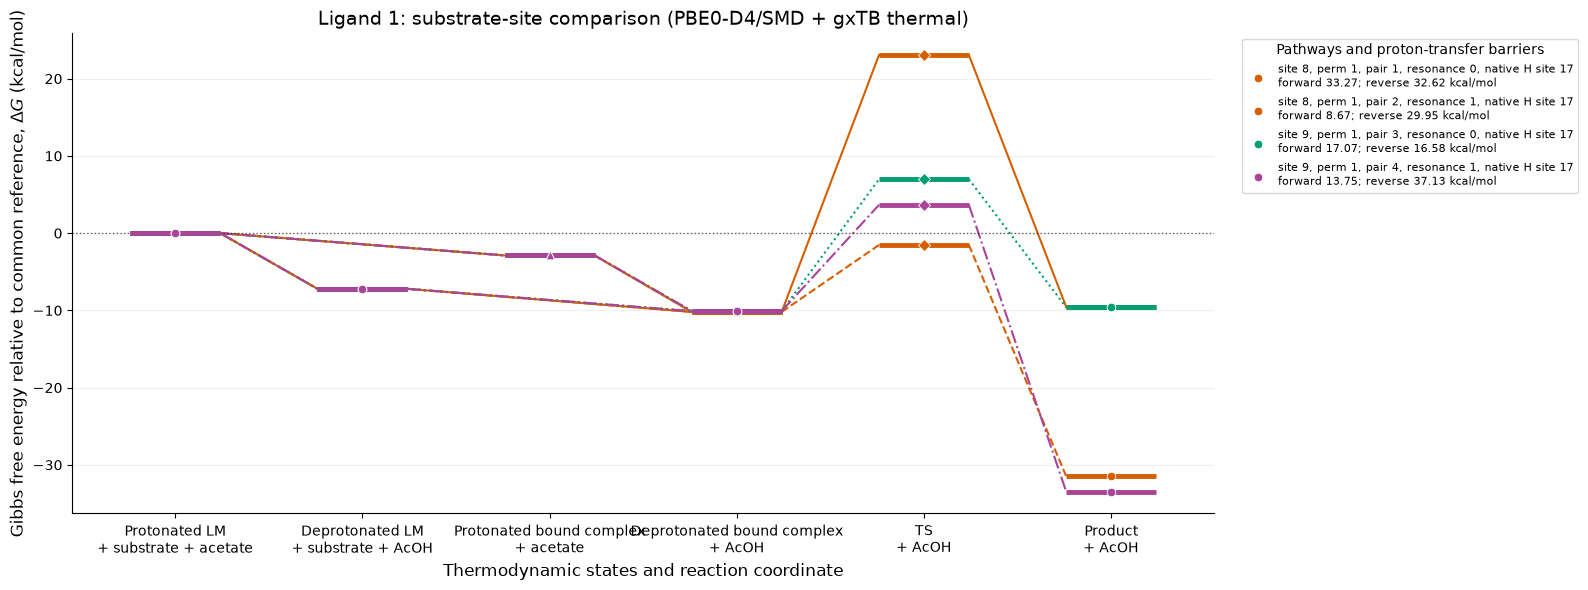

**Ligand atoms for each plotted pathway:** blue = metal-binding; red = H-acceptor; purple = both. Grid legends give forward and reverse proton-transfer barriers in kcal/mol.

**Both barriers ≤ 25 kcal/mol**

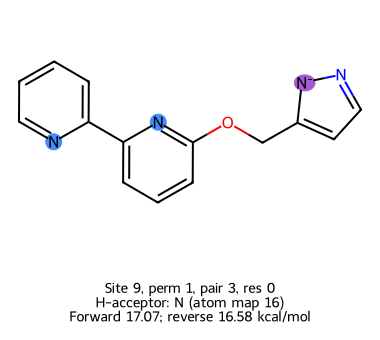

**Other pathways — at least one barrier > 25 kcal/mol**

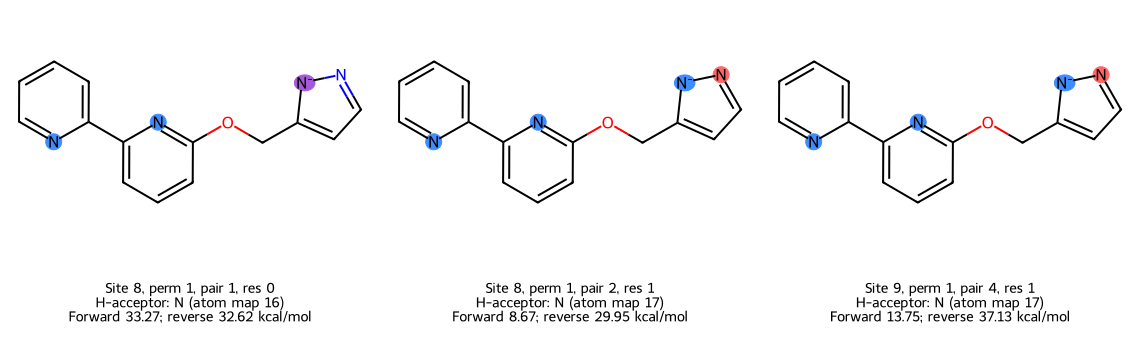

### Lowest-reactant pathway: site 8, permutation 1, pair 1

**Reactant** — $G = -1619.38579198$ Eh

Pd30 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


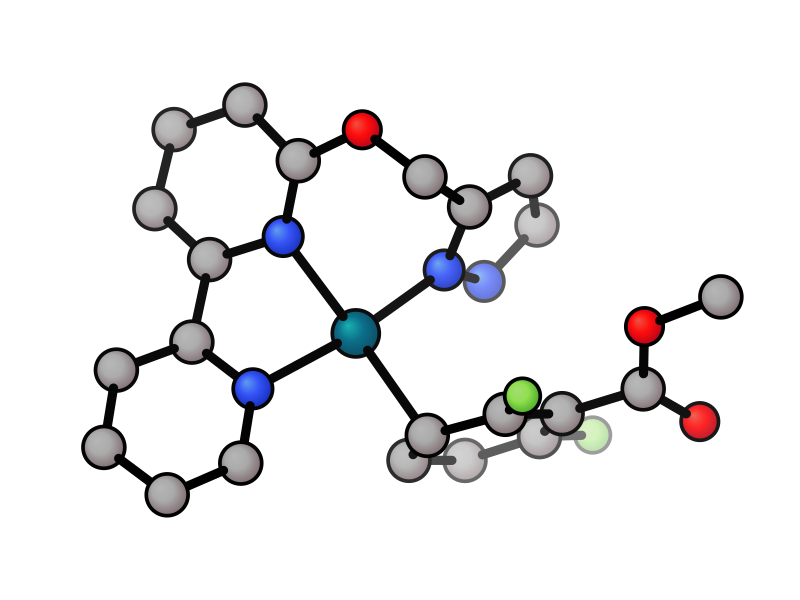

**Transition state** — $G = -1619.33277569$ Eh

Pd30 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


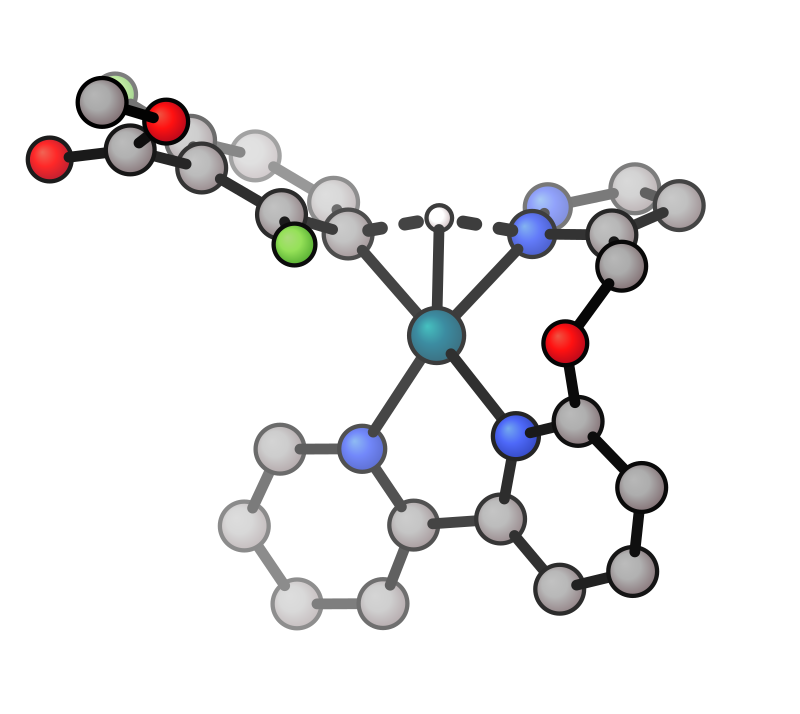

**Product** — $G = -1619.38476489$ Eh

Pd30 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


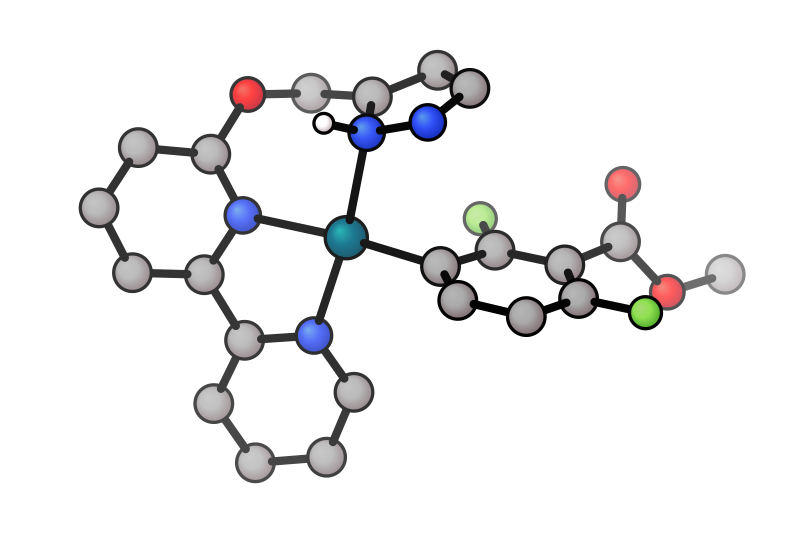

### Ligand 2: permutation coverage by site

Site,Expected permutations,Drawn,Missing,Drawn IDs,Missing IDs,Pathways drawn / recorded
8,1,1,0,1,none,1 / 2
9,1,1,0,1,none,2 / 2


Site,Permutation,Why no complete profile?
8,1,"Pair 1, seating 3 — missing plotted Gibbs energy: TS: 6 failed"


**Precursor minima and calculation coverage**

Species,Permutation,Native protonation site,Charge,gxTB job,Conformer,DFT job,G plotted (Eh),gxTB jobs
2: deprotonated,1,—,1,148,8,228,-922.05450486,"2 failed, 8 succeeded"
2: protonated,1,1,2,157,7,229,-922.49521507,10 succeeded
"2: protonated_bound, pair 1, seating 3",1,1,2,147,7,279,-1580.56973038,10 succeeded
"2: protonated_bound, pair 3, seating 3",1,1,2,151,1,280,-1580.56951201,10 succeeded
substrate_001: substrate,0,—,0,506,6,264,-658.07588733,10 succeeded


**Common reference:** lowest completed protonated LM + substrate + acetate; G = -1809.02894566 Eh. All plotted sites and permutations for this ligand share this zero.

### Ligand 2: balanced pathway comparison (kcal/mol)

Site,Permutation,Pair,Resonance,Native protonation site,Protonated LM + substrate + acetate,Deprotonated LM + substrate + AcOH,Protonated bound complex + acetate,Deprotonated bound complex + AcOH,TS + AcOH,Product + AcOH,Forward barrier,Reverse barrier,Both ≤ 25?,Reaction energy
8,1,2,1,1,+0.00,-7.15,+0.86,-7.93,+26.28,-3.63,+34.20,+29.91,no,+4.30
9,1,3,0,1,+0.00,-7.15,+1.00,-8.19,+4.61,-30.97,+12.79,+35.58,no,-22.78
9,1,4,1,1,+0.00,-7.15,+1.00,-8.19,+28.74,-4.33,+36.92,+33.07,no,+3.85


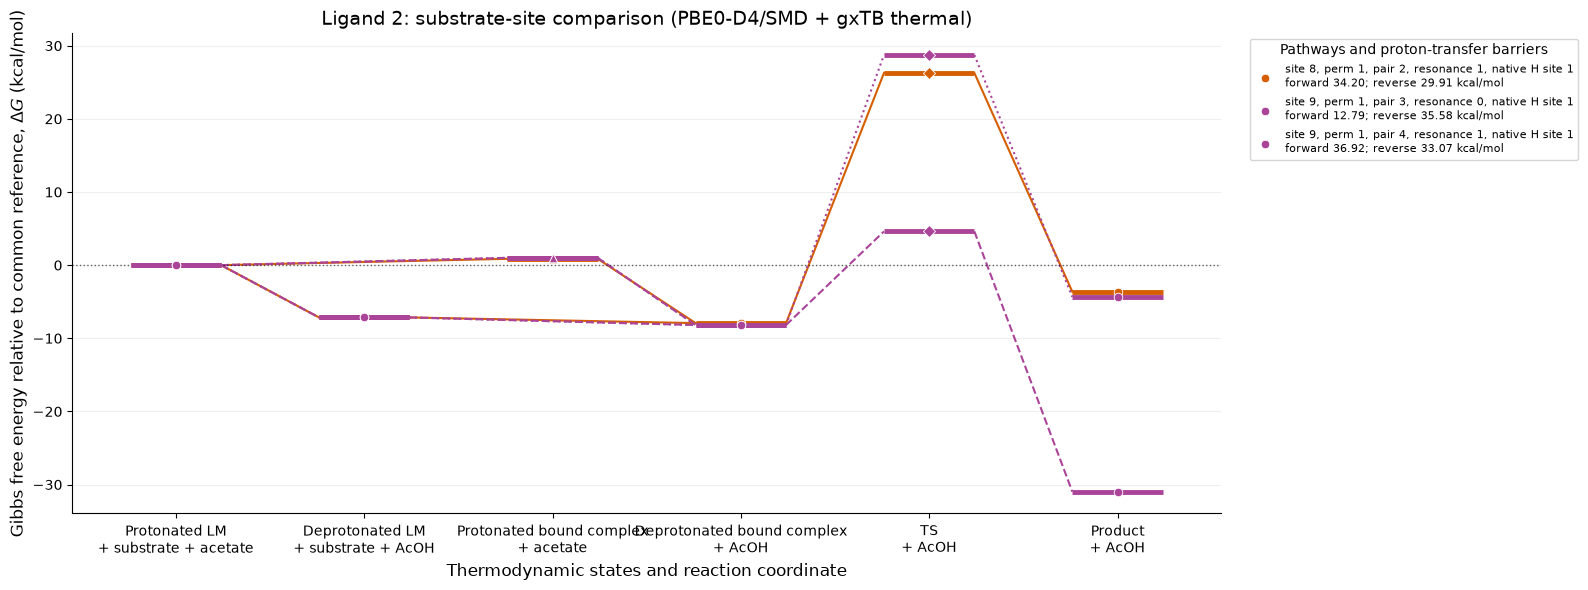

**Ligand atoms for each plotted pathway:** blue = metal-binding; red = H-acceptor; purple = both. Grid legends give forward and reverse proton-transfer barriers in kcal/mol.

**Other pathways — at least one barrier > 25 kcal/mol**

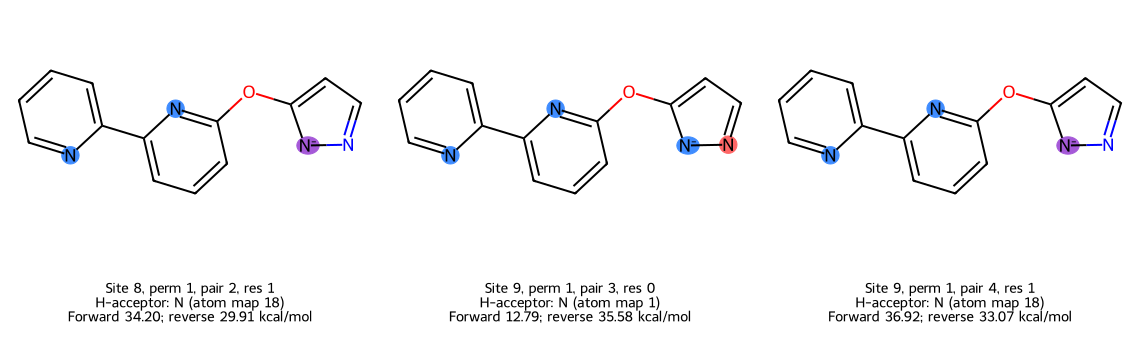

### Lowest-reactant pathway: site 9, permutation 1, pair 3

**Reactant** — $G = -1580.13204394$ Eh

Pd27 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


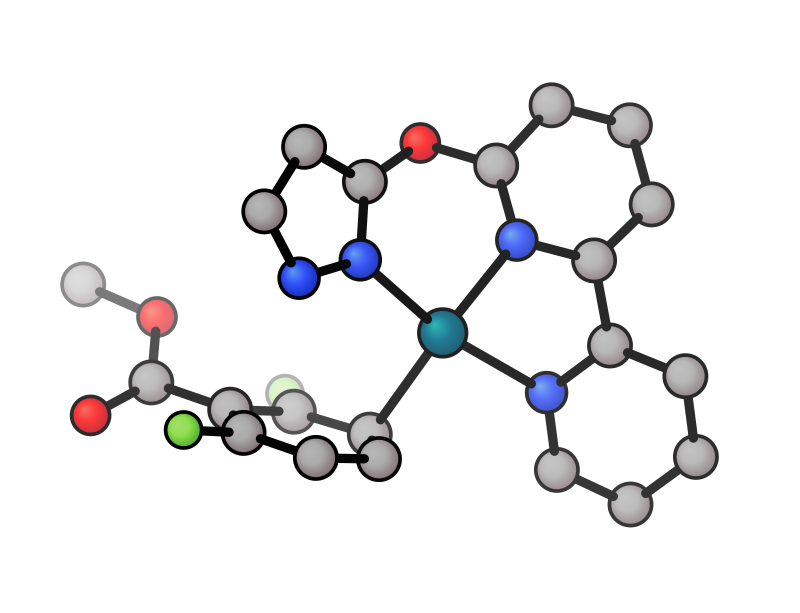

**Transition state** — $G = -1580.11165430$ Eh

Pd27 reads +3 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


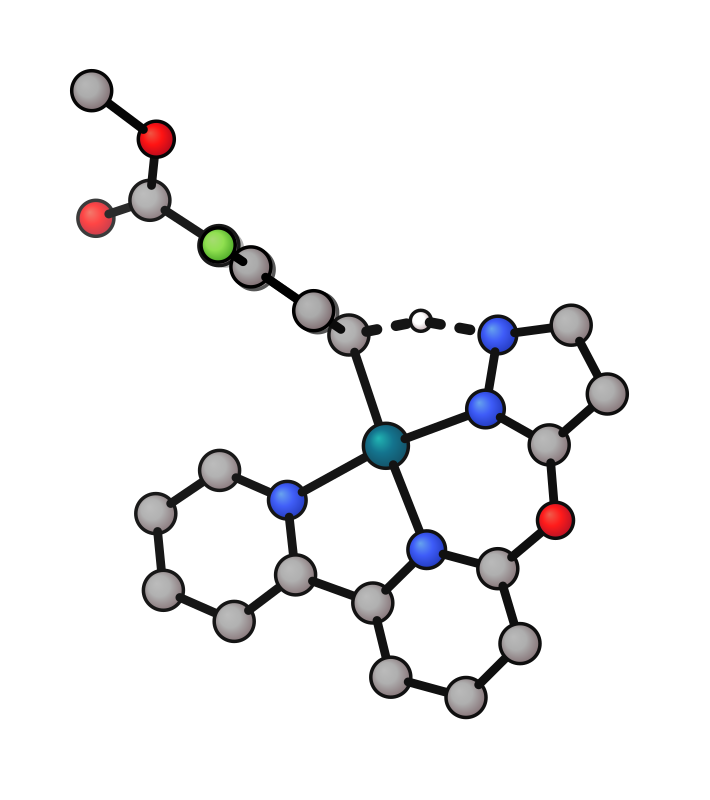

**Product** — $G = -1580.16834947$ Eh

Pd27 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


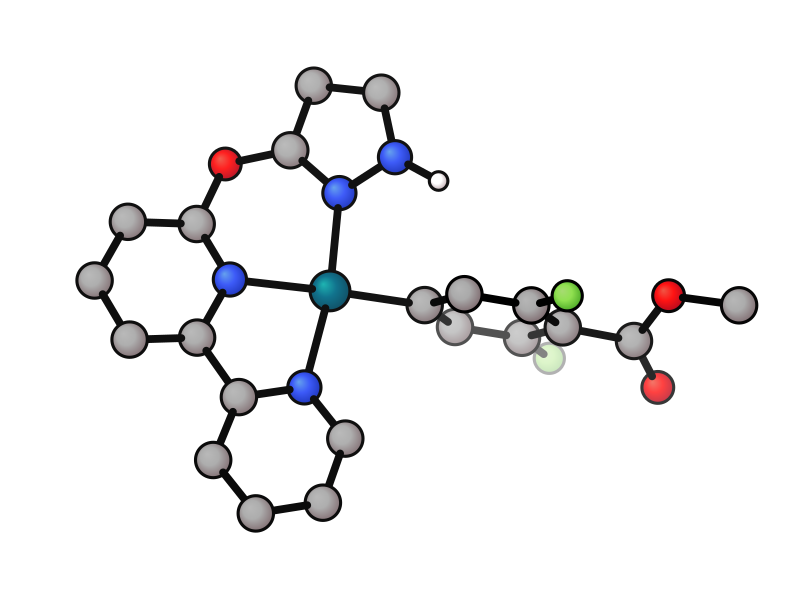

### Ligand 3: permutation coverage by site

Site,Expected permutations,Drawn,Missing,Drawn IDs,Missing IDs,Pathways drawn / recorded
8,8,7,1,"1, 2, 3, 4, 5, 6, 8",7,7 / 8
9,8,7,1,"1, 2, 3, 4, 5, 6, 8",7,7 / 8


Site,Permutation,Why no complete profile?
8,7,"Pair 9, seating 4 — missing plotted Gibbs energy: TS: 1 sampling failed"
9,7,"Pair 10, seating 4 — missing plotted Gibbs energy: TS: 1 sampling failed"


**Precursor minima and calculation coverage**

Species,Permutation,Native protonation site,Charge,gxTB job,Conformer,DFT job,G plotted (Eh),gxTB jobs
3: deprotonated,1,—,1,169,9,230,-980.17175744,10 succeeded
3: protonated,1,1,2,180,10,231,-980.61691329,10 succeeded
"3: protonated_bound, pair 1, seating 2",1,1,2,169,9,281,-1638.68839004,"1 failed, 9 succeeded"
"3: protonated_bound, pair 2, seating 2",1,1,2,183,3,283,-1638.68762920,10 succeeded
3: deprotonated,2,—,1,189,9,232,-980.17175744,10 succeeded
3: protonated,2,1,2,200,10,233,-980.61691329,"2 failed, 8 succeeded"
"3: protonated_bound, pair 1, seating 4",2,1,2,179,9,282,-1638.68839004,"1 failed, 9 succeeded"
"3: protonated_bound, pair 2, seating 4",2,1,2,193,3,284,-1638.68762920,10 succeeded
3: deprotonated,3,—,1,202,2,234,-980.16531440,10 succeeded
3: protonated,3,1,2,220,10,235,-980.61691329,10 succeeded


**Common reference:** lowest completed protonated LM + substrate + acetate; G = -1867.15752699 Eh. All plotted sites and permutations for this ligand share this zero.

### Ligand 3: balanced pathway comparison (kcal/mol)

Site,Permutation,Pair,Resonance,Native protonation site,Protonated LM + substrate + acetate,Deprotonated LM + substrate + AcOH,Protonated bound complex + acetate,Deprotonated bound complex + AcOH,TS + AcOH,Product + AcOH,Forward barrier,Reverse barrier,Both ≤ 25?,Reaction energy
8,1,1,0,1,+4.32,-0.04,+7.09,-4.38,+15.76,-25.54,+20.14,+41.29,no,-21.15
8,2,1,0,1,+4.32,-0.04,+7.09,-4.15,+15.54,-25.55,+19.69,+41.09,no,-21.40
9,1,2,0,1,+4.32,-0.04,+7.56,-7.54,+6.22,-25.40,+13.77,+31.62,no,-17.85
9,2,2,0,1,+4.32,-0.04,+7.56,-4.29,+6.10,-25.34,+10.39,+31.43,no,-21.05
8,3,3,0,1,+4.32,+4.00,+7.09,-4.38,+15.67,-25.54,+20.05,+41.20,no,-21.15
8,4,3,0,1,+4.32,+4.00,+7.09,-4.15,+15.54,-25.55,+19.69,+41.09,no,-21.40
9,3,4,0,1,+4.32,+4.00,+7.56,-7.54,+6.22,-25.40,+13.77,+31.62,no,-17.85
9,4,4,0,1,+4.32,+4.00,+7.56,-4.29,+6.10,-25.34,+10.39,+31.43,no,-21.05
8,5,5,0,1,+50.49,+3.57,+25.96,-3.99,+27.09,-4.04,+31.09,+31.13,no,-0.05
9,5,6,0,1,+50.49,+3.57,+25.73,-4.26,+31.60,-4.39,+35.87,+35.99,no,-0.13


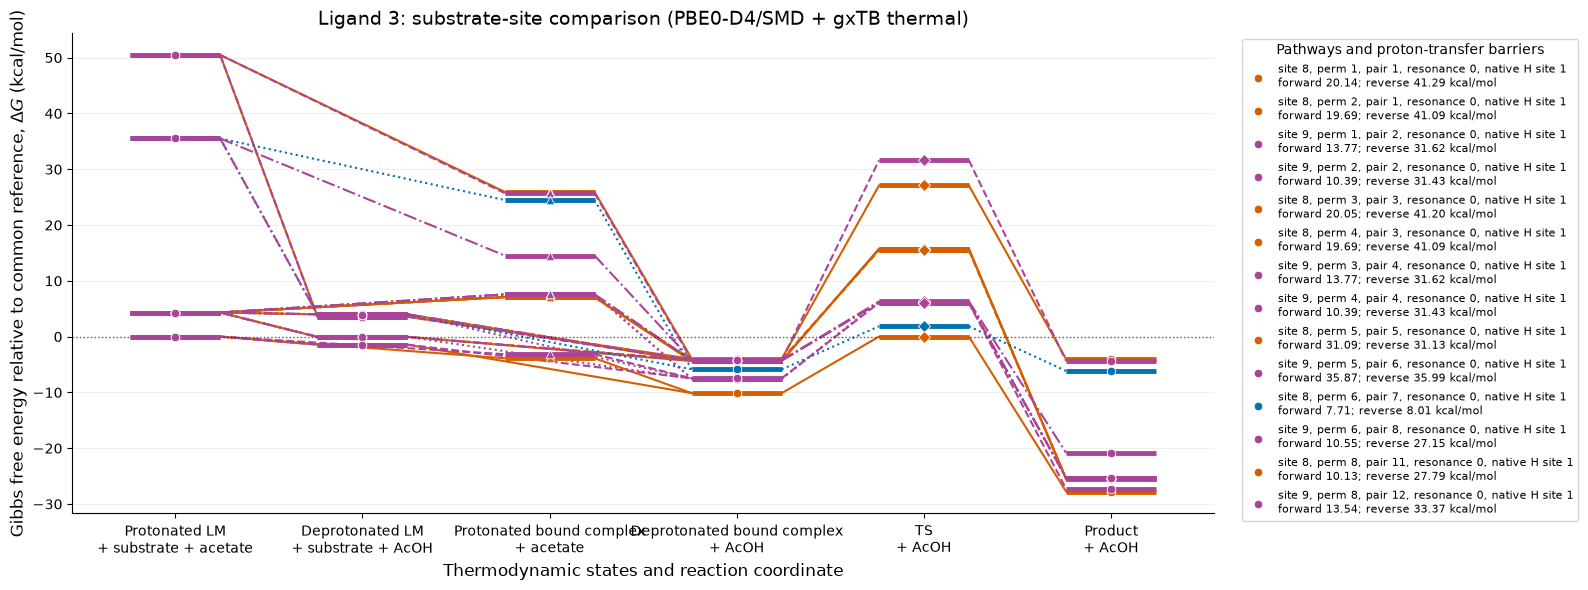

**Ligand atoms for each plotted pathway:** blue = metal-binding; red = H-acceptor; purple = both. Grid legends give forward and reverse proton-transfer barriers in kcal/mol.

**Both barriers ≤ 25 kcal/mol**

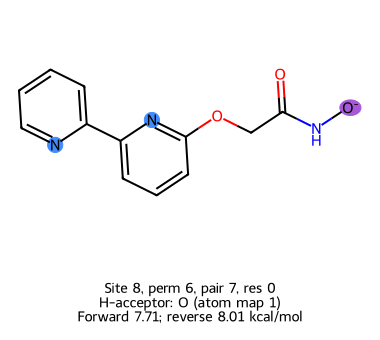

**Other pathways — at least one barrier > 25 kcal/mol**

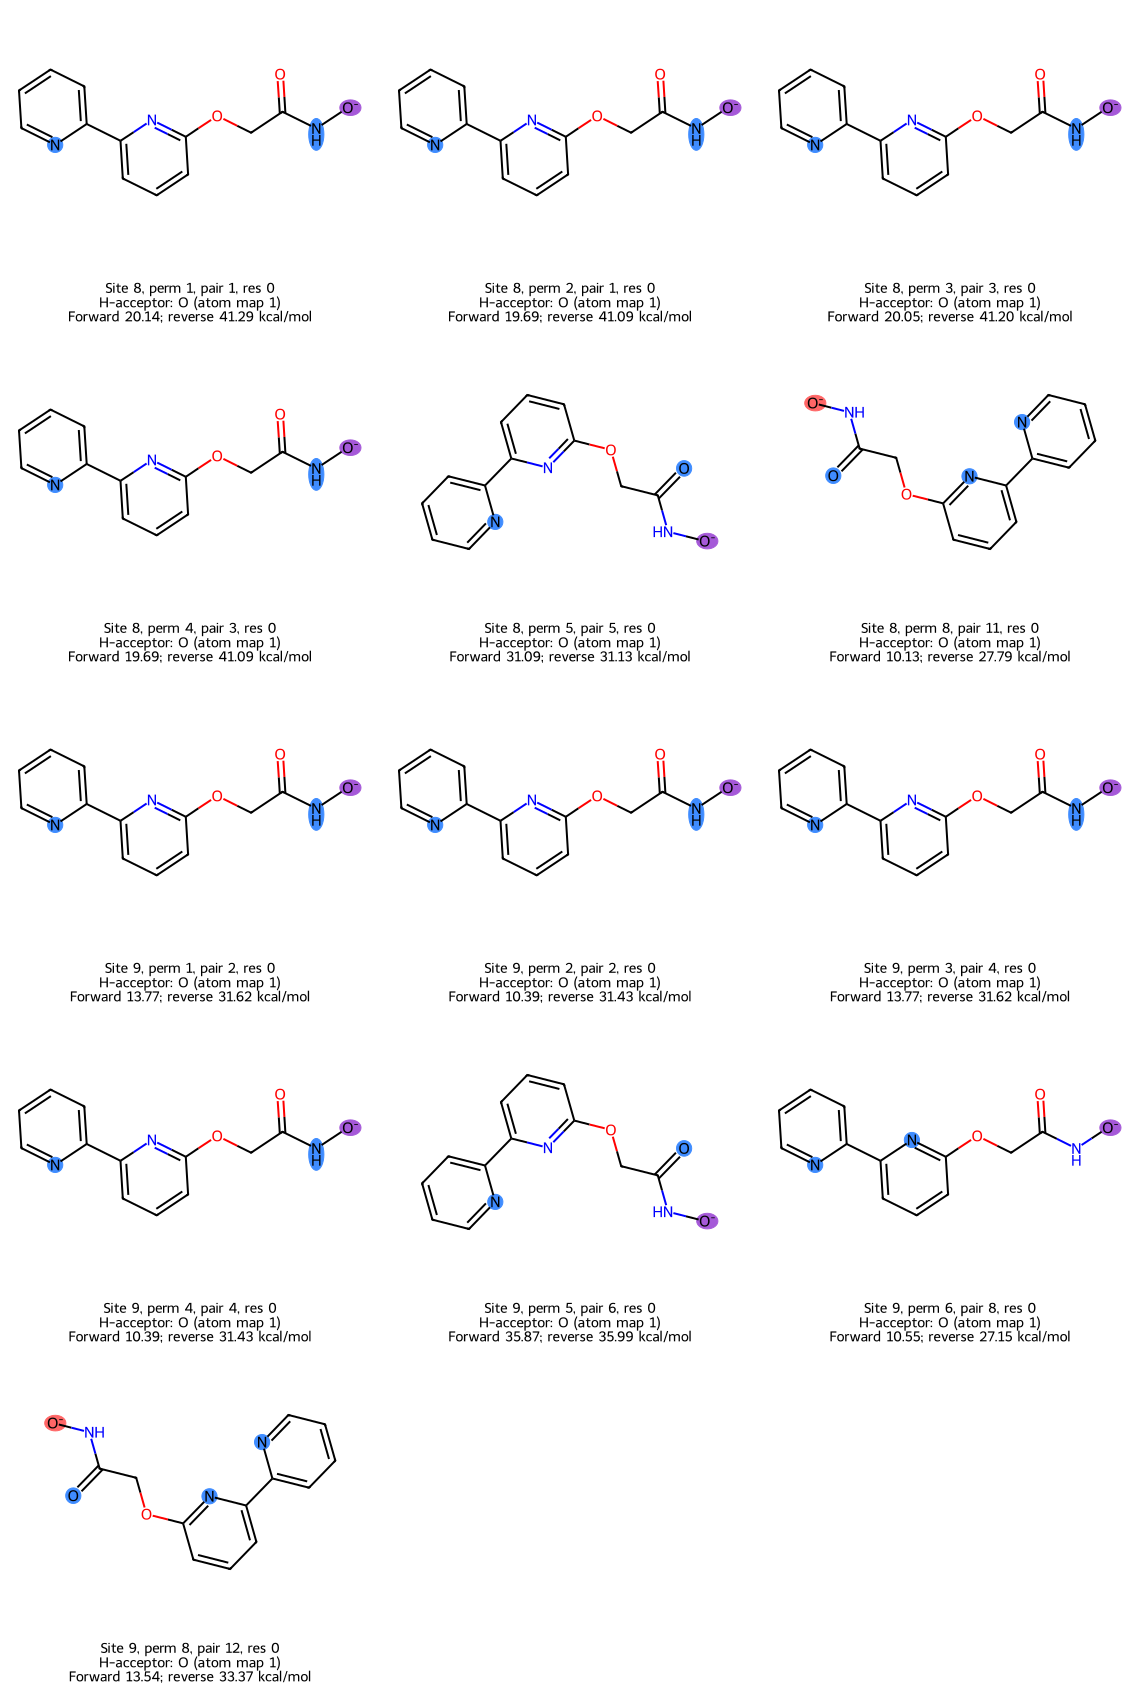

### Lowest-reactant pathway: site 8, permutation 8, pair 11

**Reactant** — $G = -1638.26372270$ Eh

Pd28 reads -1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


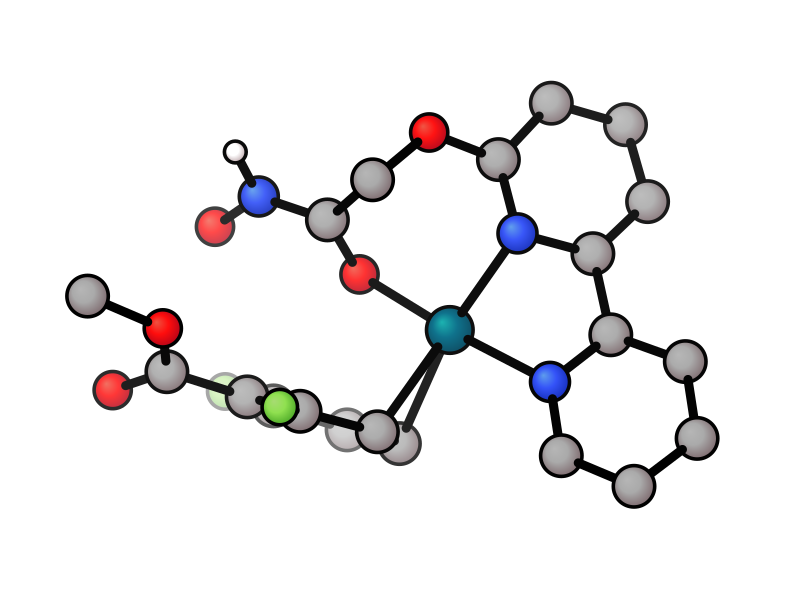

**Transition state** — $G = -1638.24757525$ Eh

Pd28 reads -1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


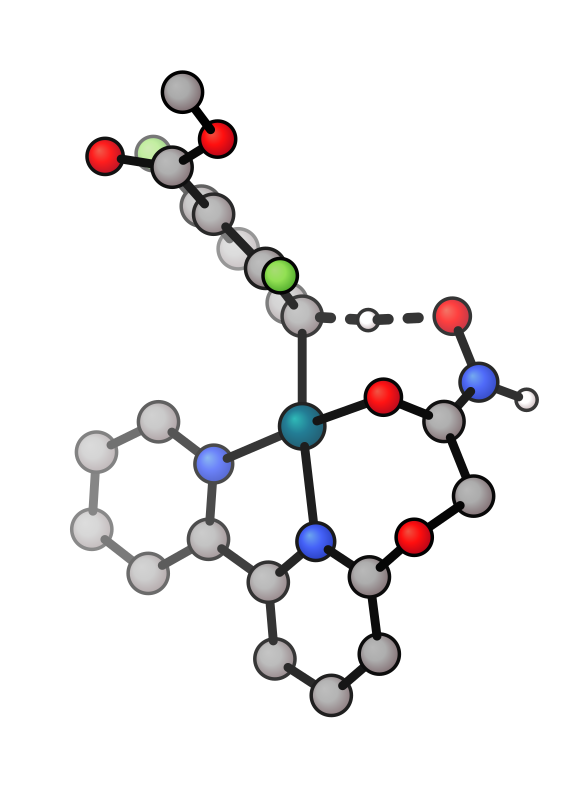

**Product** — $G = -1638.29186257$ Eh

Pd28 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


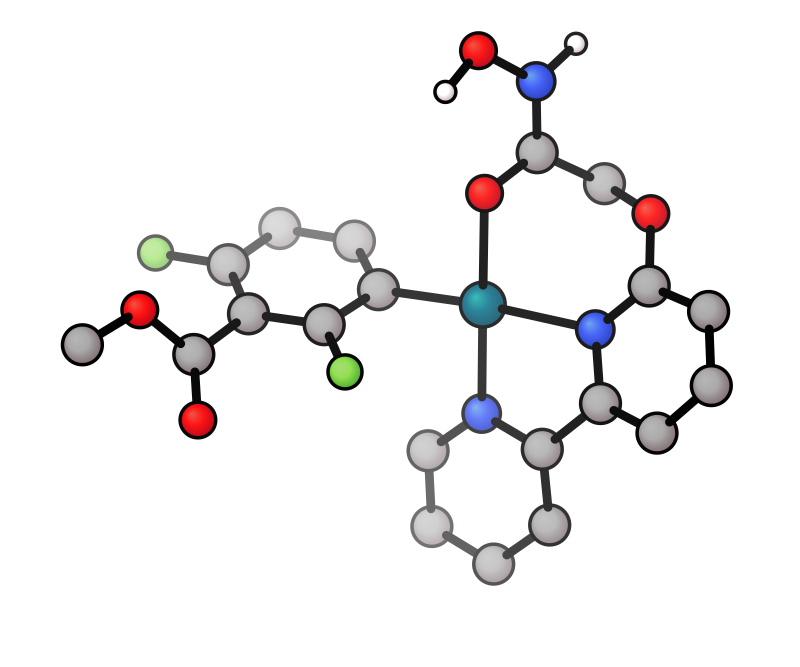

### Ligand 4: permutation coverage by site

Site,Expected permutations,Drawn,Missing,Drawn IDs,Missing IDs,Pathways drawn / recorded
8,5,5,0,"1, 2, 3, 4, 5",none,5 / 5
9,5,5,0,"1, 2, 3, 4, 5",none,5 / 5


**Precursor minima and calculation coverage**

Species,Permutation,Native protonation site,Charge,gxTB job,Conformer,DFT job,G plotted (Eh),gxTB jobs
4: deprotonated,1,—,1,330,10,246,-1340.23316370,10 succeeded
4: protonated,1,1,2,337,7,247,-1340.64683808,"3 failed, 7 succeeded"
"4: protonated_bound, pair 1, seating 4",1,1,2,321,1,297,-1998.72195701,"1 failed, 9 succeeded"
"4: protonated_bound, pair 2, seating 4",1,1,2,331,1,298,-1998.72148985,"2 failed, 8 succeeded"
4: deprotonated,2,—,1,344,4,248,-1340.23291814,10 succeeded
4: protonated,2,1,2,352,2,249,-1340.64665689,10 succeeded
"4: protonated_bound, pair 3, seating 4",2,1,2,348,8,299,-1998.72228294,10 succeeded
"4: protonated_bound, pair 4, seating 4",2,1,2,353,3,300,-1998.72764787,"1 failed, 9 succeeded"
4: deprotonated,3,—,1,363,3,250,-1340.23335135,10 succeeded
4: protonated,3,1,2,373,3,251,-1340.64678967,10 succeeded


**Common reference:** lowest completed protonated LM + substrate + acetate; G = -2227.18056867 Eh. All plotted sites and permutations for this ligand share this zero.

### Ligand 4: balanced pathway comparison (kcal/mol)

Site,Permutation,Pair,Resonance,Native protonation site,Protonated LM + substrate + acetate,Deprotonated LM + substrate + AcOH,Protonated bound complex + acetate,Deprotonated bound complex + AcOH,TS + AcOH,Product + AcOH,Forward barrier,Reverse barrier,Both ≤ 25?,Reaction energy
8,1,1,0,1,+0.00,-24.12,+0.48,-25.79,-14.15,-32.92,+11.64,+18.77,yes,-7.13
9,1,2,0,1,+0.00,-24.12,+0.78,-26.97,-8.45,-34.25,+18.51,+25.80,no,-7.28
8,2,3,0,1,+0.11,-23.96,+0.28,-25.85,-14.22,-33.48,+11.63,+19.26,yes,-7.63
9,2,4,0,1,+0.11,-23.96,-3.09,-27.03,-10.14,-33.85,+16.89,+23.71,yes,-6.82
8,3,5,0,1,+0.03,-24.23,-2.66,-26.00,-12.04,-32.82,+13.96,+20.78,yes,-6.82
9,3,6,0,1,+0.03,-24.23,-3.07,-26.02,-8.34,-33.71,+17.69,+25.37,no,-7.69
8,4,7,0,1,+0.05,-24.15,-2.88,-25.88,-14.10,-32.75,+11.78,+18.65,yes,-6.87
9,4,8,0,1,+0.05,-24.15,+0.44,-26.97,-8.28,-33.63,+18.69,+25.34,no,-6.66
8,5,9,0,1,+3.92,-2.50,-1.50,-8.73,-12.23,-31.75,-3.51,+19.52,yes,-23.02
9,5,10,0,1,+3.92,-2.50,-2.53,-8.54,+7.82,-26.79,+16.36,+34.61,no,-18.25


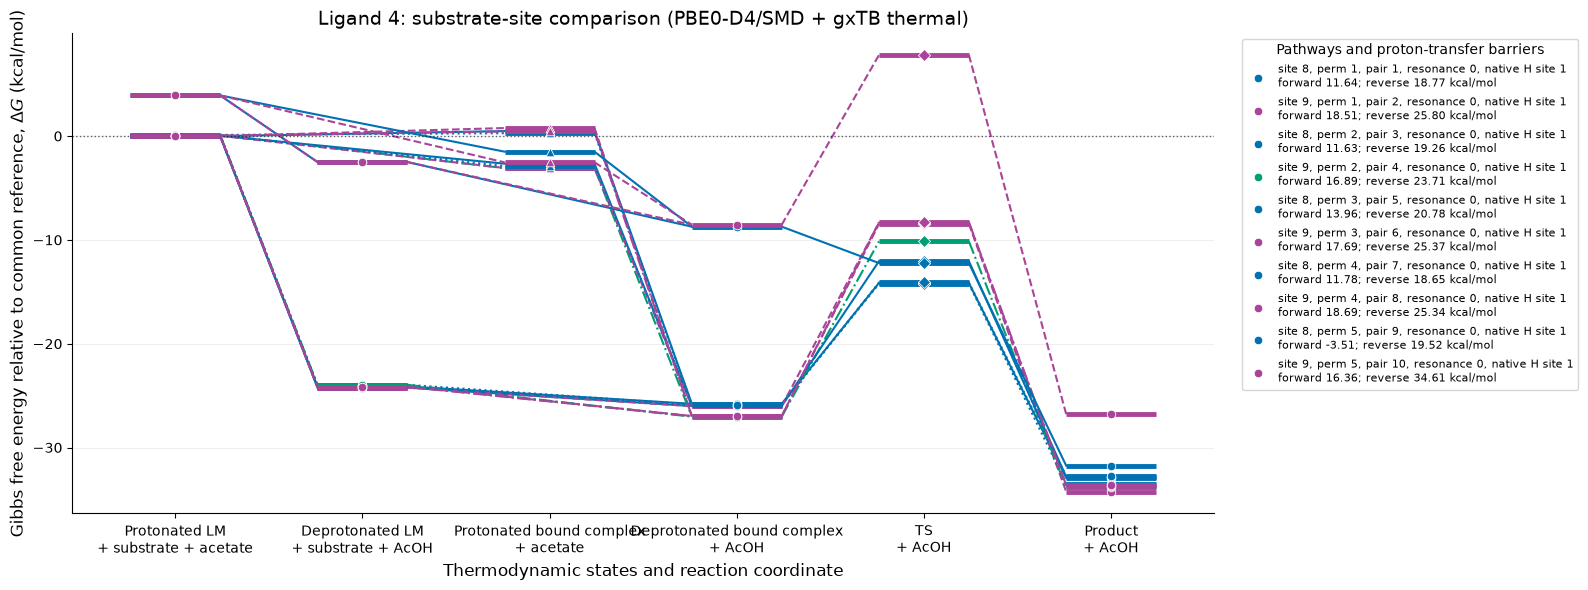

**Ligand atoms for each plotted pathway:** blue = metal-binding; red = H-acceptor; purple = both. Grid legends give forward and reverse proton-transfer barriers in kcal/mol.

**Both barriers ≤ 25 kcal/mol**

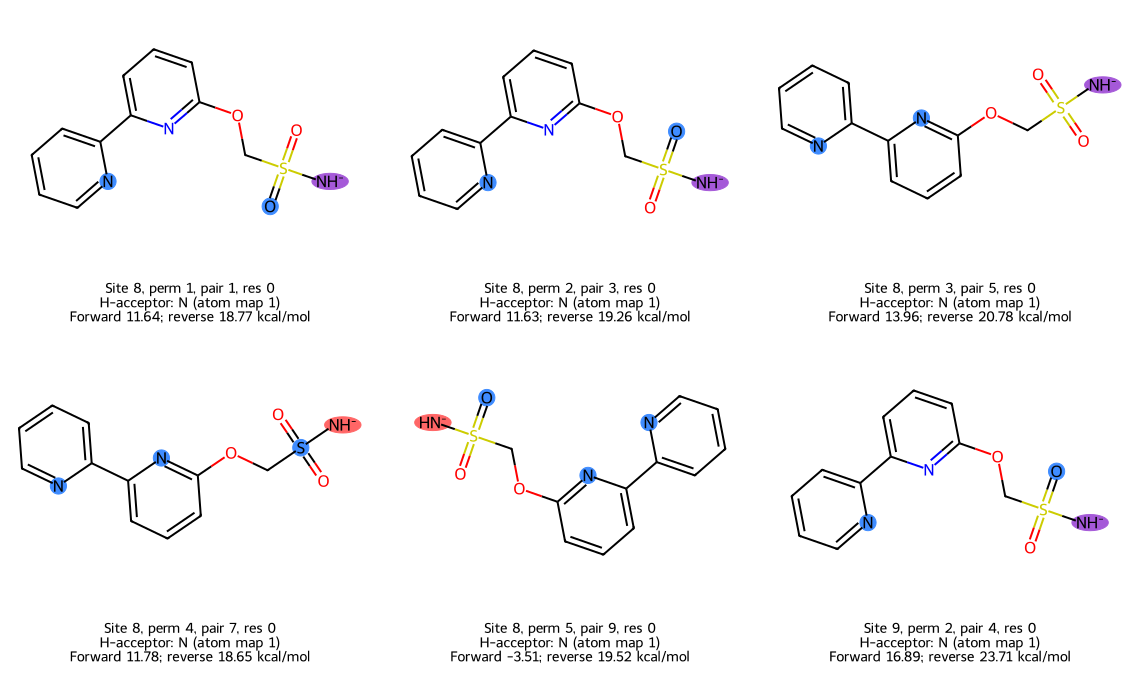

**Other pathways — at least one barrier > 25 kcal/mol**

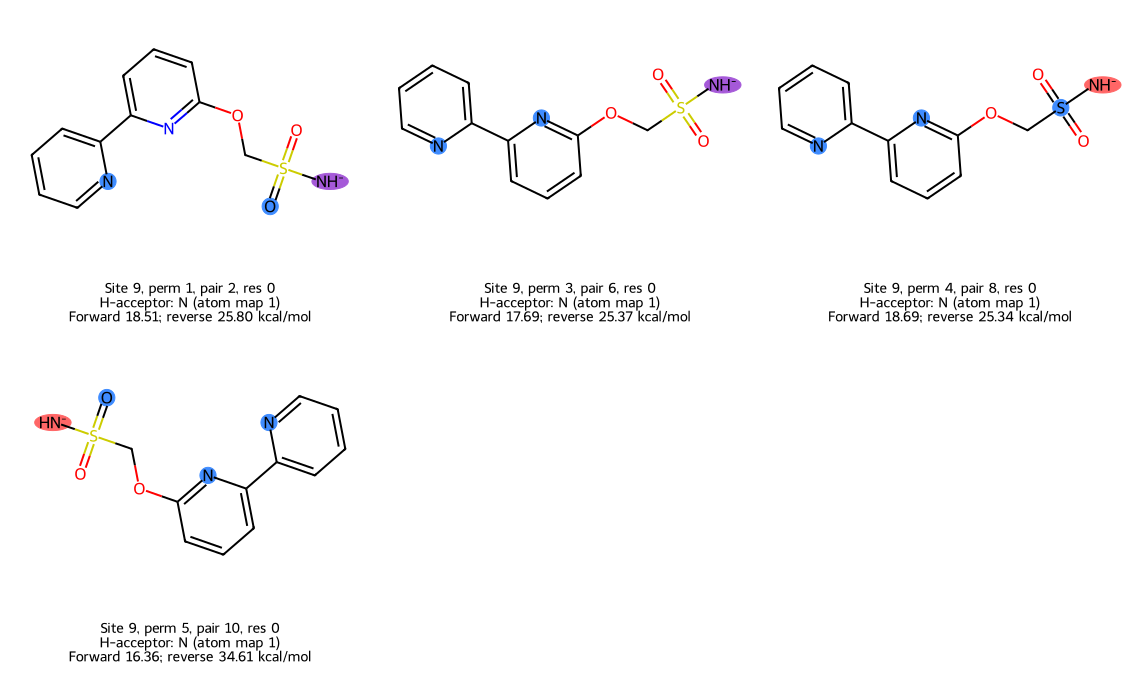

### Lowest-reactant pathway: site 9, permutation 2, pair 4

**Reactant** — $G = -1998.31369928$ Eh

Pd28 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


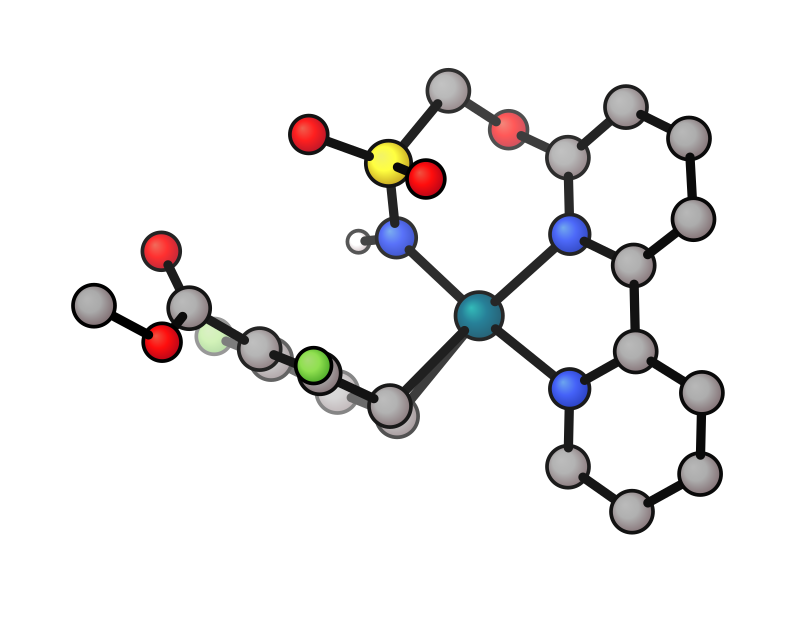

**Transition state** — $G = -1998.28678021$ Eh

Pd28 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


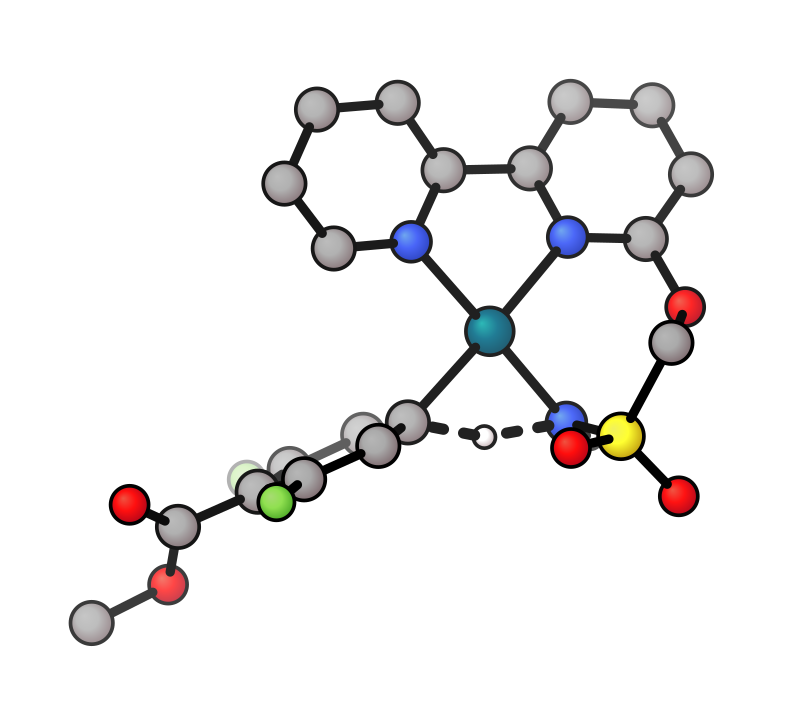

**Product** — $G = -1998.32456014$ Eh

Pd28 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


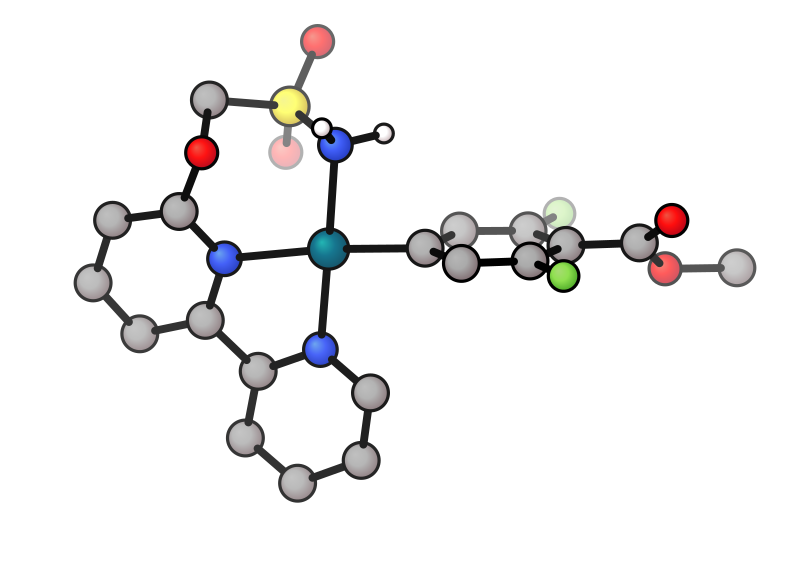

### Ligand 5: permutation coverage by site

Site,Expected permutations,Drawn,Missing,Drawn IDs,Missing IDs,Pathways drawn / recorded
8,1,1,0,1,none,2 / 2
9,1,1,0,1,none,2 / 2


**Precursor minima and calculation coverage**

Species,Permutation,Native protonation site,Charge,gxTB job,Conformer,DFT job,G plotted (Eh),gxTB jobs
5: deprotonated,1,—,1,425,5,256,-905.07006972,10 succeeded
5: protonated,1,1,2,434,4,257,-905.49770896,10 succeeded
"5: protonated_bound, pair 1, seating 4",1,1,2,430,10,307,-1563.58054371,"3 failed, 7 succeeded"
"5: protonated_bound, pair 3, seating 4",1,1,2,431,1,308,-1563.57835625,"1 failed, 9 succeeded"
substrate_001: substrate,0,—,0,506,6,264,-658.07588733,10 succeeded


**Common reference:** lowest completed protonated LM + substrate + acetate; G = -1792.03143956 Eh. All plotted sites and permutations for this ligand share this zero.

### Ligand 5: balanced pathway comparison (kcal/mol)

Site,Permutation,Pair,Resonance,Native protonation site,Protonated LM + substrate + acetate,Deprotonated LM + substrate + AcOH,Protonated bound complex + acetate,Deprotonated bound complex + AcOH,TS + AcOH,Product + AcOH,Forward barrier,Reverse barrier,Both ≤ 25?,Reaction energy
8,1,1,0,1,+0.00,-15.35,-4.36,-19.82,+10.41,-29.32,+30.22,+39.72,no,-9.50
8,1,2,1,1,+0.00,-15.35,-4.36,-19.82,+0.04,-34.59,+19.86,+34.63,no,-14.77
9,1,3,0,1,+0.00,-15.35,-2.99,-19.89,+15.91,-30.09,+35.80,+45.99,no,-10.19
9,1,4,1,1,+0.00,-15.35,-2.99,-19.89,-10.09,-33.81,+9.81,+23.72,yes,-13.91


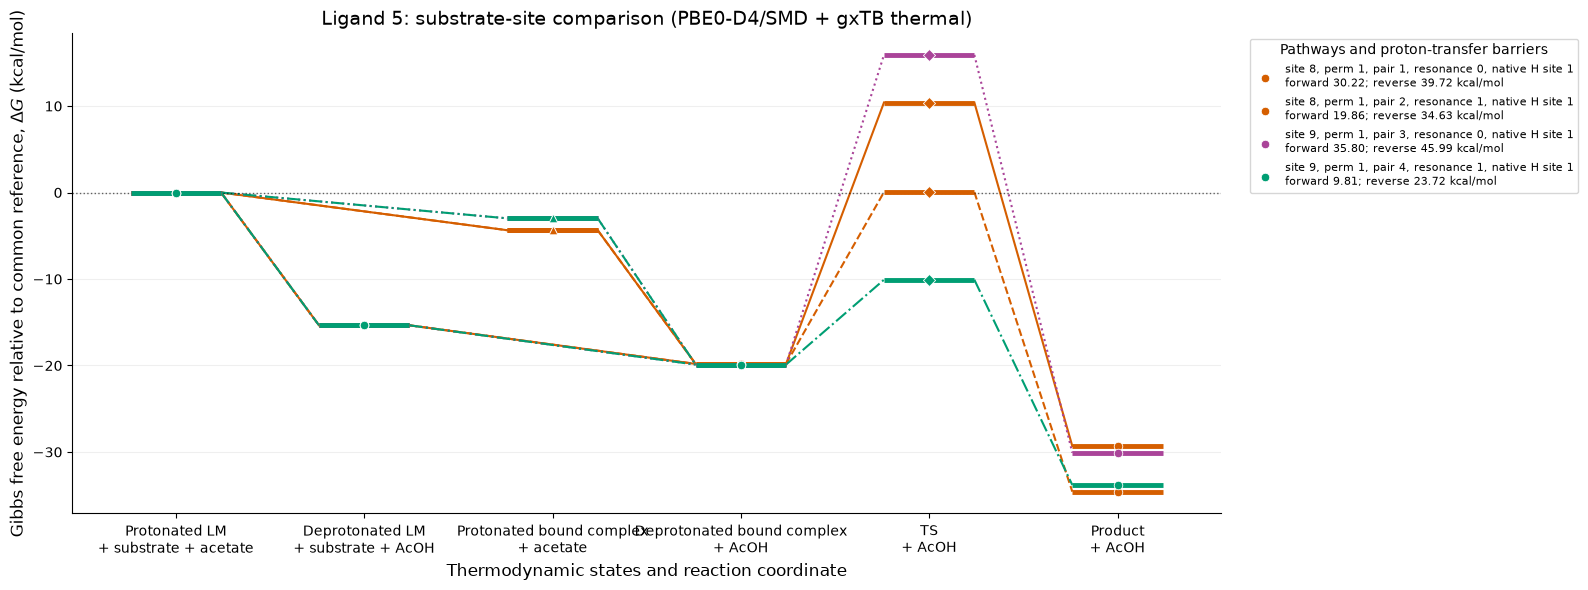

**Ligand atoms for each plotted pathway:** blue = metal-binding; red = H-acceptor; purple = both. Grid legends give forward and reverse proton-transfer barriers in kcal/mol.

**Both barriers ≤ 25 kcal/mol**

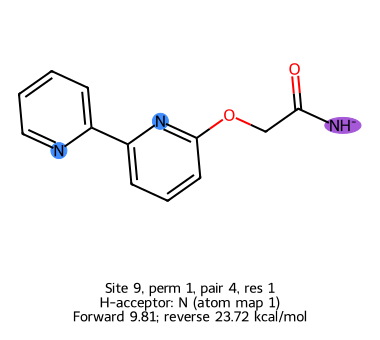

**Other pathways — at least one barrier > 25 kcal/mol**

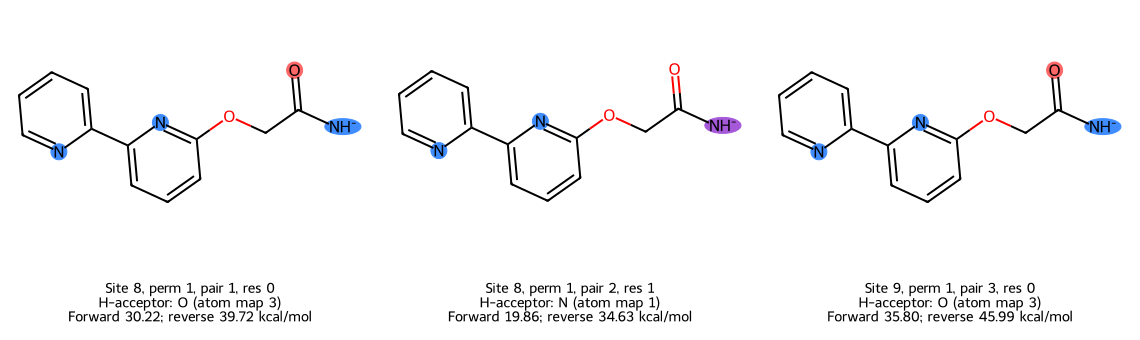

### Lowest-reactant pathway: site 9, permutation 1, pair 4

**Reactant** — $G = -1563.15319667$ Eh

Pd27 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


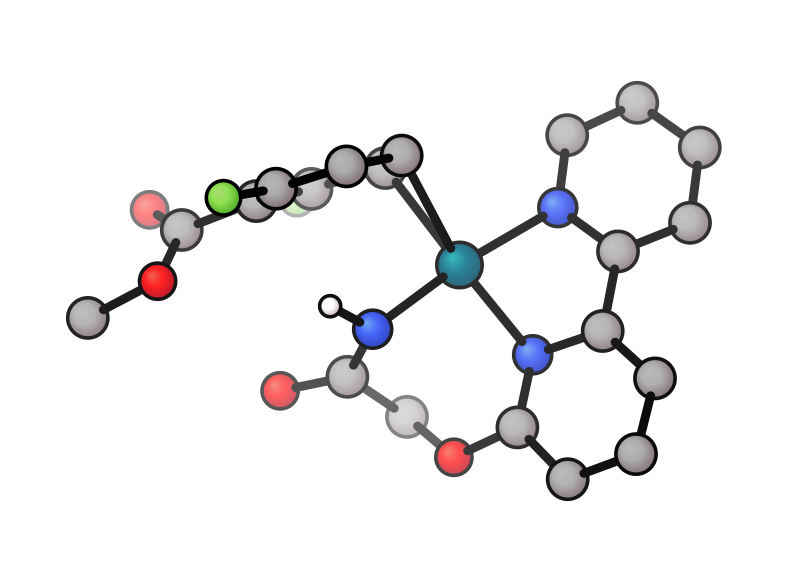

**Transition state** — $G = -1563.13756629$ Eh

Pd27 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


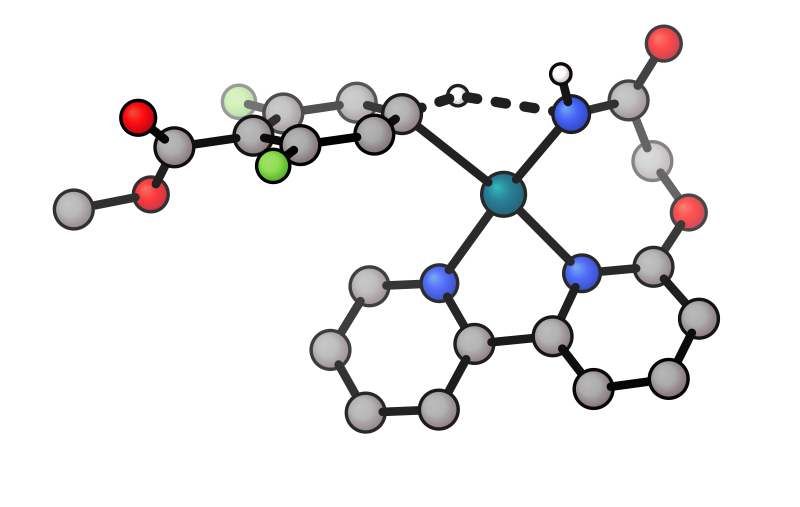

**Product** — $G = -1563.17536957$ Eh

Pd27 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


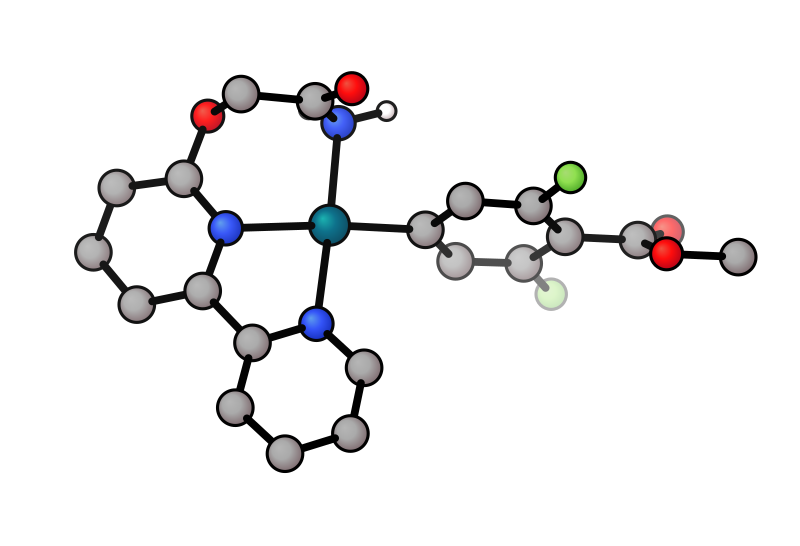

### Ligand 6: permutation coverage by site

Site,Expected permutations,Drawn,Missing,Drawn IDs,Missing IDs,Pathways drawn / recorded
8,1,1,0,1,none,1 / 1
9,1,1,0,1,none,1 / 1


**Precursor minima and calculation coverage**

Species,Permutation,Native protonation site,Charge,gxTB job,Conformer,DFT job,G plotted (Eh),gxTB jobs
6: deprotonated,1,—,1,446,6,258,-927.08818563,10 succeeded
6: protonated,1,1,2,459,9,259,-927.51484283,10 succeeded
"6: protonated_bound, pair 1, seating 4",1,1,2,441,1,309,-1585.59984674,10 succeeded
"6: protonated_bound, pair 2, seating 4",1,1,2,454,4,310,-1585.60067529,10 succeeded
substrate_001: substrate,0,—,0,506,6,264,-658.07588733,10 succeeded


**Common reference:** lowest completed protonated LM + substrate + acetate; G = -1814.04857342 Eh. All plotted sites and permutations for this ligand share this zero.

### Ligand 6: balanced pathway comparison (kcal/mol)

Site,Permutation,Pair,Resonance,Native protonation site,Protonated LM + substrate + acetate,Deprotonated LM + substrate + AcOH,Protonated bound complex + acetate,Deprotonated bound complex + AcOH,TS + AcOH,Product + AcOH,Forward barrier,Reverse barrier,Both ≤ 25?,Reaction energy
8,1,1,0,1,+0.00,-15.97,-5.72,-21.03,-7.51,-31.87,+13.53,+24.36,yes,-10.83
9,1,2,0,1,+0.00,-15.97,-6.24,-20.88,-3.80,-32.23,+17.08,+28.43,no,-11.35


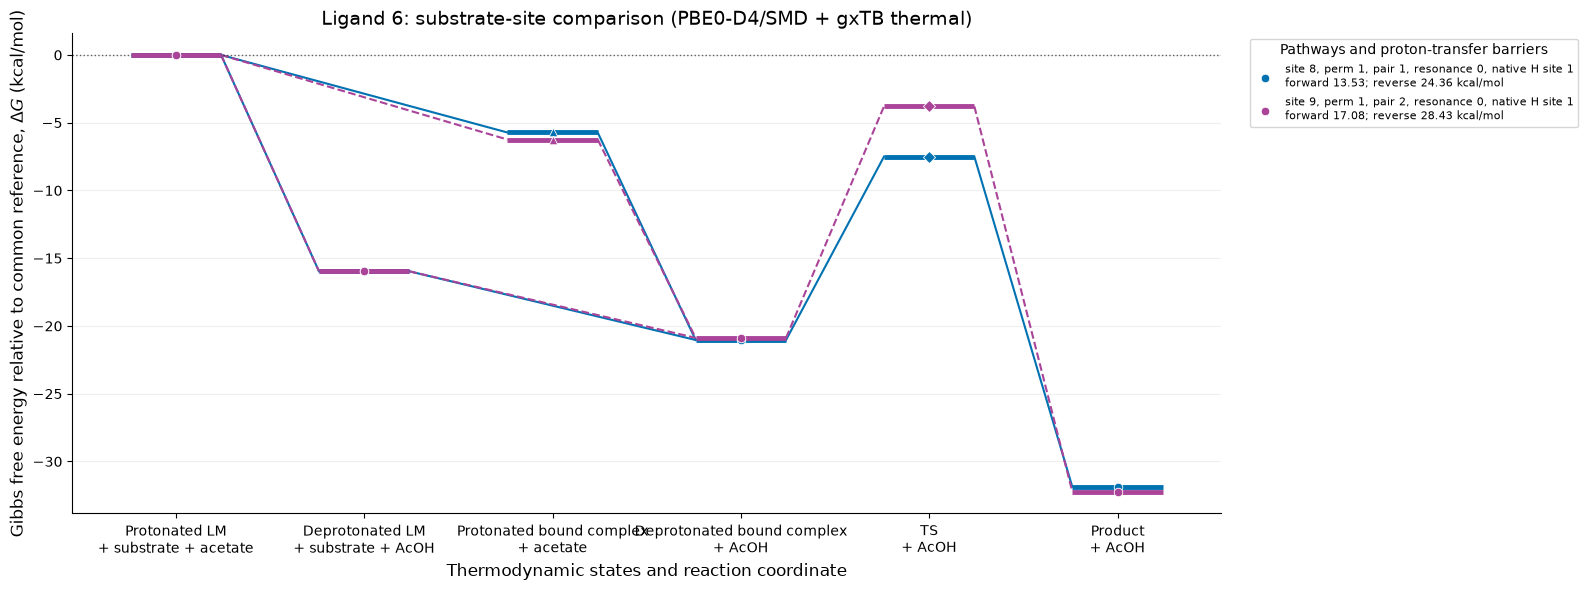

**Ligand atoms for each plotted pathway:** blue = metal-binding; red = H-acceptor; purple = both. Grid legends give forward and reverse proton-transfer barriers in kcal/mol.

**Both barriers ≤ 25 kcal/mol**

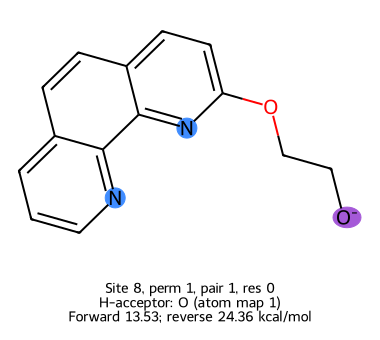

**Other pathways — at least one barrier > 25 kcal/mol**

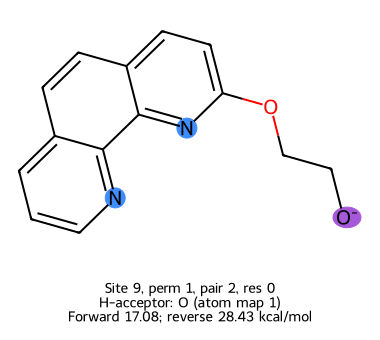

### Lowest-reactant pathway: site 8, permutation 1, pair 1

**Reactant** — $G = -1585.17214613$ Eh

Pd29 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


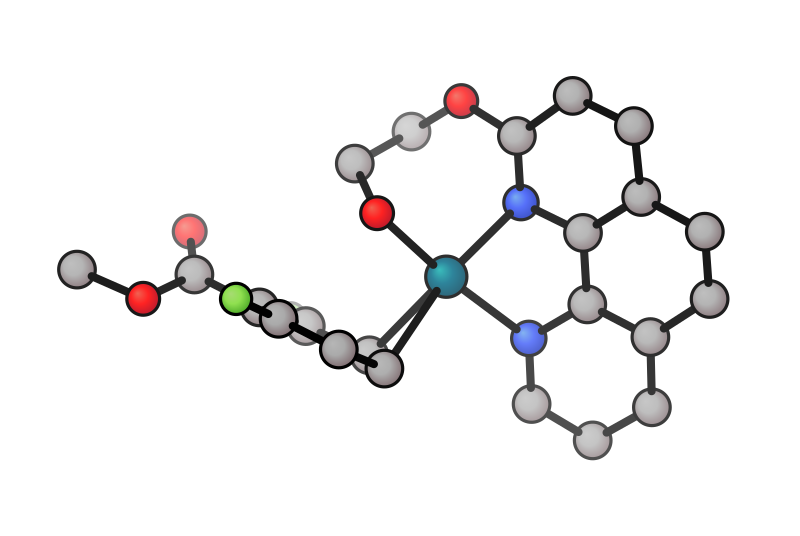

**Transition state** — $G = -1585.15058797$ Eh

Pd29 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


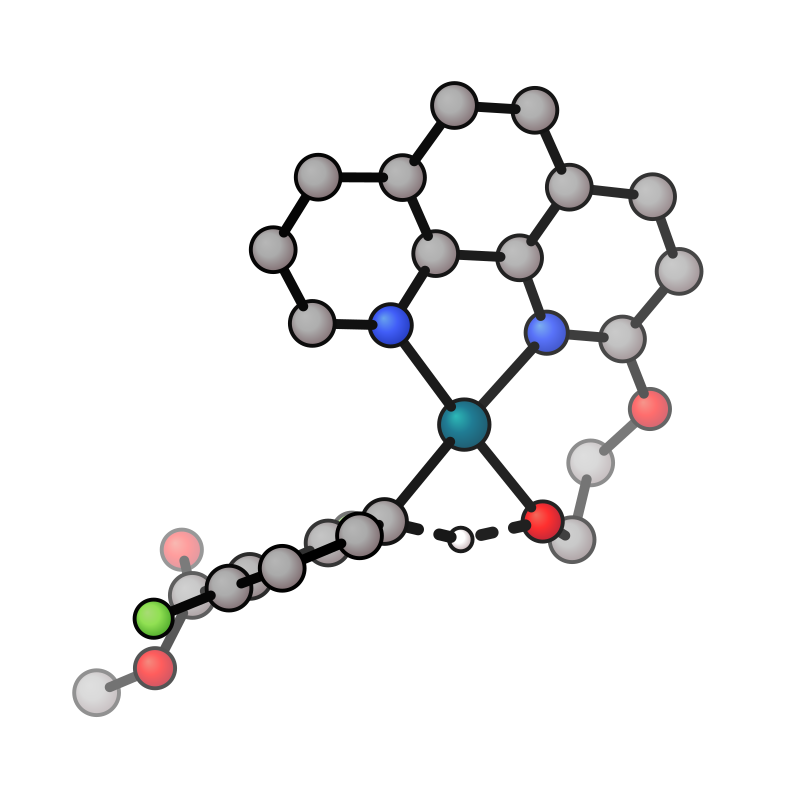

**Product** — $G = -1585.18941237$ Eh

Pd29 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


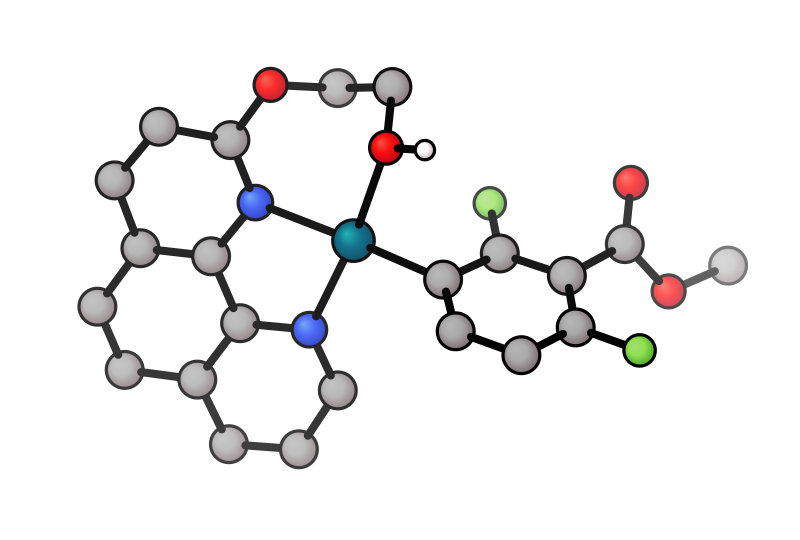

### Ligand 8: permutation coverage by site

Site,Expected permutations,Drawn,Missing,Drawn IDs,Missing IDs,Pathways drawn / recorded
8,1,1,0,1,none,2 / 2
9,1,1,0,1,none,2 / 2


**Precursor minima and calculation coverage**

Species,Permutation,Native protonation site,Charge,gxTB job,Conformer,DFT job,G plotted (Eh),gxTB jobs
8: deprotonated,1,—,1,464,4,260,-1078.09370719,10 succeeded
"8: protonated_bound, pair 1, seating 4",1,18,2,462,2,311,-1736.61352784,10 succeeded
"8: protonated_bound, pair 3, seating 4",1,18,2,479,9,312,-1736.61444881,10 succeeded
8: protonated,1,18,2,479,9,261,-1078.53828825,10 succeeded
substrate_001: substrate,0,—,0,506,6,264,-658.07588733,10 succeeded


**Common reference:** lowest completed protonated LM + substrate + acetate; G = -1965.07201885 Eh. All plotted sites and permutations for this ligand share this zero.

### Ligand 8: balanced pathway comparison (kcal/mol)

Site,Permutation,Pair,Resonance,Native protonation site,Protonated LM + substrate + acetate,Deprotonated LM + substrate + AcOH,Protonated bound complex + acetate,Deprotonated bound complex + AcOH,TS + AcOH,Product + AcOH,Forward barrier,Reverse barrier,Both ≤ 25?,Reaction energy
8,1,1,0,18,+0.00,-4.72,+0.41,-7.34,+20.45,-7.10,+27.79,+27.55,no,+0.24
8,1,2,1,18,+0.00,-4.72,+0.41,-7.34,+5.75,-31.27,+13.10,+37.03,no,-23.93
9,1,3,0,18,+0.00,-4.72,-0.17,-7.33,+10.09,-6.97,+17.41,+17.06,yes,+0.35
9,1,4,1,18,+0.00,-4.72,-0.17,-7.33,+5.93,-31.38,+13.26,+37.31,no,-24.05


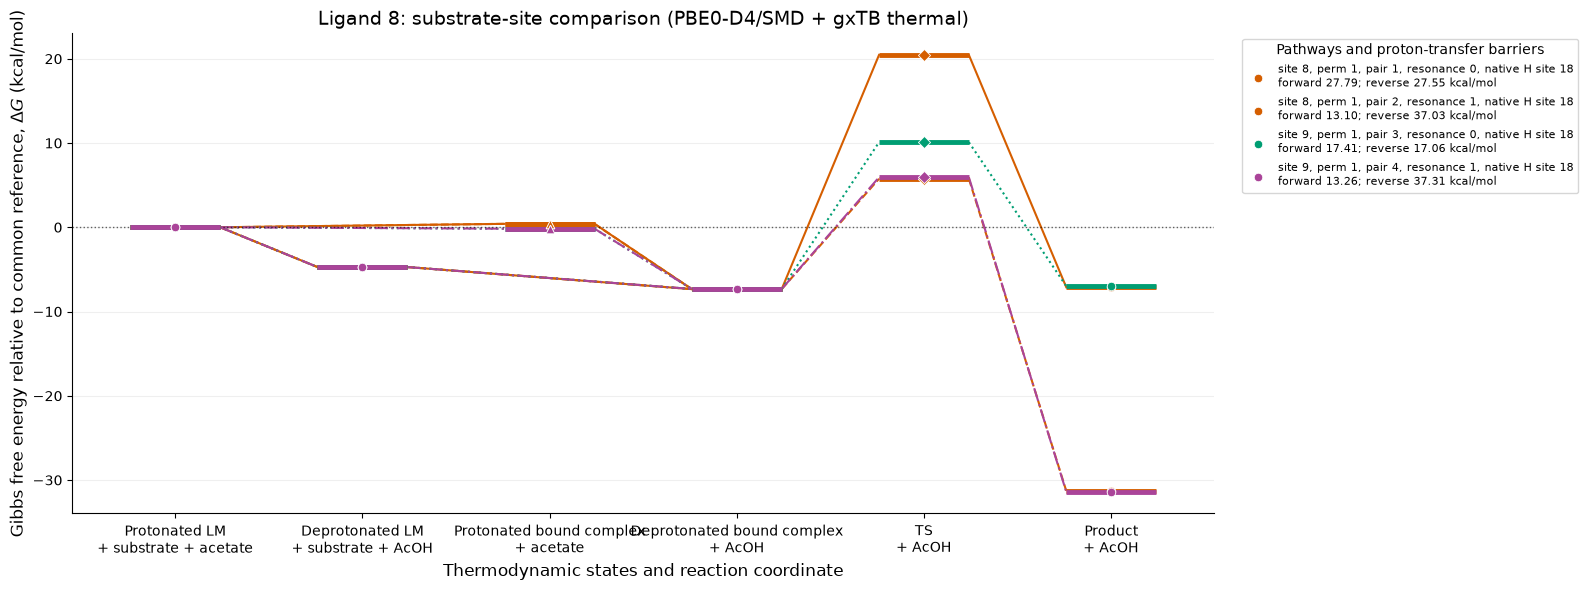

**Ligand atoms for each plotted pathway:** blue = metal-binding; red = H-acceptor; purple = both. Grid legends give forward and reverse proton-transfer barriers in kcal/mol.

**Both barriers ≤ 25 kcal/mol**

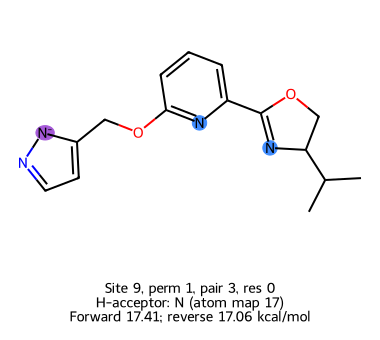

**Other pathways — at least one barrier > 25 kcal/mol**

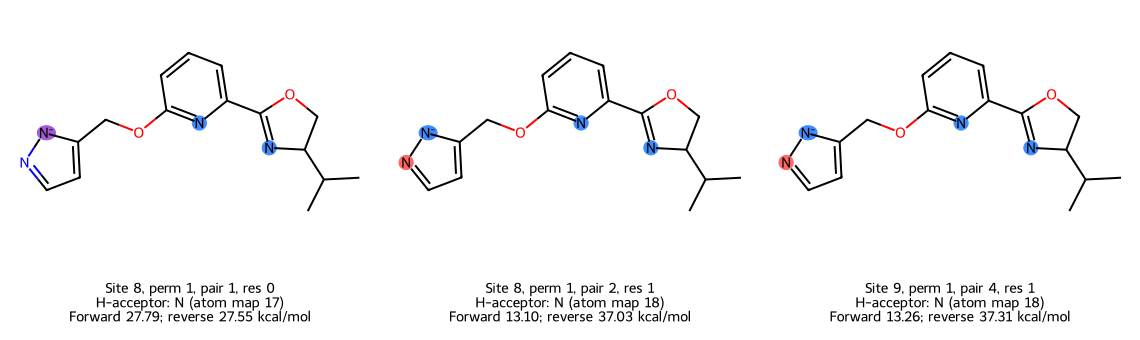

### Lowest-reactant pathway: site 8, permutation 1, pair 1

**Reactant** — $G = -1736.17377222$ Eh

Pd38 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


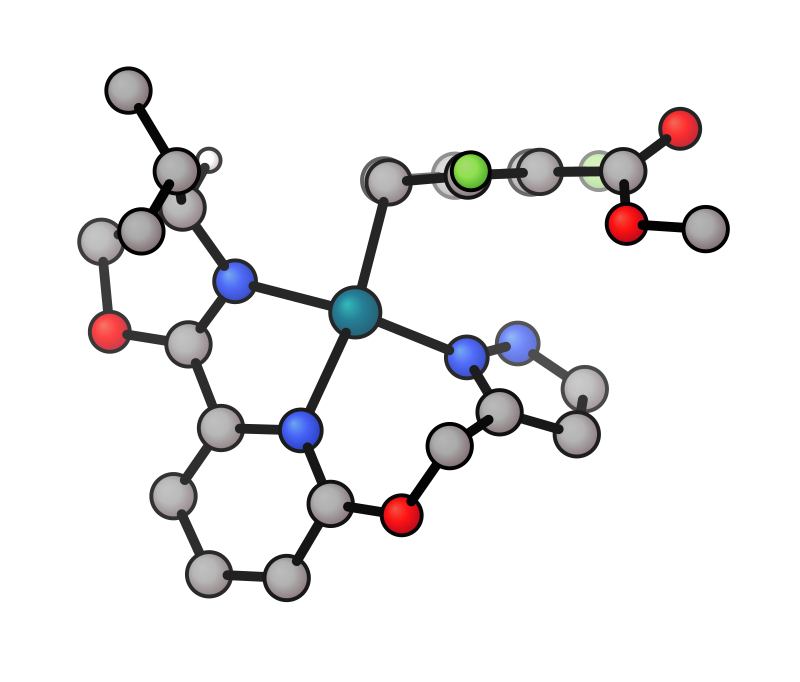

**Transition state** — $G = -1736.12947905$ Eh

Pd38 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


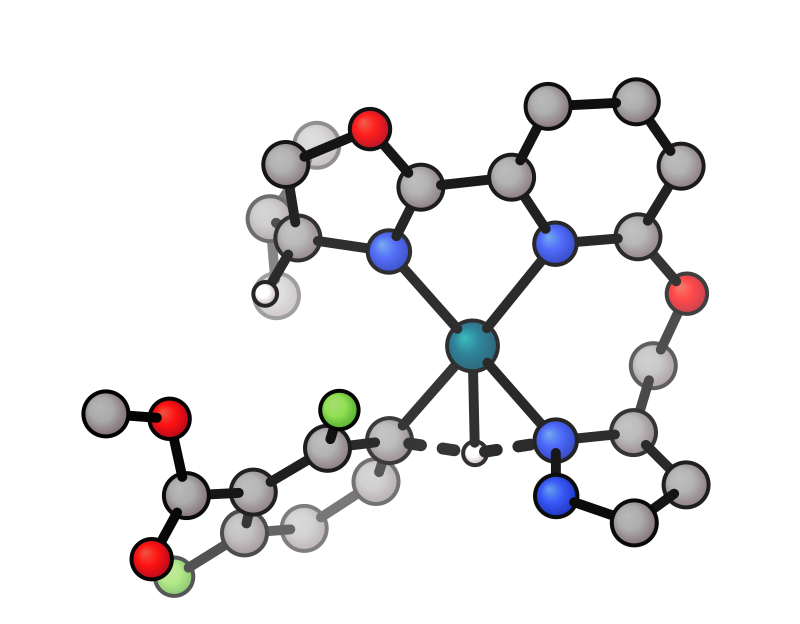

**Product** — $G = -1736.17338693$ Eh

Pd38 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


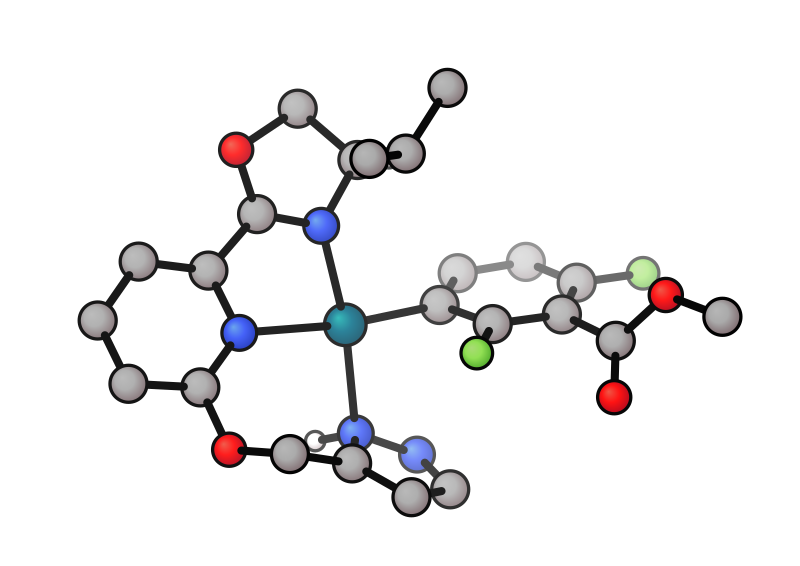

### Ligand 9: permutation coverage by site

Site,Expected permutations,Drawn,Missing,Drawn IDs,Missing IDs,Pathways drawn / recorded
8,1,1,0,1,none,2 / 2
9,1,1,0,1,none,2 / 2


**Precursor minima and calculation coverage**

Species,Permutation,Native protonation site,Charge,gxTB job,Conformer,DFT job,G plotted (Eh),gxTB jobs
9: deprotonated,1,—,1,485,5,262,-1038.83980363,10 succeeded
"9: protonated_bound, pair 1, seating 4",1,17,2,486,6,313,-1697.35555109,10 succeeded
"9: protonated_bound, pair 3, seating 4",1,17,2,496,6,314,-1697.35650521,10 succeeded
9: protonated,1,17,2,496,6,263,-1039.28261662,10 succeeded
substrate_001: substrate,0,—,0,506,6,264,-658.07588733,10 succeeded


**Common reference:** lowest completed protonated LM + substrate + acetate; G = -1925.81634721 Eh. All plotted sites and permutations for this ligand share this zero.

### Ligand 9: balanced pathway comparison (kcal/mol)

Site,Permutation,Pair,Resonance,Native protonation site,Protonated LM + substrate + acetate,Deprotonated LM + substrate + AcOH,Protonated bound complex + acetate,Deprotonated bound complex + AcOH,TS + AcOH,Product + AcOH,Forward barrier,Reverse barrier,Both ≤ 25?,Reaction energy
8,1,1,0,17,+0.00,-5.83,+1.85,-8.72,+28.31,-3.70,+37.03,+32.01,no,+5.02
8,1,2,1,17,+0.00,-5.83,+1.85,-8.72,+1.43,-30.20,+10.14,+31.63,no,-21.49
9,1,3,0,17,+0.00,-5.83,+1.25,-8.16,+31.41,-4.06,+39.57,+35.47,no,+4.10
9,1,4,1,17,+0.00,-5.83,+1.25,-8.16,+6.20,-29.98,+14.36,+36.18,no,-21.82


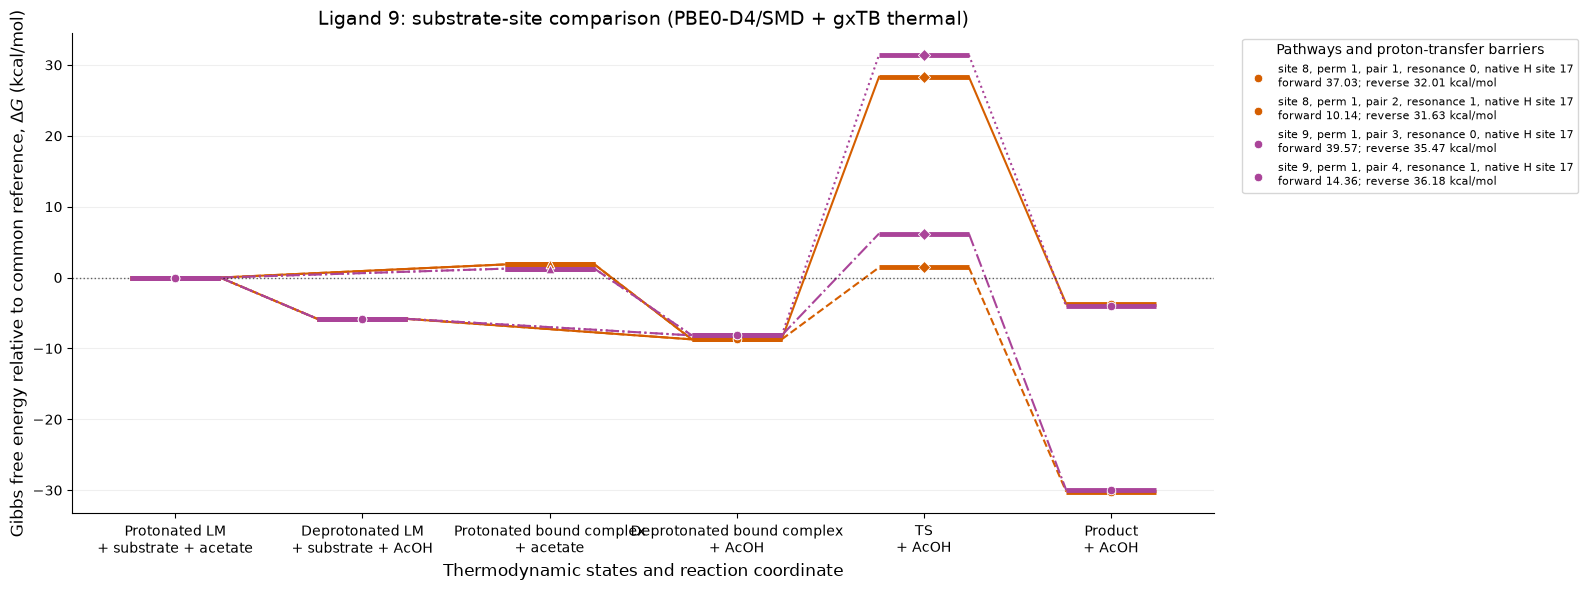

**Ligand atoms for each plotted pathway:** blue = metal-binding; red = H-acceptor; purple = both. Grid legends give forward and reverse proton-transfer barriers in kcal/mol.

**Other pathways — at least one barrier > 25 kcal/mol**

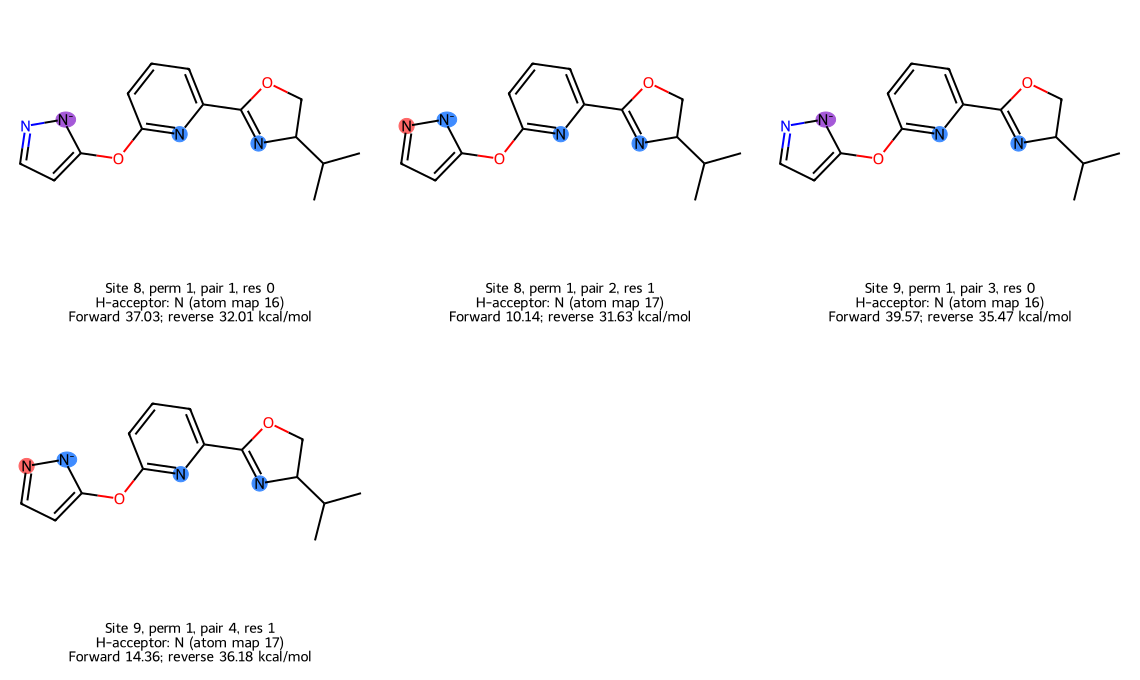

### Lowest-reactant pathway: site 8, permutation 1, pair 1

**Reactant** — $G = -1696.92029243$ Eh

Pd35 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


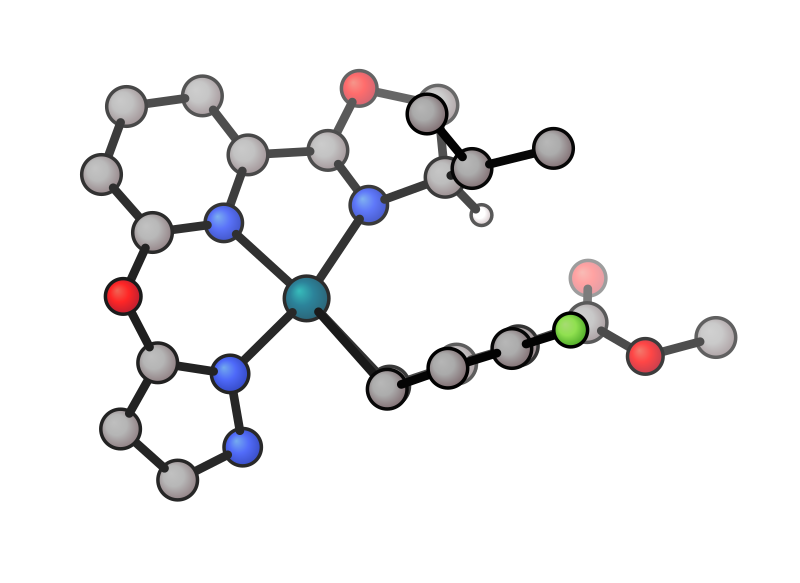

**Transition state** — $G = -1696.86127906$ Eh

Pd35 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


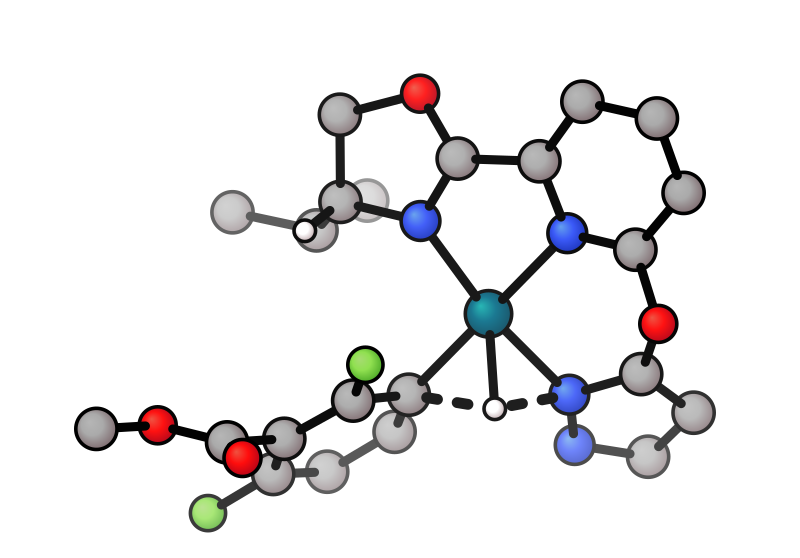

**Product** — $G = -1696.91228852$ Eh

Pd35 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


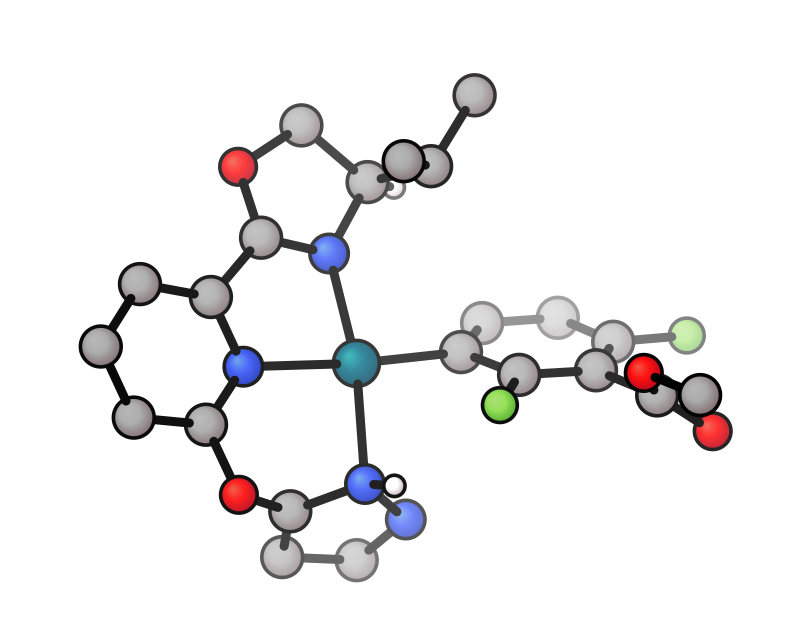

### Ligand 10: permutation coverage by site

Site,Expected permutations,Drawn,Missing,Drawn IDs,Missing IDs,Pathways drawn / recorded
8,1,1,0,1,none,2 / 2
9,1,1,0,1,none,2 / 2


**Precursor minima and calculation coverage**

Species,Permutation,Native protonation site,Charge,gxTB job,Conformer,DFT job,G plotted (Eh),gxTB jobs
10: deprotonated,1,—,1,30,10,216,-886.14765685,10 succeeded
10: protonated,1,4,2,40,10,217,-886.59227799,"2 failed, 8 succeeded"
"10: protonated_bound, pair 1, seating 4",1,4,2,27,7,267,-1544.66817657,10 succeeded
"10: protonated_bound, pair 3, seating 4",1,4,2,38,8,268,-1544.66798528,10 succeeded
substrate_001: substrate,0,—,0,506,6,264,-658.07588733,10 succeeded


**Common reference:** lowest completed protonated LM + substrate + acetate; G = -1773.12600858 Eh. All plotted sites and permutations for this ligand share this zero.

### Ligand 10: balanced pathway comparison (kcal/mol)

Site,Permutation,Pair,Resonance,Native protonation site,Protonated LM + substrate + acetate,Deprotonated LM + substrate + AcOH,Protonated bound complex + acetate,Deprotonated bound complex + AcOH,TS + AcOH,Product + AcOH,Forward barrier,Reverse barrier,Both ≤ 25?,Reaction energy
8,1,1,0,4,+0.00,-4.70,-0.01,-6.83,+22.42,-4.47,+29.25,+26.89,no,+2.36
8,1,2,1,4,+0.00,-4.70,-0.01,-6.83,+0.90,-28.32,+7.73,+29.21,no,-21.48
9,1,3,0,4,+0.00,-4.70,+0.11,-6.93,+25.59,-5.42,+32.52,+31.01,no,+1.50
9,1,4,1,4,+0.00,-4.70,+0.11,-6.93,+6.23,-28.15,+13.15,+34.38,no,-21.23


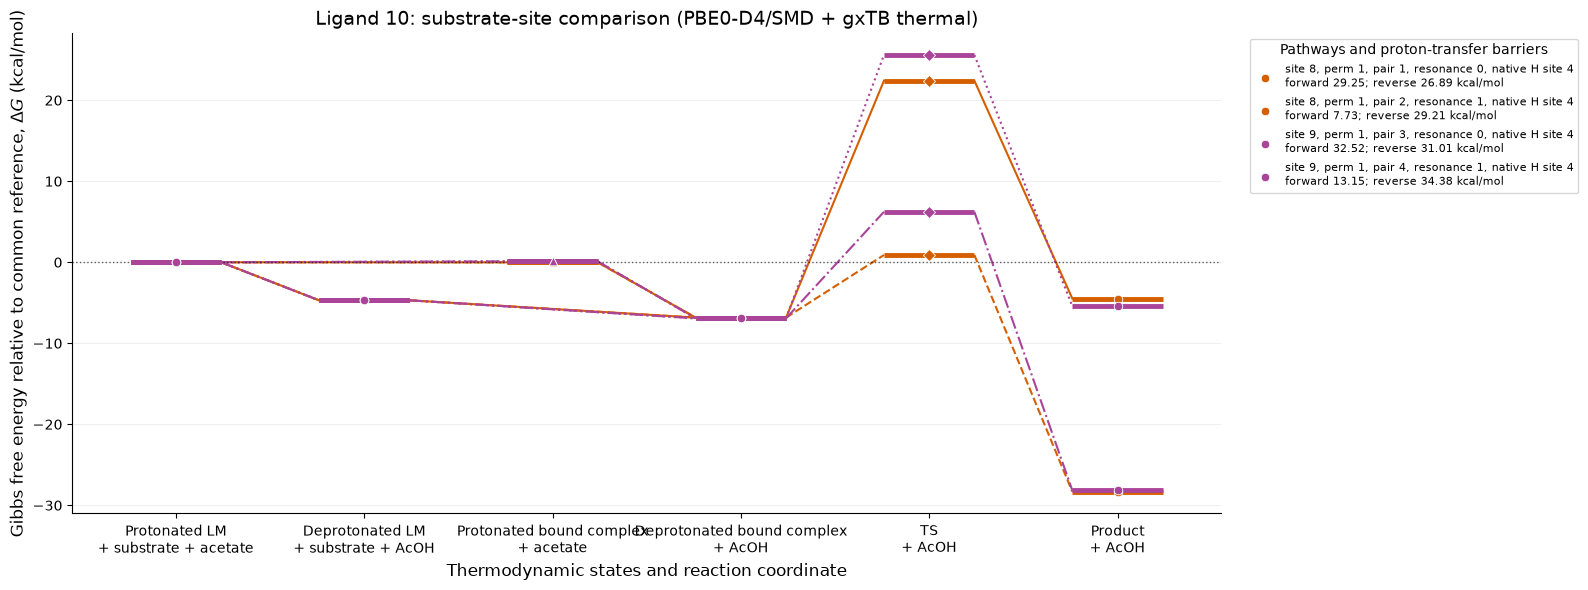

**Ligand atoms for each plotted pathway:** blue = metal-binding; red = H-acceptor; purple = both. Grid legends give forward and reverse proton-transfer barriers in kcal/mol.

**Other pathways — at least one barrier > 25 kcal/mol**

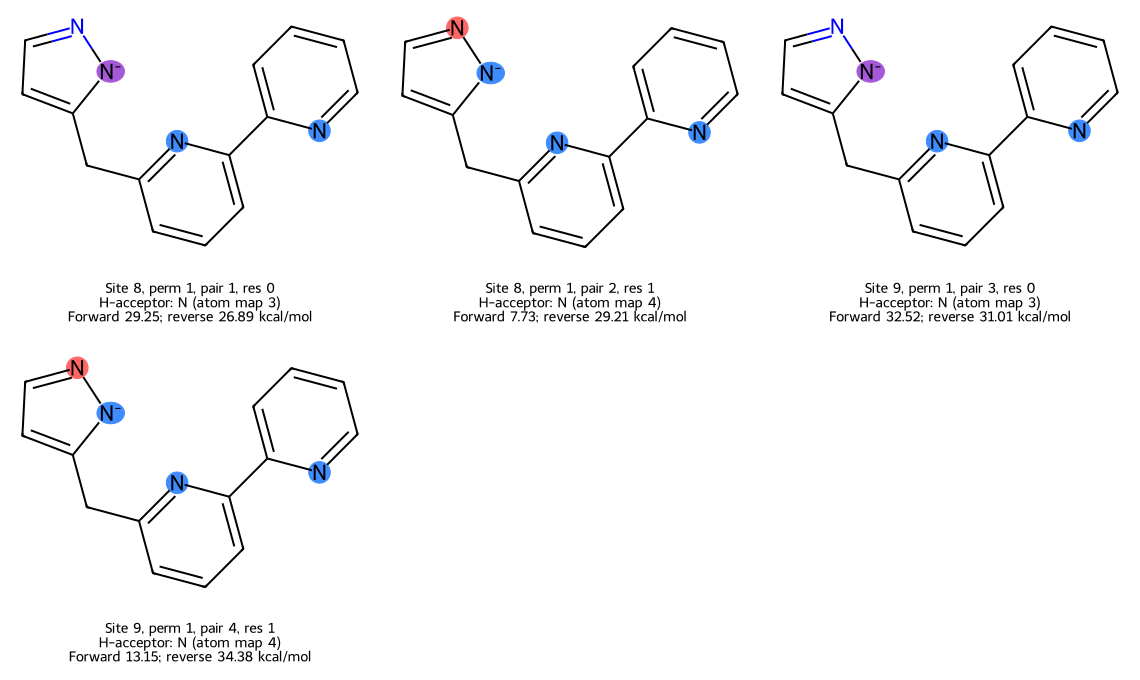

### Lowest-reactant pathway: site 9, permutation 1, pair 3

**Reactant** — $G = -1544.22709885$ Eh

Pd29 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


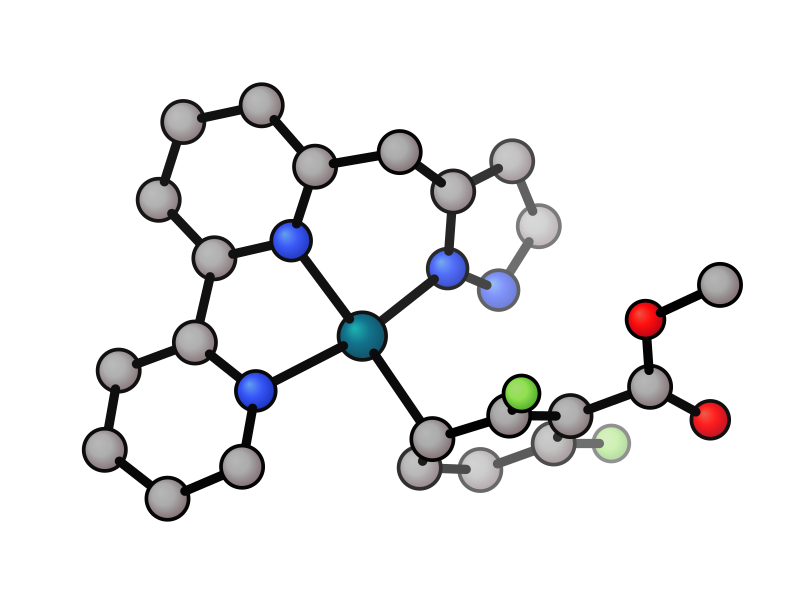

**Transition state** — $G = -1544.17528284$ Eh

Pd29 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


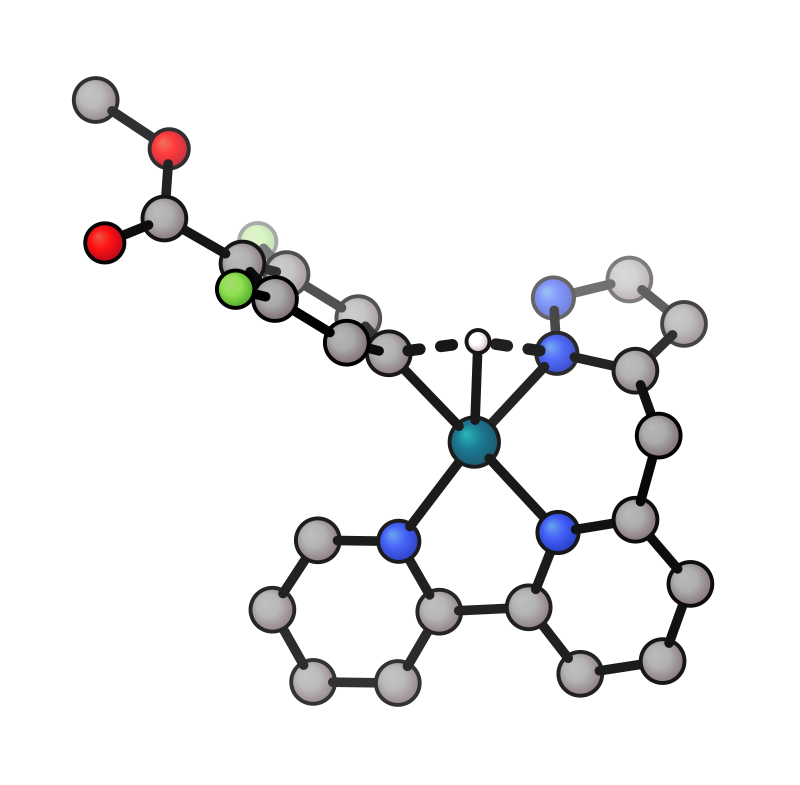

**Product** — $G = -1544.22470444$ Eh

Pd29 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


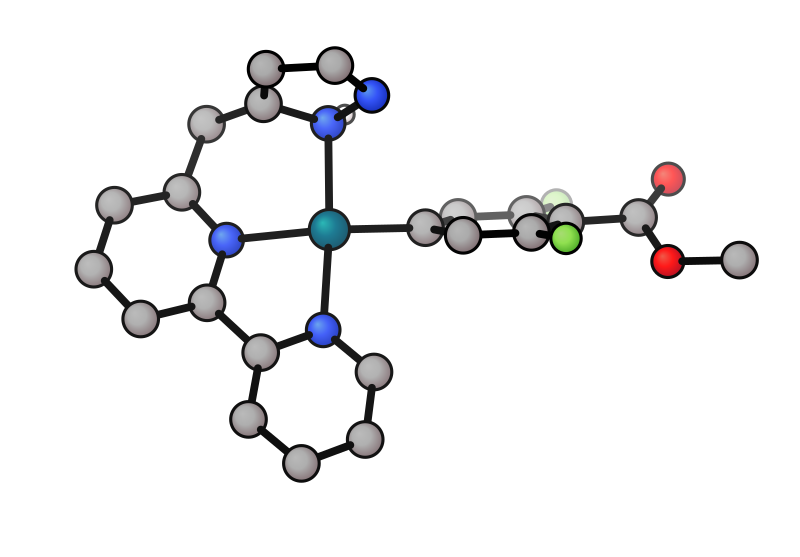

### Ligand 11: permutation coverage by site

Site,Expected permutations,Drawn,Missing,Drawn IDs,Missing IDs,Pathways drawn / recorded
8,1,1,0,1,none,2 / 2
9,1,1,0,1,none,2 / 2


**Precursor minima and calculation coverage**

Species,Permutation,Native protonation site,Charge,gxTB job,Conformer,DFT job,G plotted (Eh),gxTB jobs
11: deprotonated,1,—,1,45,5,218,-983.40943616,"3 failed, 7 succeeded"
11: protonated,1,1,2,54,4,219,-983.82678630,10 succeeded
"11: protonated_bound, pair 1, seating 4",1,1,2,50,10,269,-1641.89795773,10 succeeded
"11: protonated_bound, pair 3, seating 4",1,1,2,53,3,270,-1641.89889568,10 succeeded
substrate_001: substrate,0,—,0,506,6,264,-658.07588733,10 succeeded


**Common reference:** lowest completed protonated LM + substrate + acetate; G = -1870.36051690 Eh. All plotted sites and permutations for this ligand share this zero.

### Ligand 11: balanced pathway comparison (kcal/mol)

Site,Permutation,Pair,Resonance,Native protonation site,Protonated LM + substrate + acetate,Deprotonated LM + substrate + AcOH,Protonated bound complex + acetate,Deprotonated bound complex + AcOH,TS + AcOH,Product + AcOH,Forward barrier,Reverse barrier,Both ≤ 25?,Reaction energy
8,1,1,0,1,+0.00,-21.81,+2.96,-22.13,-3.86,-17.08,+18.27,+13.22,yes,+5.05
8,1,2,1,1,+0.00,-21.81,+2.96,-22.04,+28.52,-4.28,+50.56,+32.80,no,+17.76
9,1,3,0,1,+0.00,-21.81,+2.37,-21.10,-0.80,-16.42,+20.30,+15.61,yes,+4.68
9,1,4,1,1,+0.00,-21.81,+2.37,-21.10,+31.32,-4.05,+52.41,+35.36,no,+17.05


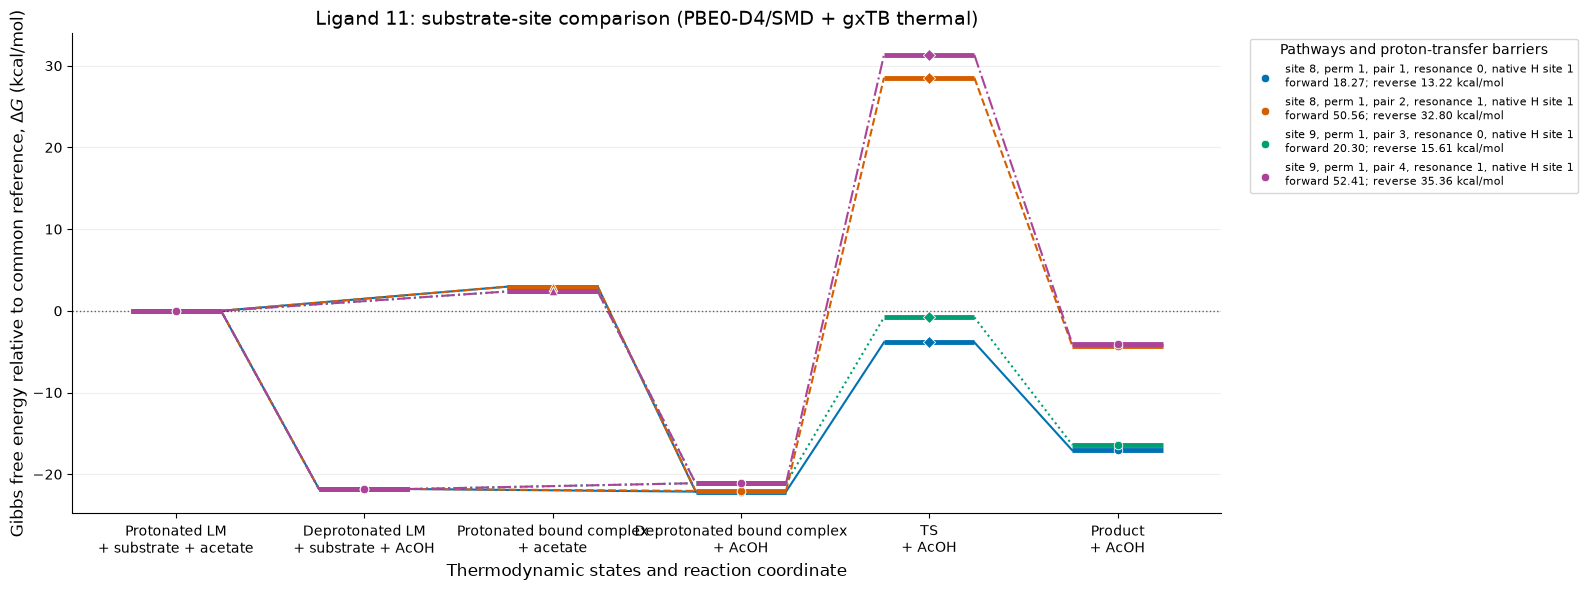

**Ligand atoms for each plotted pathway:** blue = metal-binding; red = H-acceptor; purple = both. Grid legends give forward and reverse proton-transfer barriers in kcal/mol.

**Both barriers ≤ 25 kcal/mol**

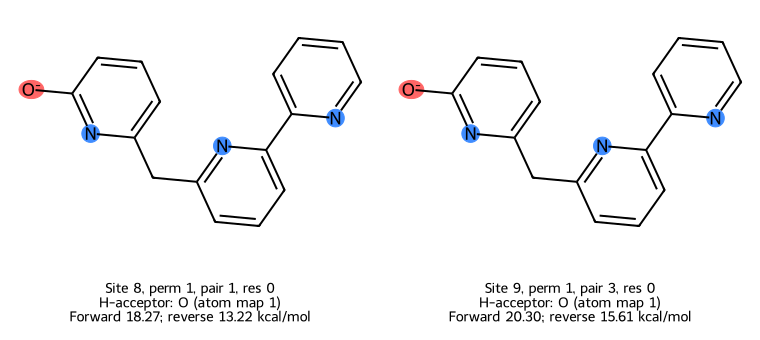

**Other pathways — at least one barrier > 25 kcal/mol**

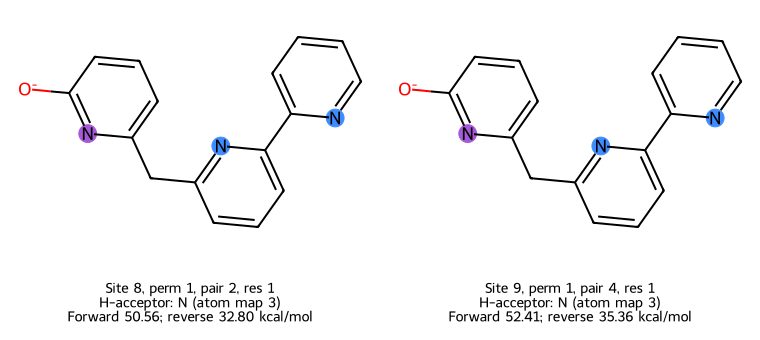

### Lowest-reactant pathway: site 8, permutation 1, pair 1

**Reactant** — $G = -1641.48583784$ Eh

Pd32 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


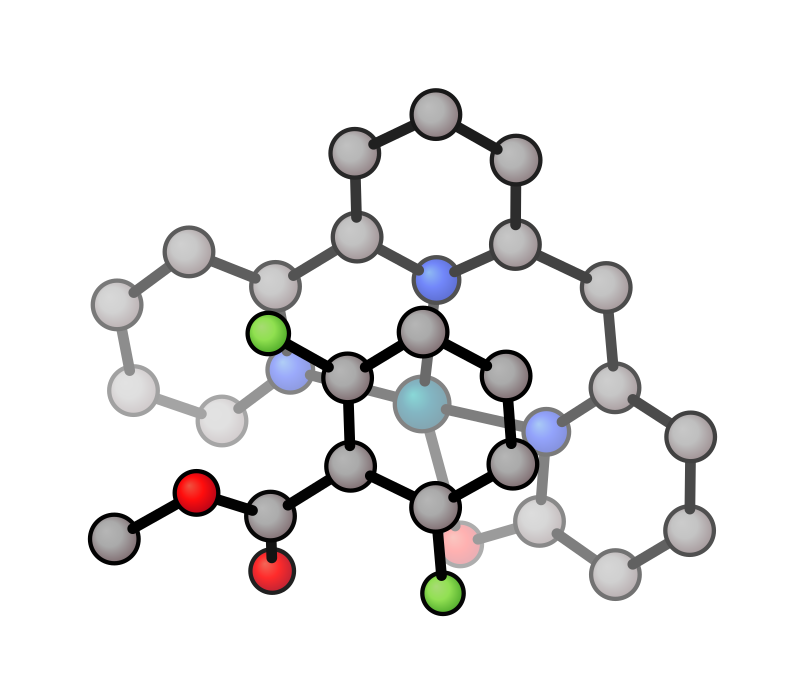

**Transition state** — $G = -1641.45671921$ Eh

Pd32 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


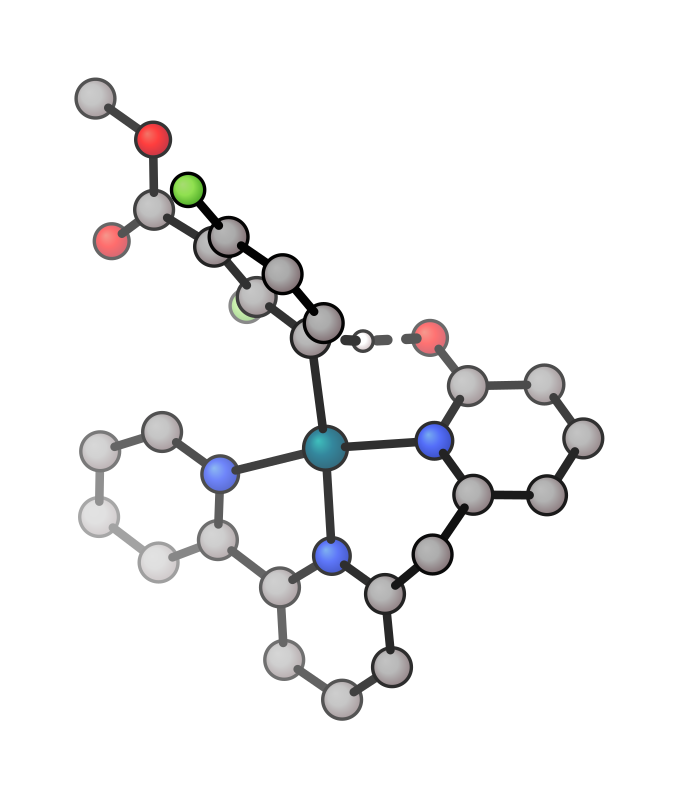

**Product** — $G = -1641.47778590$ Eh

Pd32 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


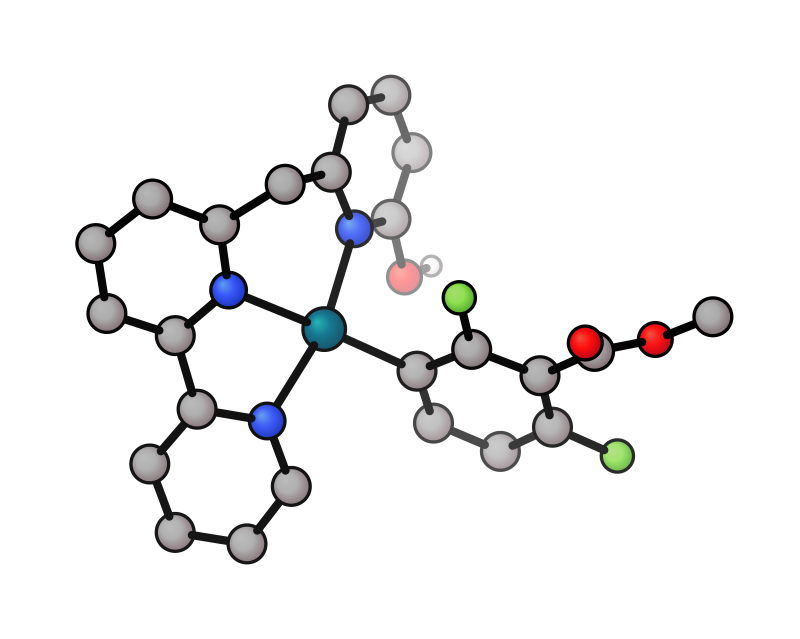

### Ligand 12: permutation coverage by site

Site,Expected permutations,Drawn,Missing,Drawn IDs,Missing IDs,Pathways drawn / recorded
8,1,1,0,1,none,2 / 2
9,1,1,0,1,none,2 / 2


**Precursor minima and calculation coverage**

Species,Permutation,Native protonation site,Charge,gxTB job,Conformer,DFT job,G plotted (Eh),gxTB jobs
12: deprotonated,1,—,1,70,10,220,-944.33341489,10 succeeded
"12: protonated_bound, pair 1, seating 4",1,16,2,66,6,271,-1602.82719854,10 succeeded
"12: protonated_bound, pair 3, seating 4",1,16,2,74,4,272,-1602.82708316,10 succeeded
12: protonated,1,16,2,72,2,221,-944.76034058,10 succeeded
substrate_001: substrate,0,—,0,506,6,264,-658.07588733,10 succeeded


**Common reference:** lowest completed protonated LM + substrate + acetate; G = -1831.29407117 Eh. All plotted sites and permutations for this ligand share this zero.

### Ligand 12: balanced pathway comparison (kcal/mol)

Site,Permutation,Pair,Resonance,Native protonation site,Protonated LM + substrate + acetate,Deprotonated LM + substrate + AcOH,Protonated bound complex + acetate,Deprotonated bound complex + AcOH,TS + AcOH,Product + AcOH,Forward barrier,Reverse barrier,Both ≤ 25?,Reaction energy
8,1,1,0,16,+0.00,-15.80,+5.67,-14.28,+17.67,-26.51,+31.95,+44.18,no,-12.23
8,1,2,1,16,+0.00,-15.80,+5.67,-14.28,+4.19,-29.40,+18.47,+33.59,no,-15.12
9,1,3,0,16,+0.00,-15.80,+5.74,-15.70,+23.64,-26.12,+39.34,+49.77,no,-10.42
9,1,4,1,16,+0.00,-15.80,+5.74,-15.70,+8.25,-29.28,+23.95,+37.54,no,-13.58


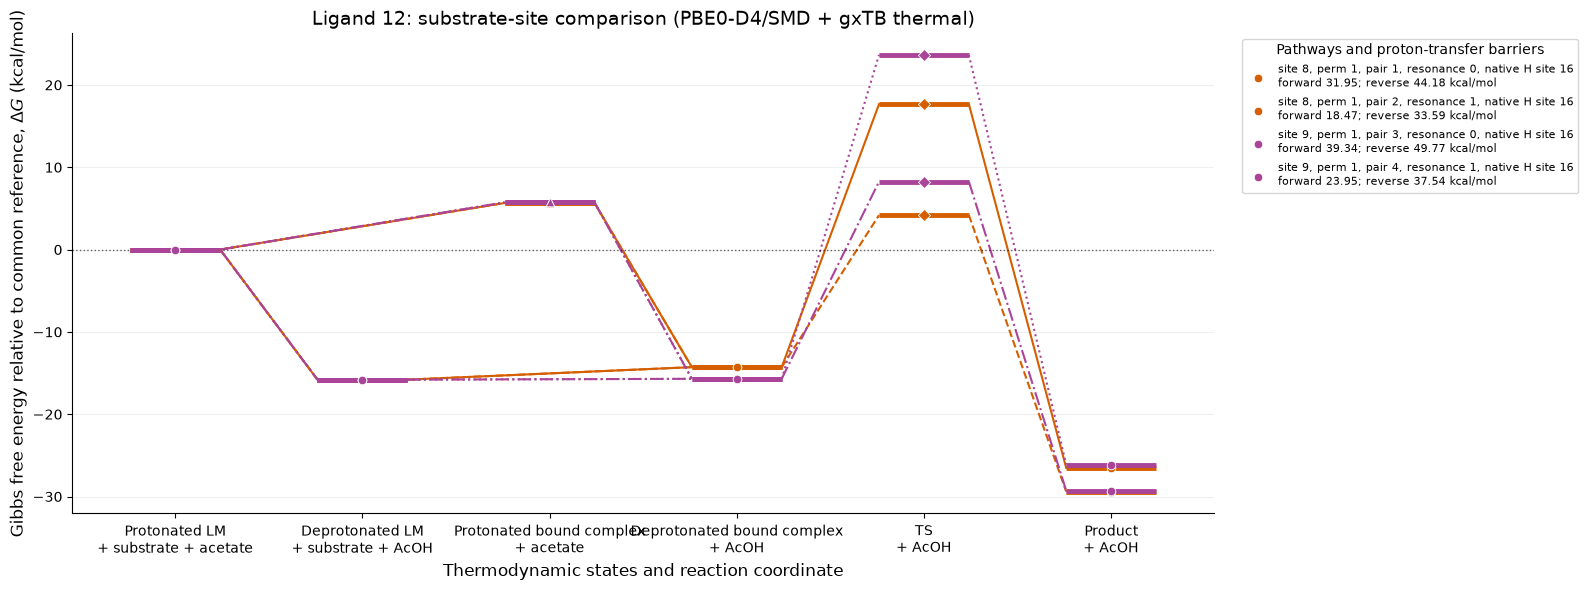

**Ligand atoms for each plotted pathway:** blue = metal-binding; red = H-acceptor; purple = both. Grid legends give forward and reverse proton-transfer barriers in kcal/mol.

**Other pathways — at least one barrier > 25 kcal/mol**

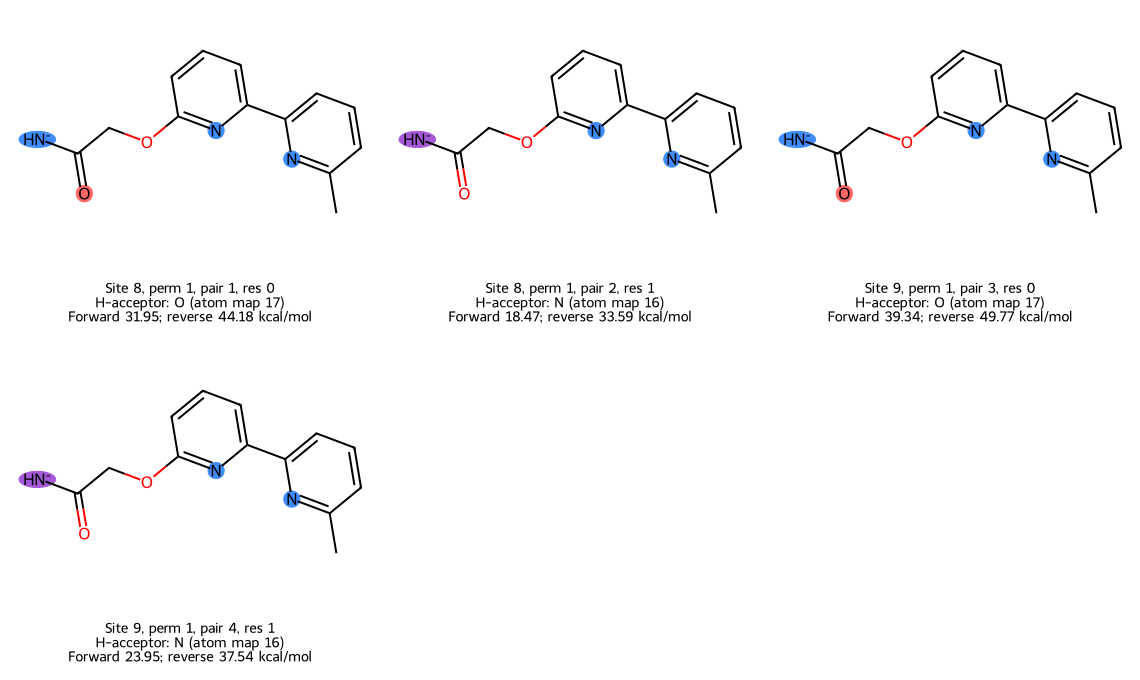

### Lowest-reactant pathway: site 9, permutation 1, pair 3

**Reactant** — $G = -1602.40914092$ Eh

Pd30 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


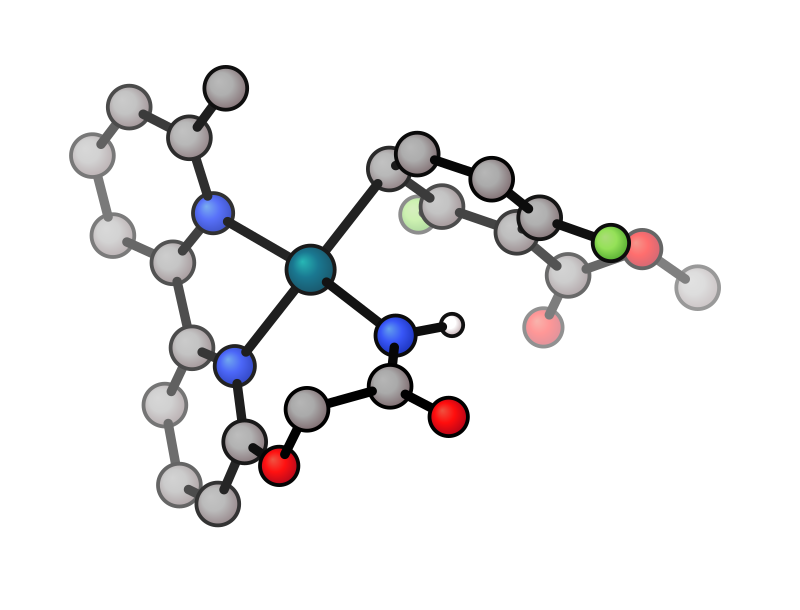

**Transition state** — $G = -1602.34644403$ Eh

Pd30 reads +3 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


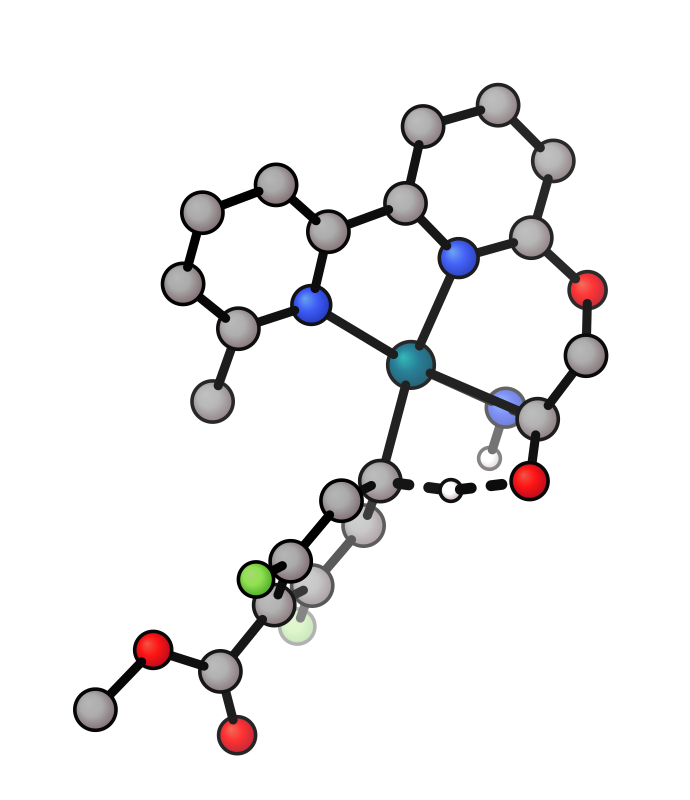

**Product** — $G = -1602.42575160$ Eh

Pd30 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


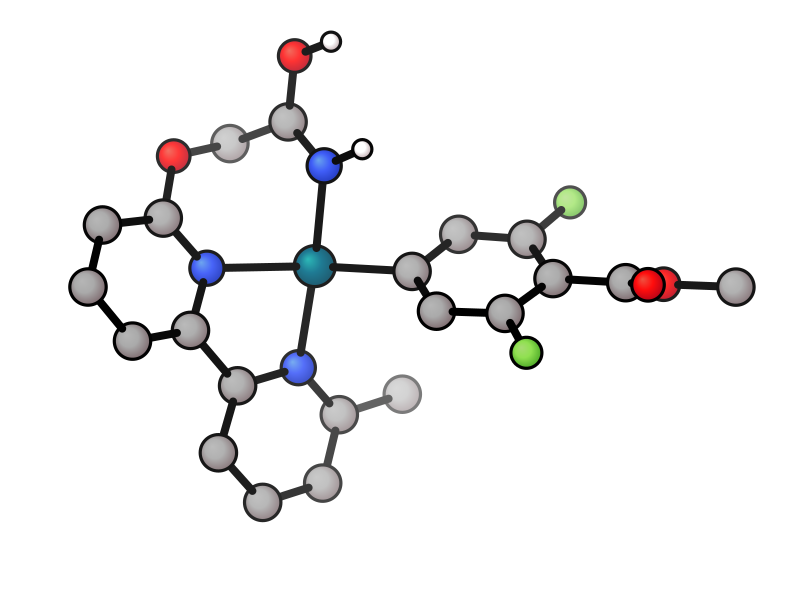

### Ligand 13: permutation coverage by site

Site,Expected permutations,Drawn,Missing,Drawn IDs,Missing IDs,Pathways drawn / recorded
8,1,1,0,1,none,2 / 2
9,1,1,0,1,none,2 / 2


**Precursor minima and calculation coverage**

Species,Permutation,Native protonation site,Charge,gxTB job,Conformer,DFT job,G plotted (Eh),gxTB jobs
13: deprotonated,1,—,1,86,6,222,-981.23695530,"1 failed, 9 succeeded"
13: protonated,1,1,2,96,6,223,-981.66223998,"2 failed, 8 succeeded"
"13: protonated_bound, pair 1, seating 4",1,1,2,83,3,273,-1639.74712520,10 succeeded
"13: protonated_bound, pair 3, seating 4",1,1,2,99,9,274,-1639.74751277,10 succeeded
substrate_001: substrate,0,—,0,506,6,264,-658.07588733,10 succeeded


**Common reference:** lowest completed protonated LM + substrate + acetate; G = -1868.19597057 Eh. All plotted sites and permutations for this ligand share this zero.

### Ligand 13: balanced pathway comparison (kcal/mol)

Site,Permutation,Pair,Resonance,Native protonation site,Protonated LM + substrate + acetate,Deprotonated LM + substrate + AcOH,Protonated bound complex + acetate,Deprotonated bound complex + AcOH,TS + AcOH,Product + AcOH,Forward barrier,Reverse barrier,Both ≤ 25?,Reaction energy
8,1,1,0,1,+0.00,-16.83,-5.65,-23.11,+8.55,-32.00,+31.66,+40.55,no,-8.89
8,1,2,1,1,+0.00,-16.83,-5.65,-23.11,-2.67,-35.52,+20.43,+32.84,no,-12.41
9,1,3,0,1,+0.00,-16.83,-5.89,-23.26,+13.85,-32.60,+37.10,+46.44,no,-9.34
9,1,4,1,1,+0.00,-16.83,-5.89,-23.26,+0.54,-35.33,+23.80,+35.88,no,-12.08


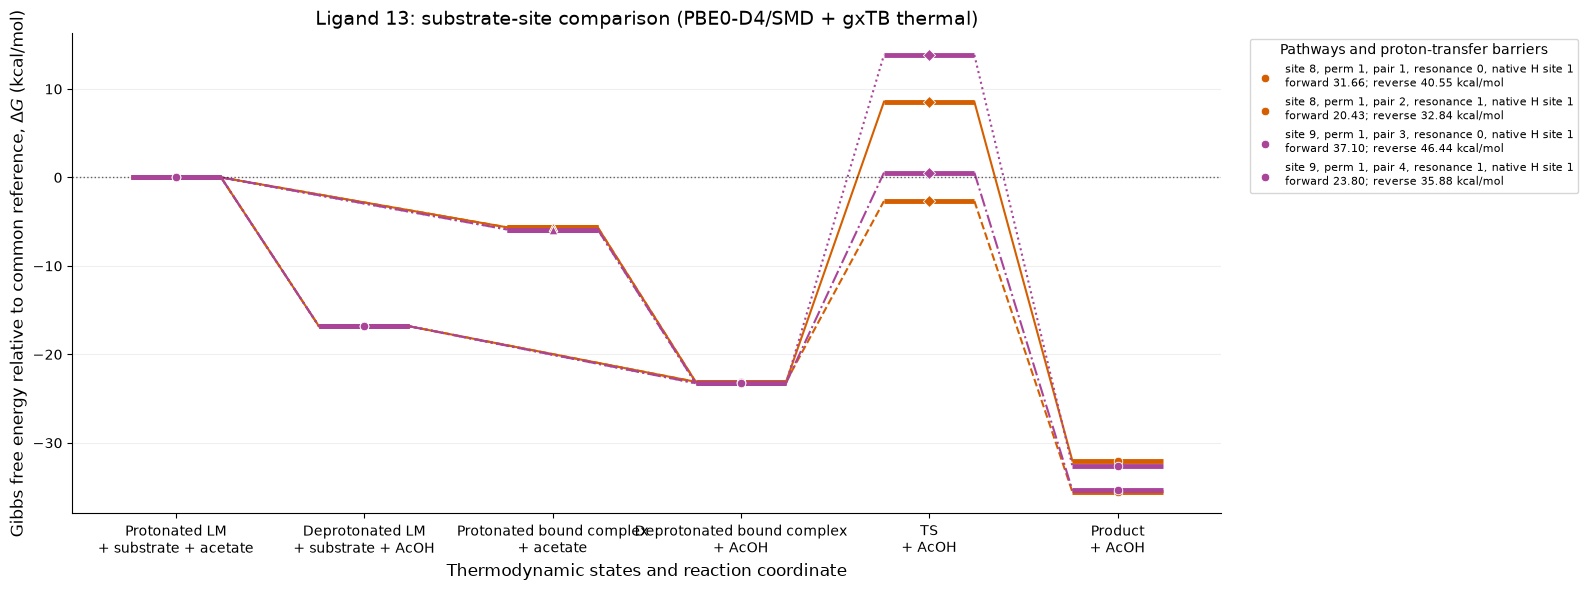

**Ligand atoms for each plotted pathway:** blue = metal-binding; red = H-acceptor; purple = both. Grid legends give forward and reverse proton-transfer barriers in kcal/mol.

**Other pathways — at least one barrier > 25 kcal/mol**

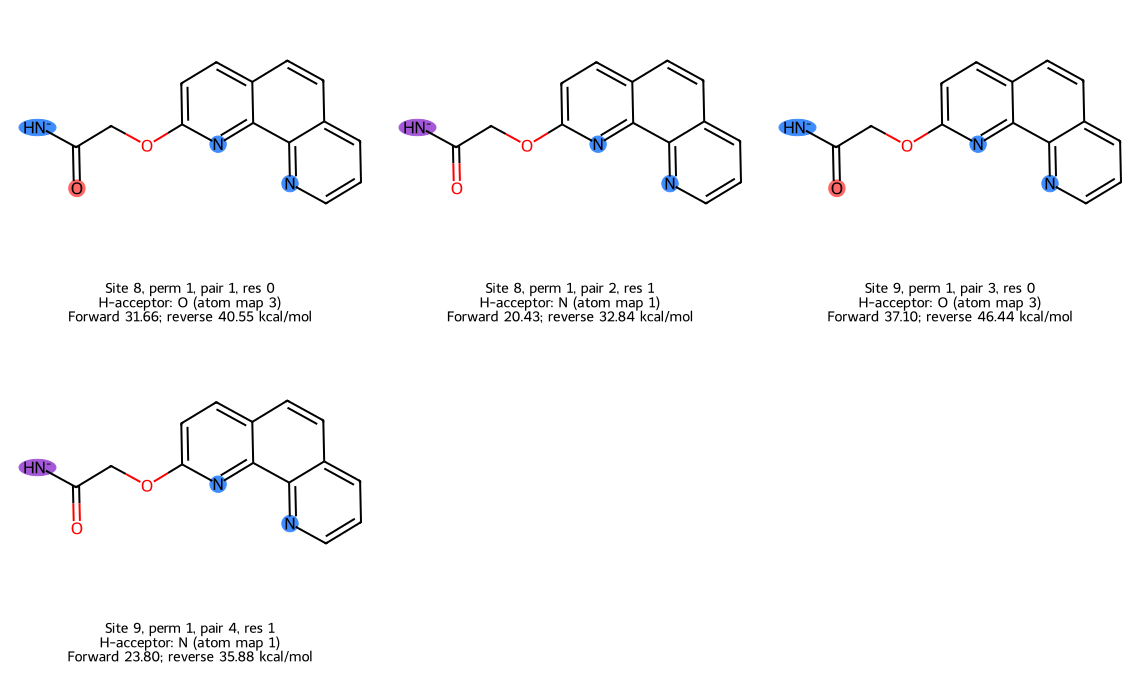

### Lowest-reactant pathway: site 9, permutation 1, pair 4

**Reactant** — $G = -1639.32308513$ Eh

Pd29 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


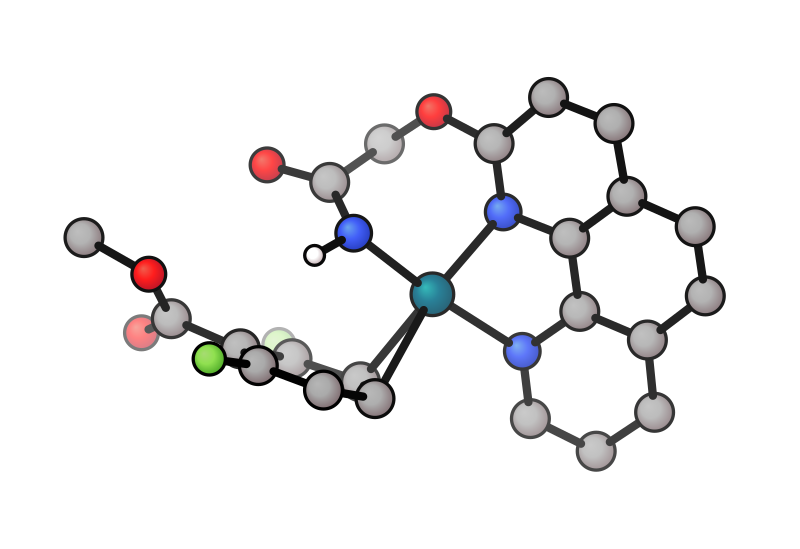

**Transition state** — $G = -1639.28515630$ Eh

Pd29 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


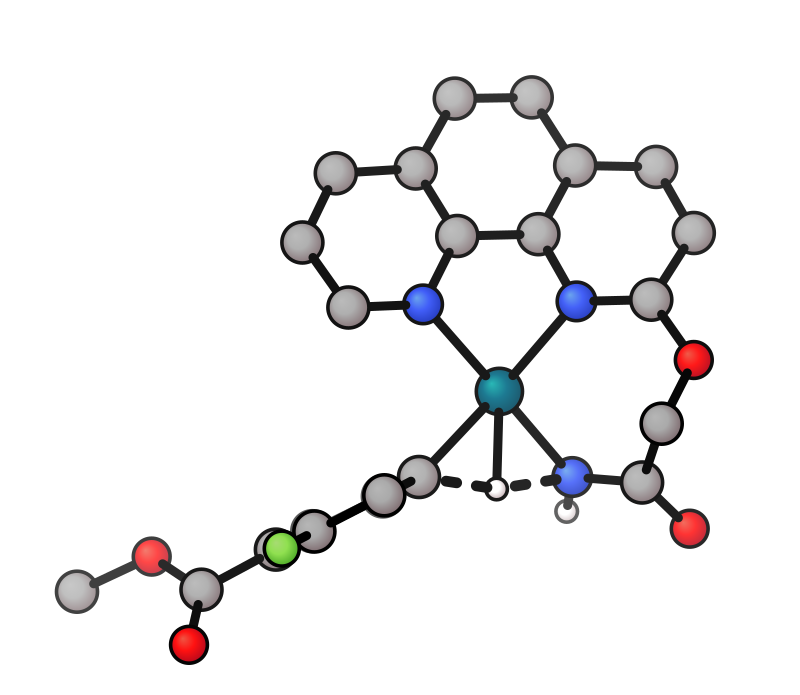

**Product** — $G = -1639.34232822$ Eh

Pd29 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


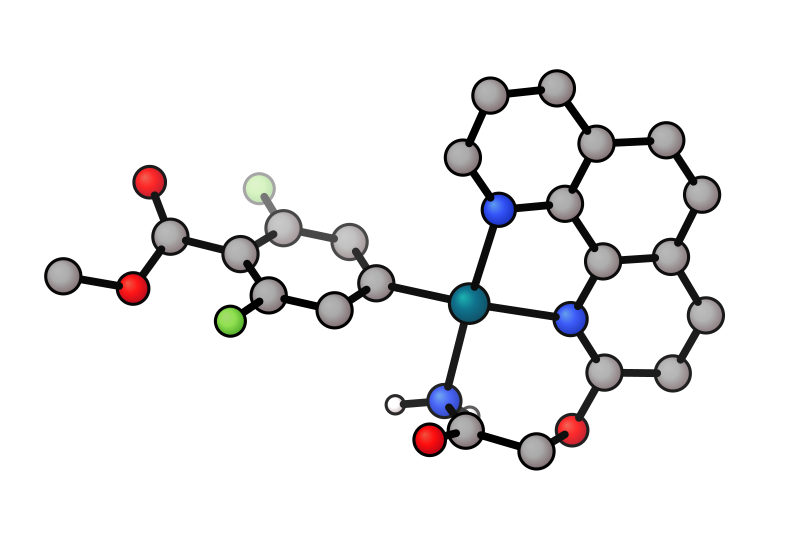

### Ligand 14: permutation coverage by site

Site,Expected permutations,Drawn,Missing,Drawn IDs,Missing IDs,Pathways drawn / recorded
8,2,2,0,"1, 2",none,4 / 4
9,2,2,0,"1, 2",none,4 / 4


**Precursor minima and calculation coverage**

Species,Permutation,Native protonation site,Charge,gxTB job,Conformer,DFT job,G plotted (Eh),gxTB jobs
14: deprotonated,1,—,1,110,10,224,-1001.11828069,"1 failed, 9 succeeded"
14: protonated,1,1,2,119,9,225,-1001.51661822,"3 failed, 7 succeeded"
"14: protonated_bound, pair 1, seating 4",1,1,2,104,4,275,-1659.60158157,10 succeeded
"14: protonated_bound, pair 3, seating 4",1,1,2,119,9,276,-1659.60094972,10 succeeded
14: deprotonated,2,—,1,124,4,226,-1001.11804012,"5 failed, 5 succeeded"
14: protonated,2,1,2,140,10,227,-1001.53349845,"3 failed, 7 succeeded"
"14: protonated_bound, pair 5, seating 4",2,1,2,124,4,277,-1659.62095266,10 succeeded
"14: protonated_bound, pair 7, seating 4",2,1,2,139,9,278,-1659.62259043,10 succeeded
substrate_001: substrate,0,—,0,506,6,264,-658.07588733,10 succeeded


**Common reference:** lowest completed protonated LM + substrate + acetate; G = -1888.06722905 Eh. All plotted sites and permutations for this ligand share this zero.

### Ligand 14: balanced pathway comparison (kcal/mol)

Site,Permutation,Pair,Resonance,Native protonation site,Protonated LM + substrate + acetate,Deprotonated LM + substrate + AcOH,Protonated bound complex + acetate,Deprotonated bound complex + AcOH,TS + AcOH,Product + AcOH,Forward barrier,Reverse barrier,Both ≤ 25?,Reaction energy
8,1,1,0,1,+10.59,-23.15,+4.90,-27.94,-4.83,-24.62,+23.11,+19.80,yes,+3.32
8,1,2,1,1,+10.59,-23.15,+4.90,-27.94,+0.96,-29.99,+28.90,+30.95,no,-2.05
9,1,3,0,1,+10.59,-23.15,+5.29,-28.16,+0.59,-24.56,+28.75,+25.15,no,+3.60
9,1,4,1,1,+10.59,-23.15,+5.29,-28.16,+6.23,-30.22,+34.39,+36.45,no,-2.06
8,2,5,0,1,+0.00,-23.00,-7.26,-27.96,+0.79,-30.21,+28.75,+31.00,no,-2.25
8,2,6,1,1,+0.00,-23.00,-7.26,-27.96,-4.71,-24.87,+23.25,+20.16,yes,+3.09
9,2,7,0,1,+0.00,-23.00,-8.29,-28.12,+6.45,-30.16,+34.57,+36.61,no,-2.04
9,2,8,1,1,+0.00,-23.00,-8.29,-28.12,+0.82,-23.88,+28.94,+24.70,no,+4.24


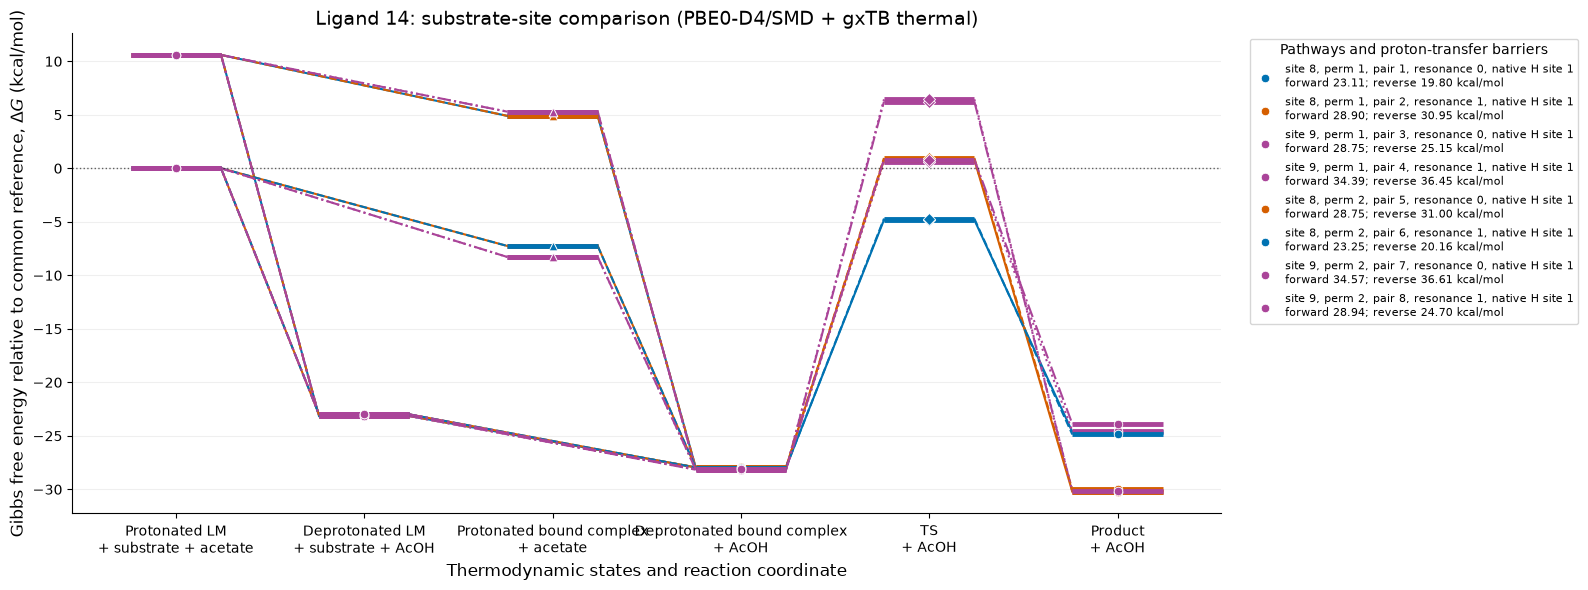

**Ligand atoms for each plotted pathway:** blue = metal-binding; red = H-acceptor; purple = both. Grid legends give forward and reverse proton-transfer barriers in kcal/mol.

**Both barriers ≤ 25 kcal/mol**

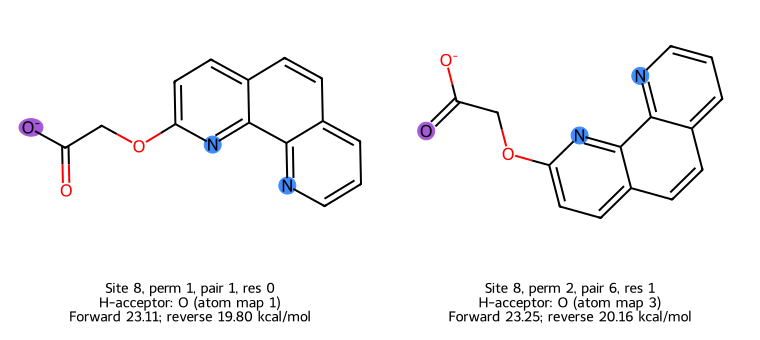

**Other pathways — at least one barrier > 25 kcal/mol**

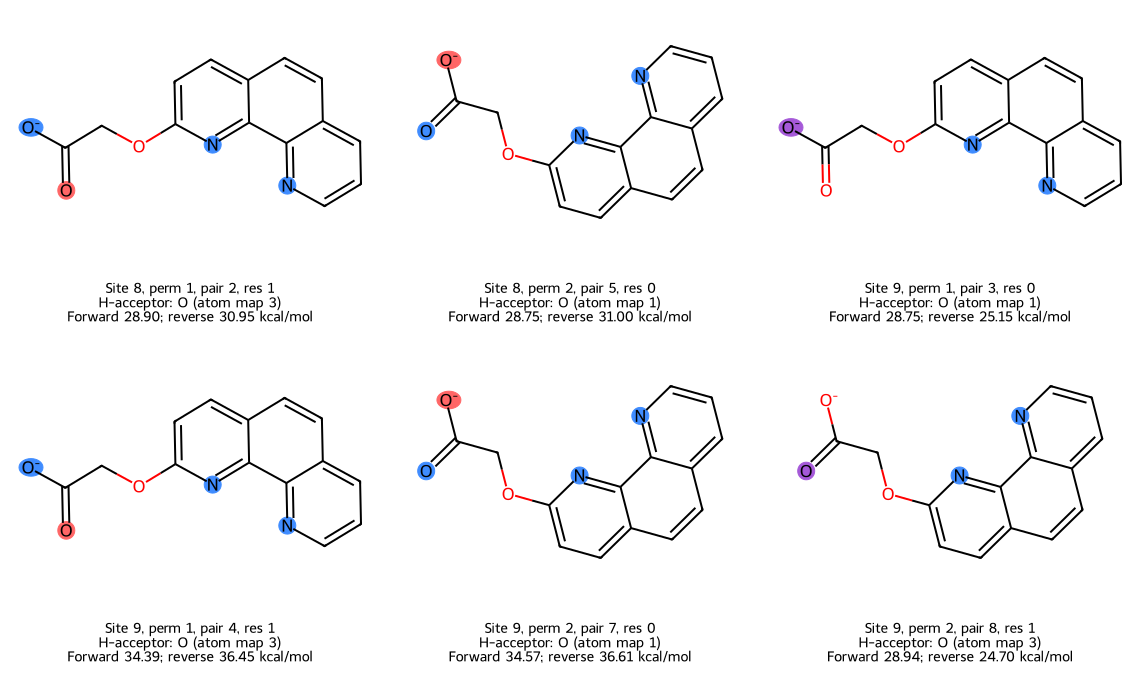

### Lowest-reactant pathway: site 9, permutation 1, pair 3

**Reactant** — $G = -1659.20215265$ Eh

Pd28 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


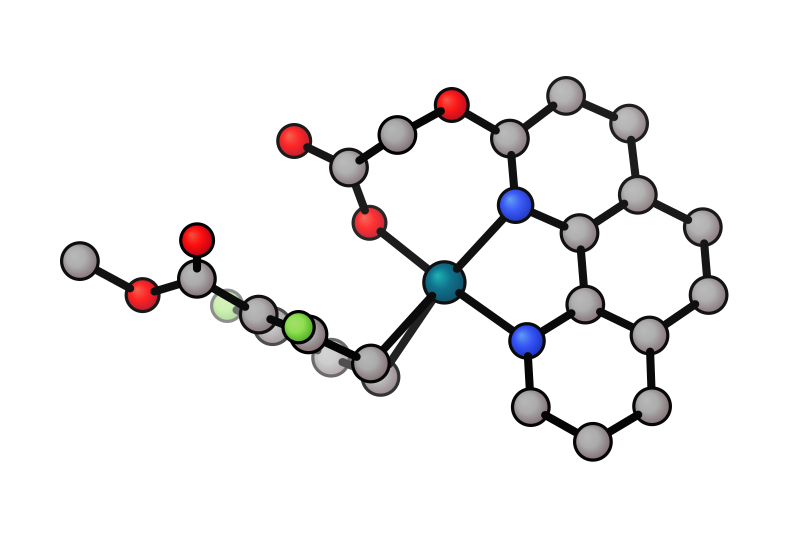

**Transition state** — $G = -1659.15634157$ Eh

Pd28 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


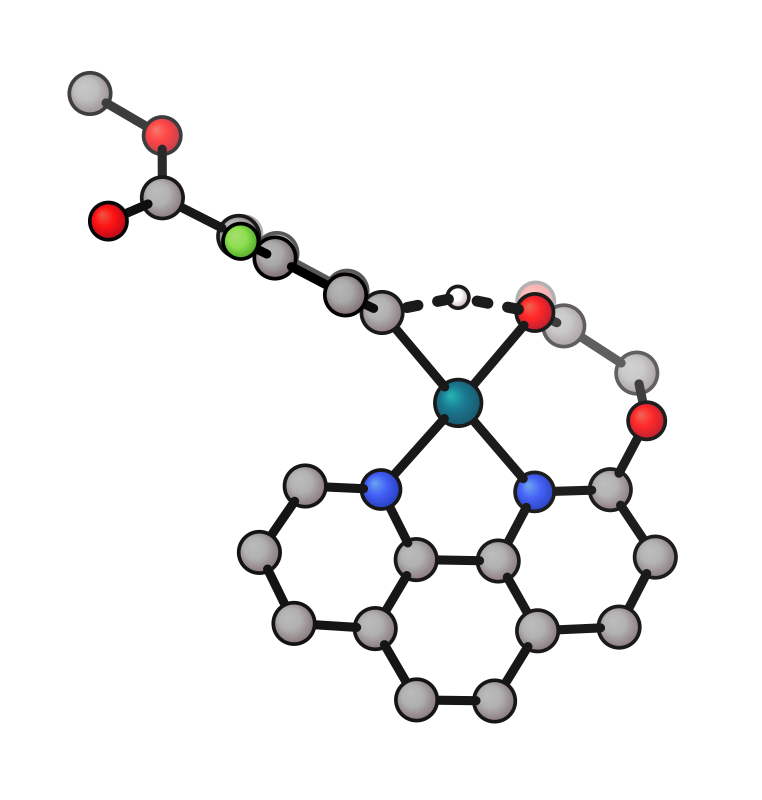

**Product** — $G = -1659.19641808$ Eh

Pd28 reads +1 at charge=+0, not one of its usual oxidation states [0, 2, 4]; check charge=


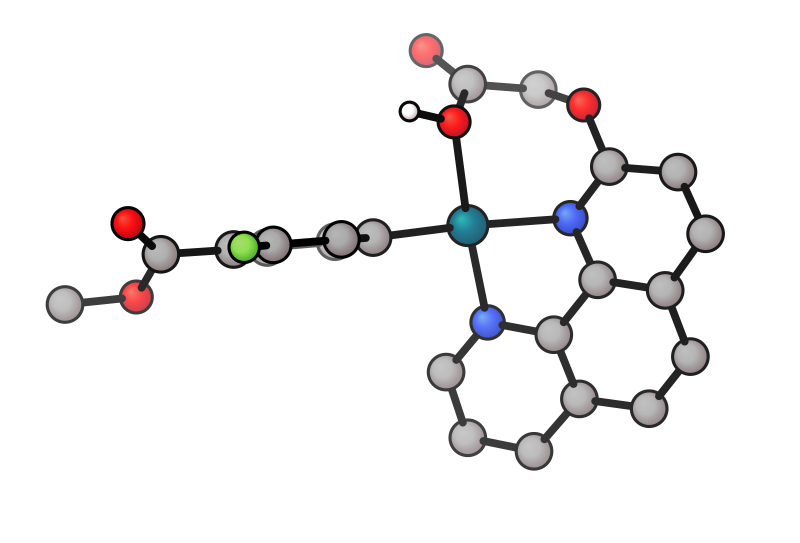

In [15]:
half_width = 0.24
ligand_ids = coverage_by_ligand
diagram_rows = []  # Numerical balanced-state results, also available for inspection/export.

for ligand_id in ligand_ids:
    group = [row for row in profiles if row["ligand_id"] == ligand_id]
    coverage = coverage_by_ligand[ligand_id]
    compared = coverage["profiles"]
    display(Markdown(f"### Ligand {ligand_id}: permutation coverage by site"))
    table = ("<table><thead><tr><th>Site</th><th>Expected permutations</th><th>Drawn</th>"
             "<th>Missing</th><th>Drawn IDs</th><th>Missing IDs</th><th>Pathways drawn / recorded</th></tr></thead><tbody>")
    for item in coverage["sites"]:
        site = identifier_list([item["site"]])
        table += (f"<tr><td>{escape(site)}</td><td>{item['expected']}</td>"
                  f"<td>{len(item['shown'])}</td><td>{len(item['missing'])}</td>"
                  f"<td>{escape(identifier_list(item['shown']))}</td>"
                  f"<td>{escape(identifier_list(item['missing']))}</td>"
                  f"<td>{item['pathways_drawn']} / {item['pathways_expected']}</td></tr>")
    display(HTML(table + "</tbody></table>"))
    details = [(item["site"], permutation, reason) for item in coverage["sites"]
               for permutation, reason in item["details"]]
    if details:
        table = ("<table><thead><tr><th>Site</th><th>Permutation</th>"
                 "<th>Why no complete profile?</th></tr></thead><tbody>")
        for site, permutation, reason in details:
            table += (f"<tr><td>{escape(identifier_list([site]))}</td>"
                      f"<td>{escape(identifier_list([permutation]))}</td>"
                      f"<td>{escape(reason)}</td></tr>")
        display(HTML(table + "</tbody></table>"))
    display(Markdown("**Precursor minima and calculation coverage**"))
    species_groups = defaultdict(list)
    substrate_ids = {row["substrate_id"] for row in precursor_references if row["ligand_id"] == ligand_id}
    for row in precursor_jobs + bound_reactant_jobs:
        if row["ligand_id"] == ligand_id or row["ligand_id"] in substrate_ids:
            identity = (row["ligand_id"], row["binding_permutation"], row["seating"], row["endpoint"],
                        row["pair_index"] if row["endpoint"] == "protonated_bound" else 0,
                        row.get("protonation_site", 0))
            species_groups[identity].append(row)
    if species_groups:
        show_species_table([(f"{identity[0]}: {identity[3]}" +
                             (f", pair {identity[4]}, seating {identity[2]}" if identity[3] == "protonated_bound" else ""), rows)
                            for identity, rows in sorted(species_groups.items())])
    else:
        display(Markdown("No precursor calculations are recorded for this ligand yet."))
    if not compared:
        display(Markdown("No complete reactant–TS–product profiles yet."))
        continue
    diagram = energy_diagram(ligand_id, compared, precursor_references, acid_gibbs_eh)
    reference = diagram["reference"]
    state_keys, labels = diagram["state_keys"], diagram["labels"]
    x = list(range(len(state_keys)))
    display(Markdown(f"**Common reference:** {diagram['reference_label']}; G = {reference:.8f} Eh. "
                     "All plotted sites and permutations for this ligand share this zero."))
    unavailable = [route for route in diagram["routes"] if route["missing"]]
    if unavailable:
        table = ("<table><thead><tr><th>Site</th><th>Permutation</th><th>Pair</th>"
                 "<th>Unavailable precursor inputs (levels left blank)</th></tr></thead><tbody>")
        for route in unavailable:
            row = route["profile"]
            table += (f"<tr><td>{row['substrate_site']}</td><td>{row['binding_permutation']}</td>"
                      f"<td>{row['pair_index']}</td><td>{escape('; '.join(route['missing']))}</td></tr>")
        display(HTML(table + "</tbody></table>"))

    display(Markdown(f"### Ligand {ligand_id}: balanced pathway comparison (kcal/mol)"))
    headers = ["Site", "Permutation", "Pair", "Resonance", "Native protonation site"]
    headers += [label.replace("\n", " ") for label in labels]
    headers += ["Forward barrier", "Reverse barrier", f"Both ≤ {BARRIER_LIMIT_KCAL:g}?", "Reaction energy"]
    table = "<table><thead><tr>" + "".join(f"<th>{escape(header)}</th>" for header in headers) + "</tr></thead><tbody>"
    for route in diagram["routes"]:
        row, relative = route["profile"], route["relative"]
        barrier = route["forward_barrier_kcal_mol"]
        reverse_barrier = route["reverse_barrier_kcal_mol"]
        reaction = (row["product"] - row["reactant"]) * HARTREE_TO_KCAL
        values = [row["substrate_site"], row["binding_permutation"], row["pair_index"], row["resonance"],
                  route["protonation_site"] if route["protonation_site"] is not None else "—"]
        values += [format_energy(relative[state]) for state in state_keys]
        values += [format_energy(barrier), format_energy(reverse_barrier),
                   "yes" if route["both_barriers_within_limit"] else "no", format_energy(reaction)]
        table += "<tr>" + "".join(f"<td>{escape(str(value))}</td>" for value in values) + "</tr>"
        diagram_rows.append(dict(ligand_id=ligand_id, substrate_site=row["substrate_site"],
            binding_permutation=row["binding_permutation"], pair_index=row["pair_index"],
            seating=row["seating"], resonance=row["resonance"], protonation_site=route["protonation_site"],
            reference_eh=reference, reference_label=diagram["reference_label"], energy_model=inputs["energy_model"],
            absolute_gibbs_eh=route["energies"], relative_kcal_mol=relative,
            barrier_from_reactant_kcal_mol=barrier, reverse_barrier_kcal_mol=reverse_barrier,
            both_barriers_within_limit=route["both_barriers_within_limit"], reaction_energy_kcal_mol=reaction,
            singlepoint_job_ids={name: row[row_key].get("singlepoint_job_id")
                                 for name, row_key in (("reactant", "reactant_row"), ("TS", "ts_row"), ("product", "product_row"))},
            precursor_job_ids={name: route["link"].get(name) if route["link"] else None
                               for name in ("protonated_job_id", "deprotonated_job_id", "substrate_job_id", "protonated_bound_job_id")}))
    display(HTML(table + "</tbody></table>"))

    sites = dict.fromkeys(row["substrate_site"] for row in compared)
    site_indices = {site: i for i, site in enumerate(sites)}
    pathway_keys = dict.fromkeys((route["profile"]["binding_permutation"], route["profile"]["pair_index"],
                                  route["profile"]["seating"], route["protonation_site"])
                                 for route in diagram["routes"])
    line_styles = {key: ("-", "--", ":", "-.")[i % 4] for i, key in enumerate(pathway_keys)}
    fig, ax = plt.subplots(figsize=(16 if diagram["extended"] else 12, 6))
    for route in diagram["routes"]:
        row = route["profile"]
        relative = [route["relative"][state] for state in state_keys]
        site, permutation = row["substrate_site"], row["binding_permutation"]
        color = barrier_pathway_color(site_indices[site], route["both_barriers_within_limit"])
        style = line_styles[(permutation, row["pair_index"], row["seating"], route["protonation_site"])]
        label = (f"site {site}, perm {permutation}, pair {row['pair_index']}, "
                 f"resonance {row['resonance']}")
        if route["protonation_site"] is not None:
            label += f", native H site {route['protonation_site']}"
        label += (f"\nforward {route['forward_barrier_kcal_mol']:.2f}; "
                  f"reverse {route['reverse_barrier_kcal_mol']:.2f} kcal/mol")
        legend_added = False
        for state, position, energy in zip(state_keys, x, relative):
            if energy is None:
                continue
            ax.hlines(energy, position - half_width, position + half_width,
                      color=color, linewidth=3.5, zorder=3)
            ax.scatter(position, energy, color=color,
                       edgecolor="white", linewidth=0.6, s=38, zorder=4,
                       marker="D" if state == "TS" else ("^" if state == "protonated_bound" else "o"),
                       label=label if not legend_added else None)
            legend_added = True
        for left, right in diagram["edges"]:
            before, after = state_keys.index(left), state_keys.index(right)
            if relative[before] is not None and relative[after] is not None:
                ax.plot([x[before] + half_width, x[after] - half_width],
                        [relative[before], relative[after]],
                        color=color, linestyle=style, linewidth=1.5, zorder=2)

    ax.axhline(0, color="black", linestyle=":", linewidth=1, alpha=0.6)
    ax.set_xticks(x, labels)
    ax.set_xlim(-0.55, x[-1] + 0.55)
    ax.set_ylabel(r"Gibbs free energy relative to common reference, $\Delta G$ (kcal/mol)", fontsize=12)
    ax.set_xlabel("Thermodynamic states and reaction coordinate", fontsize=12)
    model_label = "PBE0-D4/SMD + gxTB thermal" if singlepoint_progress["active_mode"] == "dft" else "gxTB"
    ax.set_title(f"Ligand {ligand_id}: substrate-site comparison ({model_label})", fontsize=14)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(title="Pathways and proton-transfer barriers", fontsize=8,
              bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    plt.show()

    # Keep grid captions black and report the threshold in the section heading.
    display(Markdown("**Ligand atoms for each plotted pathway:** blue = metal-binding; "
                     "red = H-acceptor; purple = both. Grid legends give forward and reverse "
                     "proton-transfer barriers in kcal/mol."))
    for qualifying in (True, False):
        grid_profiles = [profile for profile in compared
                         if proton_transfer_barriers(profile, BARRIER_LIMIT_KCAL)["both_barriers_within_limit"] == qualifying]
        if not grid_profiles:
            continue
        heading = (f"**Both barriers ≤ {BARRIER_LIMIT_KCAL:g} kcal/mol**"
                   if qualifying else f"**Other pathways — at least one barrier > {BARRIER_LIMIT_KCAL:g} kcal/mol**")
        display(Markdown(heading))
        ligand_mols, highlight_atom_lists, highlight_atom_colors, ligand_legends = [], [], [], []
        for profile in sorted(grid_profiles, key=lambda row: (row["substrate_site"] or 0,
                                                              row["binding_permutation"] or 0,
                                                              row["pair_index"], row["seating"])):
            ligand, acceptor_atoms, symbol, acceptor_map, coordinating_atoms = ligand_with_acceptor(profile["ts_row"])
            atom_colors = {atom: (0.25, 0.55, 1.0) for atom in coordinating_atoms}
            for atom in acceptor_atoms:
                atom_colors[atom] = (0.65, 0.35, 0.85) if atom in coordinating_atoms else (1.0, 0.4, 0.4)
            ligand_mols.append(ligand)
            highlight_atom_lists.append(sorted(atom_colors))
            highlight_atom_colors.append(atom_colors)
            barriers = proton_transfer_barriers(profile, BARRIER_LIMIT_KCAL)
            legend = (
                f"Site {profile['substrate_site']}, perm {profile['binding_permutation']}, "
                f"pair {profile['pair_index']}, res {profile['resonance']}\n"
                f"H-acceptor: {symbol} (atom map {acceptor_map})\n"
                f"Forward {barriers['forward_barrier_kcal_mol']:.2f}; "
                f"reverse {barriers['reverse_barrier_kcal_mol']:.2f} kcal/mol"
            )
            ligand_legends.append(legend)
        options = Draw.MolDrawOptions()
        options.legendFontSize = 14
        options.legendFraction = 0.25
        options.setLegendColour((0.0, 0.0, 0.0))
        display(Draw.MolsToGridImage(
            ligand_mols, molsPerRow=min(3, len(ligand_mols)), subImgSize=(380, 340),
            legends=ligand_legends, highlightAtomLists=highlight_atom_lists,
            highlightAtomColors=highlight_atom_colors, drawOptions=options,
            highlightBondLists=[[] for _ in ligand_mols], useSVG=True,
        ))

    # Render the structures for the completed pathway with the lowest reactant Gibbs energy.
    lowest = min(group, key=lambda row: row["reactant"])
    display(Markdown(
        f"### Lowest-reactant pathway: site {lowest['substrate_site']}, "
        f"permutation {lowest['binding_permutation']}, pair {lowest['pair_index']}"
    ))
    for title, row_key in (("Reactant", "reactant_row"), ("Transition state", "ts_row"),
                           ("Product", "product_row")):
        structure = lowest[row_key]
        xyz_path = DB_PATH.resolve().parent / structure["xyz_file"]
        display(Markdown(f"**{title}** — $G = {structure['gibbs_free_energy_eh']:.8f}$ Eh"))
        if not xyz_path.is_file():
            print(f"XYZ not found: {xyz_path}")
            continue
        render_options = {"no_hy": True, "bo": False}
        if row_key == "ts_row":
            reacting_atoms = (structure["donor"], structure["hydrogen"], structure["acceptor"])
            if all(atom is not None for atom in reacting_atoms):
                donor, hydrogen, acceptor = (atom + 1 for atom in reacting_atoms)
                render_options["ts_bonds"] = [(donor, hydrogen), (hydrogen, acceptor)]
        display(xyzrender.render(xyz_path, **render_options))